## DEFLATOR

In [23]:
import pandas as pd
import numpy as np
import os

# ==============================================================================
# 1. KONFIGURASI PATH & FILE
# ==============================================================================

work_dir = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/'

files_susenas = {
    2022: 'susenas_clean_2022.csv',
    2023: 'susenas_clean_2023.csv',
    2024: 'susenas_clean_2024.csv',
    2025: 'susenas_clean_2025.csv'
}

file_gk_lokal = 'GK_jogja_jateng.csv' 

gk_column_map = {
    2022: 'gk_22',
    2023: 'gk_23',
    2024: 'gk_24',
    2025: 'gk_25'
}

# GK Nasional sebagai standar paritas daya beli
gk_nasional_values = {
    2022: 505469, 
    2023: 550458,
    2024: 582932,
    2025: 609160 
}

TAHUN_DASAR = 2025 
GK_NAS_2025 = gk_nasional_values[TAHUN_DASAR]

# ==============================================================================
# 2. FUNGSI PENDUKUNG
# ==============================================================================
def compute_decile_ranks(predictions):
    sorted_indices = np.argsort(predictions)
    ranks = np.empty_like(predictions, dtype=int)
    num_samples = len(predictions)
    decile_size = num_samples // 10
    
    for i in range(10):
        start_idx = i * decile_size
        end_idx = (i + 1) * decile_size if i < 9 else num_samples
        ranks[sorted_indices[start_idx:end_idx]] = i
    return ranks

# ==============================================================================
# 3. EKSEKUSI PROGRAM
# ==============================================================================

# A. LOAD DATA GK & BERSIHKAN
path_gk = os.path.join(work_dir, file_gk_lokal)
try:
    df_gk = pd.read_csv(path_gk)
    if len(df_gk.columns) == 1: 
        df_gk = pd.read_csv(path_gk, sep=';')
    
    df_gk.columns = df_gk.columns.str.strip() # Hapus spasi di nama kolom
    print(f"File GK berhasil dibaca. Kolom: {list(df_gk.columns)}")

    # Buat kode_kab di GK
    if 'R101' in df_gk.columns and 'R102' in df_gk.columns:
        df_gk['kode_kab'] = df_gk['R101'].astype(int) * 100 + df_gk['R102'].astype(int)
    elif 'kode_kab' in df_gk.columns:
        df_gk['kode_kab'] = df_gk['kode_kab'].astype(int)
    else:
        raise Exception("Kolom R101/R102 atau kode_kab tidak ditemukan di file GK")

except Exception as e:
    raise Exception(f"Error pada File GK: {e}")

# B. PROSES SUSENAS
for year, filename in files_susenas.items():
    print(f"\n{'='*60}")
    print(f"Memproses Tahun: {year} | File: {filename}")
    
    full_path_input = os.path.join(work_dir, filename)
    
    if not os.path.exists(full_path_input):
        print(f"SKIP: File tidak ditemukan.")
        continue
    
    df = pd.read_csv(full_path_input, low_memory=False)
    df.columns = df.columns.str.strip()
    
    print(f"  -> Data Awal: {len(df)} baris")

    # 1. BUAT KODE KAB & FILTER PROVINSI JATENG (33) & DIY (34)
    if 'R101' in df.columns and 'R102' in df.columns:
        df['R101'] = pd.to_numeric(df['R101'], errors='coerce').fillna(0).astype(int)
        df['R102'] = pd.to_numeric(df['R102'], errors='coerce').fillna(0).astype(int)
        
        df = df[df['R101'].isin([33, 34])].copy()
        df['kode_kab'] = df['R101'] * 100 + df['R102']
        print(f"  -> Data difilter (Hanya Jateng & DIY): {len(df)} baris tersisa")
    
    elif 'kode_kab' in df.columns:
        df['kode_kab'] = pd.to_numeric(df['kode_kab'], errors='coerce').fillna(0).astype(int)
        df = df[(df['kode_kab'] >= 3300) & (df['kode_kab'] < 3500)].copy()
        print(f"  -> Data difilter (Hanya Jateng & DIY): {len(df)} baris tersisa")
    else:
        print("  -> ERROR: Kolom R101/R102 tidak ditemukan. Skip.")
        continue

    # 2. MERGE GK TAHUN BERJALAN DAN TAHUN 2025
    col_gk_name = gk_column_map.get(year)
    if col_gk_name not in df_gk.columns or 'gk_25' not in df_gk.columns:
        print(f"  -> ERROR: Kolom GK {col_gk_name} atau gk_25 tidak ada di file referensi GK.")
        continue
        
    # a. GK lokal tahun berjalan
    gk_subset = df_gk[['kode_kab', col_gk_name]].copy()
    gk_subset.rename(columns={col_gk_name: 'gk_lokal_tahun_ini'}, inplace=True)
    df = df.merge(gk_subset, on='kode_kab', how='left')
    
    # b. GK lokal tahun 2025 (untuk time deflator & spatial deflator)
    gk_2025_subset = df_gk[['kode_kab', 'gk_25']].copy()
    gk_2025_subset.rename(columns={'gk_25': 'gk_lokal_2025'}, inplace=True)
    df = df.merge(gk_2025_subset, on='kode_kab', how='left')
    
    missing_gk = df['gk_lokal_tahun_ini'].isna().sum()
    if missing_gk > 0:
        print(f"  -> WARNING: Ada {missing_gk} RT tanpa GK.")
    else:
        print("  -> MATCHING SUKSES: GK Tahun berjalan & 2025 terhubung.")

    # ==============================================================================
    # 3. HITUNG PENGELUARAN (NOMINAL & FINAL DEFLATED)
    # ==============================================================================
    
    # A. SIMPAN NILAI NOMINAL ASLI
    df['pcexp'] = df['KAPITA']
    df['lpcexp'] = np.log(df['pcexp'])
    
    # B. HITUNG NILAI FINAL (LANGSUNG DIGABUNG DALAM SATU BARIS)
    # Rumus = Nominal * (GK_kab_2025 / GK_kab_t) * (GK_nas_2025 / GK_kab_2025)
    # Sesuai instruksi, Time Deflator dan Spatial Deflator digabung langsung ke pcexp_final
    df['pcexp_final'] = df['pcexp'] * (df['gk_lokal_2025'] / df['gk_lokal_tahun_ini']) * (GK_NAS_2025 / df['gk_lokal_2025'])
    df['lpcexp_final'] = np.log(df['pcexp_final'])
    
    # C. HITUNG KOMPONEN LAINNYA (JIKA ADA)
    multiplier_final = (df['gk_lokal_2025'] / df['gk_lokal_tahun_ini']) * (GK_NAS_2025 / df['gk_lokal_2025'])
    if 'FOOD' in df.columns:
        df['lfood_final'] = np.log(df['FOOD'] * multiplier_final)
    if 'NONFOOD' in df.columns:
        df['lnonfood_final'] = np.log(df['NONFOOD'] * multiplier_final)
    elif 'NFOOD' in df.columns:
        df['lnonfood_final'] = np.log(df['NFOOD'] * multiplier_final)
    if 'EXPEND' in df.columns:
        df['lexpend_final'] = np.log(df['EXPEND'] * multiplier_final)

    # ==============================================================================
    # 4. PENENTUAN DESIL (SEBELUM DAN SESUDAH DEFLATOR)
    # ==============================================================================
    
    # A. Desil Nominal (Sebelum Deflator)
    valid_mask_nominal = df['pcexp'].notna() & np.isfinite(df['pcexp'])
    df['decile_nominal'] = -1
    if valid_mask_nominal.sum() > 0:
        df.loc[valid_mask_nominal, 'decile_nominal'] = compute_decile_ranks(df.loc[valid_mask_nominal, 'pcexp'].values)
    
    # B. Desil Final (Sesudah Deflator)
    valid_mask_final = df['pcexp_final'].notna() & np.isfinite(df['pcexp_final'])
    df['decile_final'] = -1
    if valid_mask_final.sum() > 0:
        df.loc[valid_mask_final, 'decile_final'] = compute_decile_ranks(df.loc[valid_mask_final, 'pcexp_final'].values)
    
    # C. Status Kemiskinan Dasar (Pakai nilai nominal dibagi GK Lokal tahun berjalan)
    df['welfare_ratio'] = df['KAPITA'] / df['gk_lokal_tahun_ini']
    df['is_poor'] = np.where(df['welfare_ratio'] < 1, 1, 0)

    # ==============================================================================
    # 5. SIMPAN HASIL
    # ==============================================================================
    output_filename = f"susenas_deflated_{year}.csv"
    full_path_output = os.path.join(work_dir, output_filename)
    df.to_csv(full_path_output, index=False)
    print(f"  -> FILE TERSIMPAN: {output_filename}")

print("\nSELESAI. Semua tahun telah diproses.")

File GK berhasil dibaca. Kolom: ['R101', 'R102', 'kabkot', 'gk_22', 'gk_23', 'gk_24', 'gk_25']

Memproses Tahun: 2022 | File: susenas_clean_2022.csv
  -> Data Awal: 339584 baris
  -> Data difilter (Hanya Jateng & DIY): 33850 baris tersisa
  -> MATCHING SUKSES: GK Tahun berjalan & 2025 terhubung.
  -> FILE TERSIMPAN: susenas_deflated_2022.csv

Memproses Tahun: 2023 | File: susenas_clean_2023.csv
  -> Data Awal: 341802 baris
  -> Data difilter (Hanya Jateng & DIY): 33884 baris tersisa
  -> MATCHING SUKSES: GK Tahun berjalan & 2025 terhubung.
  -> FILE TERSIMPAN: susenas_deflated_2023.csv

Memproses Tahun: 2024 | File: susenas_clean_2024.csv
  -> Data Awal: 343479 baris
  -> Data difilter (Hanya Jateng & DIY): 34040 baris tersisa
  -> MATCHING SUKSES: GK Tahun berjalan & 2025 terhubung.
  -> FILE TERSIMPAN: susenas_deflated_2024.csv

Memproses Tahun: 2025 | File: susenas_clean_2025.csv
  -> Data Awal: 343460 baris
  -> Data difilter (Hanya Jateng & DIY): 33214 baris tersisa
  -> MATCHING 

KeyError: 'KAPITA'

## CITRA SATELIT

In [2]:
import pandas as pd
import os
import warnings

warnings.filterwarnings("ignore")

# ==============================================================================
# 1. KONFIGURASI PATH & FILE
# ==============================================================================
susenas_dir = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/'
satellite_dir = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Citra/' 

# Prefix nama file Susenas Input
susenas_prefix = 'susenas_deflated_' 

# Nama File DEM (Statis)
dem_filename = 'DEM_Slope_JatengDIY.csv'

# Variabel Citra yang berdiri sendiri (1 file 1 variabel)
single_vars = ['NDVI', 'NDBI', 'LST', 'NTL']

years = [2022, 2023, 2024, 2025]

# ==============================================================================
# 2. FUNGSI BANTU (ROBUST READ)
# ==============================================================================
def read_csv_robust(filepath, desc="File"):
    """
    Membaca CSV dengan handling otomatis untuk separator (; atau ,)
    dan membersihkan spasi pada nama kolom.
    """
    if not os.path.exists(filepath):
        print(f"  [Warning] {desc} tidak ditemukan: {os.path.basename(filepath)}")
        return None

    try:
        # Coba baca dengan separator koma (default)
        df = pd.read_csv(filepath)
        
        # Cek jika kolom menyatu (separator salah) -> coba titik koma
        if len(df.columns) <= 1:
            df = pd.read_csv(filepath, sep=';')
        
        # PENTING: Hapus spasi di nama kolom (misal " R101" jadi "R101")
        df.columns = df.columns.str.strip()
        
        # Validasi kolom kunci R101/R102
        if 'R101' in df.columns and 'R102' in df.columns:
            # Pastikan tipe data Integer untuk kunci penggabungan
            df['R101'] = pd.to_numeric(df['R101'], errors='coerce').fillna(0).astype(int)
            df['R102'] = pd.to_numeric(df['R102'], errors='coerce').fillna(0).astype(int)
        
        return df
    
    except Exception as e:
        print(f"  [Error] Gagal membaca {os.path.basename(filepath)}: {e}")
        return None

# ==============================================================================
# 3. FUNGSI UTAMA
# ==============================================================================
def process_merging():
    # --- STEP 0: LOAD MASTER DEM ---
    print("--- Loading Master DEM ---")
    dem_path = os.path.join(satellite_dir, dem_filename)
    df_dem = read_csv_robust(dem_path, "DEM")
    
    if df_dem is not None:
        # Ambil hanya kolom relevan
        cols_dem = [c for c in ['R101', 'R102', 'elevation', 'slope'] if c in df_dem.columns]
        df_dem = df_dem[cols_dem].copy()
        print(f"  -> DEM Loaded. Columns: {cols_dem}")
    else:
        print("  -> STOP: DEM gagal dimuat. Proses mungkin tidak optimal.")

    # --- LOOP TAHUN ---
    for year in years:
        print(f"\n================ MEMPROSES TAHUN {year} ================")
        
        # 1. Load Data Susenas
        susenas_path = os.path.join(susenas_dir, f"{susenas_prefix}{year}.csv")
        df_susenas = read_csv_robust(susenas_path, f"Susenas {year}")
        
        if df_susenas is None: continue # Skip jika file susenas tidak ada

        print(f"  -> Data Awal Susenas: {df_susenas.shape}")

        # 2. Merge DEM (Jika ada)
        if df_dem is not None:
            df_susenas = pd.merge(df_susenas, df_dem, on=['R101', 'R102'], how='left')
            print("  + Merged: DEM (elevation, slope)")

        suffix_year = str(year)[-2:] # '22', '23'

        # 3. Merge Single Variables (NDVI, NDBI, LST, NTL)
        for var in single_vars:
            filename = f"{var}_JatengDIY_{suffix_year}.csv"
            path = os.path.join(satellite_dir, filename)
            
            df_sat = read_csv_robust(path, var)
            
            if df_sat is not None:
                # Cari nama kolom target (kadang 'NDVI', kadang 'mean', kadang beda)
                # Prioritas: Nama var persis -> Kolom numeric selain key
                target_col = var if var in df_sat.columns else None
                
                if target_col is None:
                    # Cari kandidat kolom nilai
                    candidates = [c for c in df_sat.columns if c not in ['R101', 'R102', 'MERGE_NAME', '.geo', 'system:index']]
                    if candidates: target_col = candidates[0]

                if target_col:
                    df_merge = df_sat[['R101', 'R102', target_col]].copy()
                    if target_col != var:
                        df_merge.rename(columns={target_col: var}, inplace=True)
                    
                    df_susenas = pd.merge(df_susenas, df_merge, on=['R101', 'R102'], how='left')
                    print(f"  + Merged: {var}")
                else:
                    print(f"  [Skip] Kolom nilai untuk {var} tidak ditemukan di file.")

        # 4. Simpan Hasil
        output_filename = f"susenas_citra_{year}.csv"
        output_path = os.path.join(susenas_dir, output_filename)
        df_susenas.to_csv(output_path, index=False)
        print(f"  -> [SUKSES] Disimpan: {output_filename} ({df_susenas.shape})")

if __name__ == "__main__":
    process_merging()

--- Loading Master DEM ---
  -> DEM Loaded. Columns: ['R101', 'R102', 'elevation', 'slope']

================ MEMPROSES TAHUN 2022 ================
  -> Data Awal Susenas: (33850, 580)
  + Merged: DEM (elevation, slope)
  + Merged: NDVI
  + Merged: NDBI
  + Merged: LST
  + Merged: NTL
  -> [SUKSES] Disimpan: susenas_citra_2022.csv ((33850, 586))

================ MEMPROSES TAHUN 2023 ================
  -> Data Awal Susenas: (33884, 659)
  + Merged: DEM (elevation, slope)
  + Merged: NDVI
  + Merged: NDBI
  + Merged: LST
  + Merged: NTL
  -> [SUKSES] Disimpan: susenas_citra_2023.csv ((33884, 665))

================ MEMPROSES TAHUN 2024 ================
  -> Data Awal Susenas: (34040, 688)
  + Merged: DEM (elevation, slope)
  + Merged: NDVI
  + Merged: NDBI
  + Merged: LST
  + Merged: NTL
  -> [SUKSES] Disimpan: susenas_citra_2024.csv ((34040, 694))

================ MEMPROSES TAHUN 2025 ================
  -> Data Awal Susenas: (33214, 484)
  + Merged: DEM (elevation, slope)
  + Merged: 

## PODES

In [3]:
import pandas as pd
import os
import warnings

warnings.filterwarnings("ignore")

# ==============================================================================
# 1. KONFIGURASI PATH DAN NAMA FILE
# ==============================================================================
work_dir = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/'

# NAMA FILE PODES ANDA
file_podes = 'podes.xlsx' 
path_podes = os.path.join(work_dir, file_podes)

# Dictionary file Susenas input
files_susenas = {
    2022: 'susenas_citra_2022.csv',
    2023: 'susenas_citra_2023.csv',
    2024: 'susenas_citra_2024.csv',
    2025: 'susenas_citra_2025.csv'
}

# ==============================================================================
# 2. LOAD & FILTER DATA PODES
# ==============================================================================
print("--- Membaca dan Memfilter data PODES ---")
if not os.path.exists(path_podes):
    raise FileNotFoundError(f"File PODES tidak ditemukan di {path_podes}. Pastikan nama file sudah benar.")

# Load data excel
df_podes = pd.read_excel(path_podes) 

# Standarisasi nama kolom key menjadi huruf kapital
df_podes.rename(columns={'r101': 'R101', 'r102': 'R102'}, inplace=True)

# variabel
kolom_pilihan = [
    'R101', 'R102', 
    'sd_ratio', 'smp_ratio', 'sma_ratio', 
    'rs_ratio', 'klinik_ratio', 'dokter_ratio', 
    'imk_ratio'
]

# Pastikan semua kolom_pilihan benar-benar ada di file PODES agar tidak error
kolom_ada = [col for col in kolom_pilihan if col in df_podes.columns]
df_podes = df_podes[kolom_ada]

# Pastikan tipe data kunci adalah integer agar tidak gagal saat matching
df_podes['R101'] = df_podes['R101'].astype(int)
df_podes['R102'] = df_podes['R102'].astype(int)

print(f"Data PODES berhasil difilter. Jumlah baris: {len(df_podes)}")
print(f"Hanya {len(df_podes.columns)} kolom ini yang akan digabung: {list(df_podes.columns)}\n")

# ==============================================================================
# 3. PROSES MERGE UNTUK SETIAP TAHUN
# ==============================================================================
for year, filename in files_susenas.items():
    path_susenas = os.path.join(work_dir, filename)
    
    if os.path.exists(path_susenas):
        print(f"Memproses data tahun {year}...")
        df_susenas = pd.read_csv(path_susenas)
        
        # Standarisasi nama kolom key di Susenas
        if 'r101' in df_susenas.columns and 'R101' not in df_susenas.columns:
            df_susenas.rename(columns={'r101': 'R101'}, inplace=True)
        if 'r102' in df_susenas.columns and 'R102' not in df_susenas.columns:
            df_susenas.rename(columns={'r102': 'R102'}, inplace=True)
            
        # Pastikan tipe data kunci di Susenas juga integer
        df_susenas['R101'] = df_susenas['R101'].astype(int)
        df_susenas['R102'] = df_susenas['R102'].astype(int)
        
        # Lakukan Left Join
        df_merged = pd.merge(df_susenas, df_podes, on=['R101', 'R102'], how='left')
        
        # Cek apakah ada data PODES yang kosong setelah digabung
        if 'sd_ratio' in df_merged.columns:
            missing_count = df_merged['sd_ratio'].isna().sum()
            if missing_count > 0:
                print(f"  -> WARNING: Ada {missing_count} observasi yang tidak mendapatkan pasangan data PODES!")
        
        # Simpan file dengan nama baru (susenas_citrapodes_YYYY.csv)
        new_filename = f'susenas_citrapodes_{year}.csv'
        output_path = os.path.join(work_dir, new_filename)
        df_merged.to_csv(output_path, index=False)
        print(f"  -> Selesai! Disimpan sebagai: {new_filename}")
        
    else:
        print(f"Warning: File {filename} tidak ditemukan.")

print("\n--- Seluruh proses penggabungan selesai! ---")

--- Membaca dan Memfilter data PODES ---
Data PODES berhasil difilter. Jumlah baris: 40
Hanya 9 kolom ini yang akan digabung: ['R101', 'R102', 'sd_ratio', 'smp_ratio', 'sma_ratio', 'rs_ratio', 'klinik_ratio', 'dokter_ratio', 'imk_ratio']

Memproses data tahun 2022...
  -> Selesai! Disimpan sebagai: susenas_citrapodes_2022.csv
Memproses data tahun 2023...
  -> Selesai! Disimpan sebagai: susenas_citrapodes_2023.csv
Memproses data tahun 2024...
  -> Selesai! Disimpan sebagai: susenas_citrapodes_2024.csv
Memproses data tahun 2025...
  -> Selesai! Disimpan sebagai: susenas_citrapodes_2025.csv

--- Seluruh proses penggabungan selesai! ---


# KODE KECAMATAN

## Ekstrak RDS

In [1]:
!pip install pyreadr pandas

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 21.8 kB/s eta 0:00:00a 0:00:08
done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for pyreadr: filename=pyreadr-0.5.6-cp38-cp38-macosx_10_9_x86_64.whl size=313578 sha256=9f26e0fb1aabae7581d00b13c7161ccad4995a3d6303673b8ef7aa3eb7400abc
  Stored in directory: /Users/kvnananda/Library/Caches/pip/wheels/aa/2c/df/3bf0c253eb362d6842d2e44769e279f8742d98505841d862bb
Successfully built pyreadr


In [2]:
import pyreadr
import pandas as pd
import os

# Definisikan path folder
base_path = "/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/Kode Kecamatan/"

# List nama file yang ingin diproses
files = ["SUSENAS 2025 RAW.Rds", "SUSENAS 2024 RAW.Rds"]

for file_name in files:
    full_path = os.path.join(base_path, file_name)
    
    print(f"Sedang memproses: {file_name}")
    
    try:
        # Membaca file RDS
        # pyreadr.read_r mengembalikan dictionary. 
        # Untuk file .rds tunggal, datanya biasanya ada di key None.
        result = pyreadr.read_r(full_path)
        df = result[None]
        
        # Menampilkan 5 data teratas (.head)
        print(f"Berhasil membaca {file_name}. Struktur data:")
        display(df.head()) # Menggunakan display() agar tampilan tabel rapi di Jupyter
        
        # Menentukan nama file CSV (mengganti ekstensi .rds menjadi .csv)
        csv_file_name = file_name.replace(".Rds", ".csv")
        csv_save_path = os.path.join(base_path, csv_file_name)
        
        # Mengekstrak/Menyimpan ke CSV
        df.to_csv(csv_save_path, index=False)
        print(f"File berhasil disimpan ke: {csv_save_path}")
        print("-" * 50)
        
    except Exception as e:
        print(f"Terjadi kesalahan saat memproses {file_name}: {e}")

Sedang memproses: SUSENAS 2025 RAW.Rds
Berhasil membaca SUSENAS 2025 RAW.Rds. Struktur data:


,idprov,idkab,idkec,iddesa,klas_ur,id_ruta,id_art,w,ekstrem,miskin
0,11,1101.0,1101010,1101010003,2,22402.0,1,69.273062,0.0,0.0
1,11,1101.0,1101010,1101010003,2,22402.0,2,69.273062,0.0,0.0
2,11,1101.0,1101010,1101010003,2,22402.0,3,69.273062,0.0,0.0
3,11,1101.0,1101010,1101010003,2,22402.0,4,69.273062,0.0,0.0
4,11,1101.0,1101010,1101010003,2,22402.0,5,69.273062,0.0,0.0


File berhasil disimpan ke: /Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/Kode Kecamatan/SUSENAS 2025 RAW.csv
--------------------------------------------------
Sedang memproses: SUSENAS 2024 RAW.Rds
Berhasil membaca SUSENAS 2024 RAW.Rds. Struktur data:


,idprov,idkab,idkec,iddesa,klas_ur,id_ruta,id_art,w,ekstrem,miskin
0,11.0,1101.0,1101010,1101010004,2.0,4.0,1.0,3.992440,0.0,0.0
1,11.0,1101.0,1101010,1101010004,2.0,4.0,2.0,3.992440,0.0,0.0
2,11.0,1101.0,1101010,1101010004,2.0,53.0,1.0,24.073406,0.0,0.0
3,11.0,1101.0,1101010,1101010004,2.0,53.0,2.0,24.073406,0.0,0.0
4,11.0,1101.0,1101010,1101010004,2.0,53.0,3.0,24.073406,0.0,0.0


File berhasil disimpan ke: /Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/Kode Kecamatan/SUSENAS 2024 RAW.csv
--------------------------------------------------


In [9]:
import pandas as pd

# Path ke file CSV
file_path = "/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Susenas/KOR22IND_1.csv"

try:
    # Membaca 10 baris pertama saja agar cepat
    df = pd.read_csv(file_path, nrows=10)
    
    print("Menampilkan 10 data teratas dari KOR22IND_1.csv:")
    # Gunakan display(df) jika di Jupyter Notebook agar tampilan kolom rapi dan bisa di-scroll
    display(df) 

except FileNotFoundError:
    print("File tidak ditemukan. Silakan cek kembali path-nya.")
except Exception as e:
    print(f"Terjadi kesalahan: {e}")

Menampilkan 10 data teratas dari KOR22IND_1.csv:


,URUT,WI1,WI2,PSU,SSU,STRATA,R101,R102,R105,XNKS,...,R1308,R1309_A,R1309_B,R1309_C,R1309_D,R1309_E,R1309_F,R1309_G,R1309_H,FWT
0,1,32958,1235,14689,53165,840898,13,6,2,32958,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,29.573343
1,1,32958,1235,14689,53165,840898,13,6,2,32958,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,29.573343
2,2,32958,1236,14689,53167,840898,13,6,2,32958,...,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,230.702509
3,2,32958,1236,14689,53167,840898,13,6,2,32958,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,230.702509
4,2,32958,1236,14689,53167,840898,13,6,2,32958,...,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,230.702509
5,2,32958,1236,14689,53167,840898,13,6,2,32958,...,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,230.702509
6,2,32958,1236,14689,53167,840898,13,6,2,32958,...,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,230.702509
7,3,32958,1237,14689,53135,840898,13,6,2,32958,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,56.932244
8,3,32958,1237,14689,53135,840898,13,6,2,32958,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,56.932244
9,4,32959,1238,14692,53143,840898,13,6,2,32959,...,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,16.778246


In [10]:
import pandas as pd

# Path ke file CSV
file_path = "/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/susenas_clean_2025.csv"

try:
    # Membaca 10 baris pertama saja agar cepat
    df = pd.read_csv(file_path, nrows=10)
    
    print("Menampilkan 10 data teratas dari KOR22IND_1.csv:")
    # Gunakan display(df) jika di Jupyter Notebook agar tampilan kolom rapi dan bisa di-scroll
    display(df) 

except FileNotFoundError:
    print("File tidak ditemukan. Silakan cek kembali path-nya.")
except Exception as e:
    print(f"Terjadi kesalahan: {e}")

Menampilkan 10 data teratas dari KOR22IND_1.csv:


,URUT,prop,kab,R105,nurt,r401,r403,r404,r405,r406a,...,h_septic3,h_septic4,h_septic5,kode_kab,pcexp,lpcexp,lfood,lnonfood,lexpend,decile
0,1,11,7,1,8,1,1,2,1,1,...,0,0,0,1107,4.543162e+06,15.329134,14.685886,15.717397,16.022281,9
1,2,16,72,1,2,1,1,4,1,17,...,0,0,0,1672,1.815226e+06,14.411721,14.078754,13.150141,14.411721,7
2,3,32,76,1,3,1,1,4,2,10,...,0,0,0,3276,3.498274e+06,15.067780,14.239377,14.493756,15.067780,6
3,4,18,4,2,9,1,1,2,1,7,...,0,0,0,1804,9.095179e+05,13.720670,13.973613,13.381260,14.413817,3
4,5,35,8,1,9,1,1,4,2,6,...,0,0,0,3508,8.243155e+05,13.622309,14.472734,14.128739,15.008603,3
5,6,16,3,2,7,1,1,2,1,17,...,0,0,0,1603,5.700932e+05,13.253555,14.134484,13.715313,14.639849,0
6,7,16,3,2,10,1,1,2,1,13,...,0,0,0,1603,4.521625e+05,13.021797,14.070153,13.158985,14.408091,0
7,8,35,8,2,8,1,1,2,1,24,...,0,0,0,3508,4.821190e+05,13.085946,13.670320,13.273366,14.184559,0
8,9,35,8,1,10,1,1,2,1,11,...,0,0,0,3508,1.148810e+06,13.954237,14.895304,14.316993,15.340531,5
9,10,35,8,2,8,1,1,2,1,22,...,0,0,0,3508,7.238631e+05,13.492358,13.614792,13.352814,14.185505,2


In [11]:
import pandas as pd

# Path ke file CSV
file_path = "/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/susenas_clean_2025.csv"

try:
    # Membaca HANYA kolom 'URUT' untuk efisiensi memori
    # Pastikan nama kolom 'URUT' sudah sesuai (besar/kecil hurufnya)
    df_urut = pd.read_csv(file_path, usecols=['URUT'])
    
    # Menghitung jumlah baris yang duplikat
    jumlah_duplikat = df_urut['URUT'].duplicated().sum()
    
    if jumlah_duplikat == 0:
        print("✅ Aman! Tidak ada data yang berulang (duplikat) di kolom URUT.")
    else:
        print(f"⚠️ Perhatian! Ditemukan {jumlah_duplikat} data duplikat di kolom URUT.")
        
        # Opsional: Melihat nilai apa saja yang duplikat
        print("\nBeberapa contoh data yang berulang:")
        display(df_urut[df_urut['URUT'].duplicated()].head())

except KeyError:
    print("Kolom 'URUT' tidak ditemukan. Pastikan nama kolom sudah benar (cek besar/kecil huruf).")
except Exception as e:
    print(f"Terjadi kesalahan: {e}")

✅ Aman! Tidak ada data yang berulang (duplikat) di kolom URUT.


In [12]:
import pandas as pd

file_path = "/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/susenas_clean_2025.csv"

# Membaca hanya satu kolom saja (misal kolom pertama) untuk menghitung baris
# Ini jauh lebih cepat daripada membaca seluruh file
df_count = pd.read_csv(file_path, usecols=[0])

jumlah_baris = len(df_count)
print(f"Jumlah total baris (termasuk header): {jumlah_baris + 1}")
print(f"Jumlah total observasi/data: {jumlah_baris}")

Jumlah total baris (termasuk header): 343461
Jumlah total observasi/data: 343460


In [13]:
import pandas as pd

file_path = "/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/Kode Kecamatan/SUSENAS 2025 RAW.csv"

# Membaca hanya satu kolom saja (misal kolom pertama) untuk menghitung baris
# Ini jauh lebih cepat daripada membaca seluruh file
df_count = pd.read_csv(file_path, usecols=[0])

jumlah_baris = len(df_count)
print(f"Jumlah total baris (termasuk header): {jumlah_baris + 1}")
print(f"Jumlah total observasi/data: {jumlah_baris}")

Jumlah total baris (termasuk header): 1173634
Jumlah total observasi/data: 1173633


In [14]:
import pandas as pd

file_path = "/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Susenas/KOR22IND_1.csv"

# Membaca hanya satu kolom saja (misal kolom pertama) untuk menghitung baris
# Ini jauh lebih cepat daripada membaca seluruh file
df_count = pd.read_csv(file_path, usecols=[0])

jumlah_baris = len(df_count)
print(f"Jumlah total baris (termasuk header): {jumlah_baris + 1}")
print(f"Jumlah total observasi/data: {jumlah_baris}")

Jumlah total baris (termasuk header): 1237947
Jumlah total observasi/data: 1237946


In [15]:
import pandas as pd

file_path = "/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/Kode Kecamatan/SUSENAS 2025 RAW.csv"

try:
    # Membaca hanya kolom 'idprov'
    # Pastikan nama kolomnya tepat 'idprov' (cek besar/kecil huruf jika error)
    df_prov = pd.read_csv(file_path, usecols=['idprov'])
    
    # Melakukan filter untuk idprov 33 dan 34
    # .isin() digunakan untuk mengecek nilai dalam list
    df_filtered = df_prov[df_prov['idprov'].isin([33, 34])]
    
    jumlah_baris_filter = len(df_filtered)
    
    print(f"Hasil Filter Provinsi 33 & 34:")
    print(f"Total observasi/baris: {jumlah_baris_filter}")
    
    # Opsional: Melihat breakdown per provinsi
    print("\nDetail per Provinsi:")
    print(df_filtered['idprov'].value_counts().sort_index())

except ValueError:
    print("Error: Kolom 'idprov' tidak ditemukan. Pastikan nama kolom sudah benar.")
except Exception as e:
    print(f"Terjadi kesalahan: {e}")

Hasil Filter Provinsi 33 & 34:
Total observasi/baris: 107655

Detail per Provinsi:
idprov
33    95377
34    12278
Name: count, dtype: int64


# IPM & P0

In [1]:
import pandas as pd
import os

# ==============================================================================
# 1. KONFIGURASI DIREKTORI
# ==============================================================================
# Sesuaikan work_dir dengan direktori tempat Anda menyimpan file CSV dan Excel
work_dir = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/'
file_ipm_p0 = os.path.join(work_dir, 'IPM_P0.xlsx')

# ==============================================================================
# 2. EKSTRAKSI DAN FORMATTING DATA IPM & P0
# ==============================================================================
print("Membaca file IPM_P0.xlsx...")
df_macro = pd.read_excel(file_ipm_p0, sheet_name='Sheet1')

# Membuat 'kode_kab' 4 digit (Gabungan R101 dan R102)
df_macro['kode_kab'] = df_macro['R101'] * 100 + df_macro['R102']

# Identifikasi kolom IPM dan P0 berdasarkan prefix
ipm_cols = [c for c in df_macro.columns if c.startswith('IPM_')]
p0_cols = [c for c in df_macro.columns if c.startswith('P0_')]

# Melakukan 'Melt' (Wide to Long) untuk IPM
ipm_melt = df_macro.melt(id_vars=['kode_kab'], value_vars=ipm_cols, var_name='year_str', value_name='IPM')
# Ekstrak 2 digit terakhir dari nama kolom untuk tahun (misal: IPM_22 -> 2022)
ipm_melt['year'] = ipm_melt['year_str'].str[-2:].astype(int) + 2000

# Melakukan 'Melt' untuk P0
p0_melt = df_macro.melt(id_vars=['kode_kab'], value_vars=p0_cols, var_name='year_str', value_name='P0')
p0_melt['year'] = p0_melt['year_str'].str[-2:].astype(int) + 2000

# Gabungkan data IPM dan P0 yang sudah dalam format memanjang
macro_final = pd.merge(ipm_melt[['kode_kab', 'year', 'IPM']], 
                       p0_melt[['kode_kab', 'year', 'P0']], 
                       on=['kode_kab', 'year'])

print("Data Makro (Level 2) berhasil diformat. Contoh data:")
print(macro_final.head())
print("-" * 50)

# ==============================================================================
# 3. MERGING DATA MAKRO KE DATA SUSENAS (2022 - 2025)
# ==============================================================================
years = [2022, 2023, 2024, 2025]

for year in years:
    filename_susenas = os.path.join(work_dir, f'susenas_citrapodes_{year}.csv')
    
    if os.path.exists(filename_susenas):
        print(f"Memproses penggabungan untuk tahun {year}...")
        df_susenas = pd.read_csv(filename_susenas)
        
        # Pastikan kode_kab pada Susenas tidak ada yang null dan bertipe integer
        if 'kode_kab' in df_susenas.columns:
            df_susenas['kode_kab'] = df_susenas['kode_kab'].fillna(0).astype(int)
        
        # Ambil data makro spesifik untuk tahun tersebut
        macro_year = macro_final[macro_final['year'] == year].copy()
        
        # Lakukan merge (Left Join). Pastikan menggunakan 'kode_kab' sebagai key
        df_merged = pd.merge(df_susenas, macro_year[['kode_kab', 'IPM', 'P0']], 
                             on='kode_kab', how='left')
        
        # Opsional: Jika ada data kosong/null setelah merge (karena wilayah tidak match), beri peringatan
        missing_ipm = df_merged['IPM'].isnull().sum()
        if missing_ipm > 0:
            print(f"  [Peringatan] Terdapat {missing_ipm} baris rumah tangga yang tidak mendapatkan nilai IPM/P0. Cek kesesuaian kode_kab.")
        
        # Simpan kembali dataset tersebut 
        # (Anda bisa menimpa file lama, atau membuat file baru agar data aslinya aman. Di sini saya buatkan file baru dengan akhiran _macro)
        output_filename = os.path.join(work_dir, f'susenas_final_{year}.csv')
        df_merged.to_csv(output_filename, index=False)
        print(f"  [Sukses] File tersimpan di: {output_filename}\n")
    else:
        print(f"File {filename_susenas} tidak ditemukan. Lewati tahun {year}.\n")

print("Seluruh proses merging selesai!")

Membaca file IPM_P0.xlsx...
Data Makro (Level 2) berhasil diformat. Contoh data:
   kode_kab  year    IPM     P0
0      3401  2022  75.48  16.39
1      3402  2022  81.04  12.27
2      3403  2022  71.18  15.86
3      3404  2022  84.40   7.74
4      3471  2022  88.00   6.62
--------------------------------------------------
Memproses penggabungan untuk tahun 2022...


/var/folders/mz/yjr69ktn2csdc34wndxs4t740000gn/T/ipykernel_8480/3835185764.py:52: DtypeWarning: Columns (54,73,76,78,80,92,95,97,98,128,129,142,143,144,148,149,150,153,155,156,157,158,159,161,162,163,164,165,166,175,176,177,178,179,180,182,185,186,187,188,189,191,194,195,196,197,198,199,200,201,204,205,206,207,210,211,227,283,306,307,308,309,310) have mixed types. Specify dtype option on import or set low_memory=False.
  df_susenas = pd.read_csv(filename_susenas)


  [Sukses] File tersimpan di: /Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/susenas_final_2022.csv

Memproses penggabungan untuk tahun 2023...


/var/folders/mz/yjr69ktn2csdc34wndxs4t740000gn/T/ipykernel_8480/3835185764.py:52: DtypeWarning: Columns (23,24,184,478,503,505) have mixed types. Specify dtype option on import or set low_memory=False.
  df_susenas = pd.read_csv(filename_susenas)


  [Sukses] File tersimpan di: /Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/susenas_final_2023.csv

Memproses penggabungan untuk tahun 2024...


/var/folders/mz/yjr69ktn2csdc34wndxs4t740000gn/T/ipykernel_8480/3835185764.py:52: DtypeWarning: Columns (25,26,191,517,545,546) have mixed types. Specify dtype option on import or set low_memory=False.
  df_susenas = pd.read_csv(filename_susenas)


  [Sukses] File tersimpan di: /Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/susenas_final_2024.csv

Memproses penggabungan untuk tahun 2025...


/var/folders/mz/yjr69ktn2csdc34wndxs4t740000gn/T/ipykernel_8480/3835185764.py:52: DtypeWarning: Columns (13,29,30,71,135,136,137,147) have mixed types. Specify dtype option on import or set low_memory=False.
  df_susenas = pd.read_csv(filename_susenas)


  [Sukses] File tersimpan di: /Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/susenas_final_2025.csv

Seluruh proses merging selesai!


In [3]:
import pandas as pd

# 1. Load data Anda (sesuaikan path atau nama variabel df Anda)
df_kode = pd.read_csv("/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/Kode Kecamatan/SUSENAS 2025 RAW.csv")
df_susenas = pd.read_csv("/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/susenas_final_2025.csv")

# 2. Hilangkan duplikasi id_ruta pada data kode wilayah
# Agar menyisakan 1 baris per rumah tangga
df_kode_clean = df_kode.drop_duplicates(subset='id_ruta')

# 3. Buat referensi mapping: id_ruta -> idkec
mapping_idkec = df_kode_clean.set_index('id_ruta')['idkec']

# 4. Aplikasikan mapping ke data Susenas
# Ingat: Kolom penanda id_ruta di file Susenas bernama 'URUT'
df_susenas['idkec'] = df_susenas['URUT'].map(mapping_idkec)

# Tampilkan hasil untuk memastikan idkec sudah masuk
print(df_susenas[['URUT', 'idkec']].head())

/var/folders/mz/yjr69ktn2csdc34wndxs4t740000gn/T/ipykernel_8480/135339458.py:5: DtypeWarning: Columns (13,29,30,71,135,136,137,147) have mixed types. Specify dtype option on import or set low_memory=False.
  df_susenas = pd.read_csv("/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/susenas_final_2025.csv")


   URUT    idkec
0    12  3310100
1    18  3307030
2    20  3305050
3    39  3317100
4    40  3303040


In [5]:
import pandas as pd

# 1. Load data Anda (ganti 'nama_file.csv' dengan nama file yang sebenarnya)
df = pd.read_csv('/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/Kode Kecamatan/SUSENAS 2025 RAW.csv')

# 2. Filter data berdasarkan idprov = 33 dan id_ruta = 18
hasil_filter = df[(df['idprov'] == 33) & (df['id_ruta'] == 40)]

# 3. Cek apakah data ditemukan, lalu print idkec
if not hasil_filter.empty:
    print("Nilai idkec yang ditemukan:")
    # Menampilkan semua idkec yang memenuhi kondisi (jika ada lebih dari satu baris)
    print(hasil_filter['idkec'].tolist())
else:
    print("Tidak ditemukan data dengan idprov = 33 dan id_ruta = 18.")

Nilai idkec yang ditemukan:
[3303040, 3303040, 3303040, 3303040]


In [ ]:
import pandas as pd

# 1. Baca data kode kecamatan dan data susenas Anda
# Pastikan nama file disesuaikan dengan yang ada di laptop Anda
df_kode = pd.read_csv('/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/Kode Kecamatan/SUSENAS 2025 RAW.csv')
df_susenas = pd.read_csv('/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/susenas_final_2025.csv')

# 2. Hapus duplikasi id_ruta pada data kode (agar sisa 1 idkec per rumah tangga)
df_kode_clean = df_kode.drop_duplicates(subset='id_ruta')

# 3. Buat seri referensi (mapping) dari id_ruta ke idkec
mapping_idkec = df_kode_clean.set_index('id_ruta')['idkec']

# 4. Petakan (map) idkec ke data Susenas berdasarkan kolom 'URUT'
df_susenas['idkec'] = df_susenas['URUT'].map(mapping_idkec)



# 6. Simpan dataset Susenas yang sudah digabungkan ke file excel/CSV baru
df_susenas.to_csv('/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/susenas_final2_2025.csv', index=False)

print("Data berhasil disimpan ke susenas_final2_2025.csv!")

In [8]:
import pandas as pd

# 1. Baca data kode kecamatan dan data susenas
df_kode = pd.read_csv('/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/Kode Kecamatan/SUSENAS 2024 RAW.csv')
df_susenas = pd.read_csv('/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/susenas_final_2023.csv')

# 2. Hapus duplikasi id_ruta pada data kode
df_kode_clean = df_kode.drop_duplicates(subset='id_ruta')

# 3. Buat referensi mapping dari id_ruta ke idkec
mapping_idkec = df_kode_clean.set_index('id_ruta')['idkec']

# 4. Petakan (map) idkec ke data Susenas
df_susenas['idkec'] = df_susenas['URUT'].map(mapping_idkec)

# =====================================================================
# 5. VALIDASI: Cek apakah ada ruta di Susenas yang tidak mendapat idkec
# =====================================================================
jumlah_kosong = df_susenas['idkec'].isnull().sum()

if jumlah_kosong == 0:
    print("Validasi Sukses: Semua rumah tangga berhasil mendapatkan kode kecamatan!")
else:
    print(f"PERINGATAN: Terdapat {jumlah_kosong} baris di data Susenas yang gagal mendapatkan kode kecamatan.")
    print("Berikut adalah 5 contoh nilai URUT yang tidak ditemukan di file kode kecamatan:")
    print(df_susenas[df_susenas['idkec'].isnull()]['URUT'].head())
# =====================================================================


# 7. Simpan dataset akhir
df_susenas.to_csv('/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/susenas_final2_2023.csv', index=False)
print("\nProses selesai. Data berhasil disimpan ke 'susenas_final2_2023.csv'.")

/var/folders/mz/yjr69ktn2csdc34wndxs4t740000gn/T/ipykernel_8480/2292338945.py:5: DtypeWarning: Columns (23,24,184,478,503,505) have mixed types. Specify dtype option on import or set low_memory=False.
  df_susenas = pd.read_csv('/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/susenas_final_2023.csv')


PERINGATAN: Terdapat 3424 baris di data Susenas yang gagal mendapatkan kode kecamatan.
Berikut adalah 5 contoh nilai URUT yang tidak ditemukan di file kode kecamatan:
32     316256
123    372203
124    372207
125    372221
152    352039
Name: URUT, dtype: int64

Proses selesai. Data berhasil disimpan ke 'susenas_final2_2023.csv'.


In [1]:
import pandas as pd
import os

# ==============================================================================
# KONFIGURASI DIREKTORI
# ==============================================================================
work_dir = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/'

def process_susenas_kecamatan(year):
    print(f"\nMulai memproses data tingkat kecamatan untuk tahun {year}...")
    
    # 1. Load File Susenas
    susenas_path = os.path.join(work_dir, f'susenas_final2_{year}.csv')
    df_susenas = pd.read_csv(susenas_path)
    print(f"  - Loaded susenas_final2_{year}.csv: {len(df_susenas):,} baris")
    
    # 2. Load File Geospatial (NTL, NDBI, NDVI, LST)
    geo_path = os.path.join(work_dir, f'Geospatial{year}_KecDIYJateng.csv')
    df_geo = pd.read_csv(geo_path)
    print(f"  - Loaded Geospatial{year}_KecDIYJateng.csv")
    
    # 3. Load File Elevation & Slope
    elev_path = os.path.join(work_dir, 'ElevationSlope_KecDIYJateng.csv')
    df_elev = pd.read_csv(elev_path)
    print(f"  - Loaded ElevationSlope_KecDIYJateng.csv")
    
    # 4. Hapus data geospasial lama yang masih level kabupaten/kota (jika ada)
    old_geo_cols = ['NDBI', 'LST', 'NTL', 'elevation', 'slope', 'NDVI']
    cols_to_drop = [c for c in old_geo_cols if c in df_susenas.columns]
    if cols_to_drop:
        df_susenas = df_susenas.drop(columns=cols_to_drop)
        print(f"  - Berhasil menghapus kolom geospasial lama level kabupaten: {cols_to_drop}")
        
    # Standardisasi tipe data kunci penggabung (idkec & CC_3) menjadi string bersih
    df_susenas['idkec'] = df_susenas['idkec'].astype(str).str.strip().str.replace('.0', '', regex=False)
    df_geo['CC_3'] = df_geo['CC_3'].astype(str).str.strip().str.replace('.0', '', regex=False)
    df_elev['CC_3'] = df_elev['CC_3'].astype(str).str.strip().str.replace('.0', '', regex=False)
    
    # 5. Merge Geospatial (NTL, NDBI, NDVI, LST, NAME_3) ke Susenas
    geo_cols_to_merge = ['CC_3', 'NAME_3', 'NTL', 'NDBI', 'NDVI', 'LST']
    geo_cols_present = [c for c in geo_cols_to_merge if c in df_geo.columns]
    
    df_merged = pd.merge(df_susenas, df_geo[geo_cols_present], left_on='idkec', right_on='CC_3', how='left')
    if 'CC_3' in df_merged.columns:
        df_merged = df_merged.drop(columns=['CC_3'])
        
    # 6. Merge Elevation & Slope ke Susenas
    elev_cols_to_merge = ['CC_3', 'elevation', 'slope']
    elev_cols_present = [c for c in elev_cols_to_merge if c in df_elev.columns]
    
    df_merged = pd.merge(df_merged, df_elev[elev_cols_present], left_on='idkec', right_on='CC_3', how='left')
    if 'CC_3' in df_merged.columns:
        df_merged = df_merged.drop(columns=['CC_3'])
        
    # Validasi jika ada nilai yang gagal match (missing)
    new_features = ['NTL', 'NDBI', 'NDVI', 'LST', 'elevation', 'slope', 'NAME_3']
    for feat in new_features:
        if feat in df_merged.columns:
            missing_count = df_merged[feat].isnull().sum()
            if missing_count > 0:
                print(f"  [Peringatan] Kolom '{feat}' memiliki {missing_count} data missing (tidak match). Periksa kembali format ID kecamatan.")
                
    # 7. Simpan ke file akhir susenas_final3_2024 dan susenas_final3_2025
    output_filename = os.path.join(work_dir, f'susenas_final3_{year}.csv')
    df_merged.to_csv(output_filename, index=False)
    print(f"  [SUKSES] File tersimpan: {output_filename} (Total baris: {len(df_merged):,})\n")

# ==============================================================================
# EKSEKUSI UTAMA (2024 & 2025)
# ==============================================================================
for yr in [2024, 2025]:
    process_susenas_kecamatan(yr)

print("Seluruh proses penggabungan geospasial tingkat kecamatan selesai!")


Mulai memproses data tingkat kecamatan untuk tahun 2024...


/var/folders/mz/yjr69ktn2csdc34wndxs4t740000gn/T/ipykernel_9879/48898603.py:14: DtypeWarning: Columns (25,26,191,517,545,546) have mixed types. Specify dtype option on import or set low_memory=False.
  df_susenas = pd.read_csv(susenas_path)


  - Loaded susenas_final2_2024.csv: 34,040 baris
  - Loaded Geospatial2024_KecDIYJateng.csv
  - Loaded ElevationSlope_KecDIYJateng.csv
  - Berhasil menghapus kolom geospasial lama level kabupaten: ['NDBI', 'LST', 'NTL', 'elevation', 'slope', 'NDVI']
  [Peringatan] Kolom 'NTL' memiliki 150 data missing (tidak match). Periksa kembali format ID kecamatan.
  [Peringatan] Kolom 'NDBI' memiliki 150 data missing (tidak match). Periksa kembali format ID kecamatan.
  [Peringatan] Kolom 'NDVI' memiliki 150 data missing (tidak match). Periksa kembali format ID kecamatan.
  [Peringatan] Kolom 'LST' memiliki 190 data missing (tidak match). Periksa kembali format ID kecamatan.
  [Peringatan] Kolom 'elevation' memiliki 150 data missing (tidak match). Periksa kembali format ID kecamatan.
  [Peringatan] Kolom 'slope' memiliki 150 data missing (tidak match). Periksa kembali format ID kecamatan.
  [Peringatan] Kolom 'NAME_3' memiliki 150 data missing (tidak match). Periksa kembali format ID kecamatan.
  

/var/folders/mz/yjr69ktn2csdc34wndxs4t740000gn/T/ipykernel_9879/48898603.py:14: DtypeWarning: Columns (13,29,30,71,135,136,137,147) have mixed types. Specify dtype option on import or set low_memory=False.
  df_susenas = pd.read_csv(susenas_path)


  - Loaded susenas_final2_2025.csv: 33,214 baris
  - Loaded Geospatial2025_KecDIYJateng.csv
  - Loaded ElevationSlope_KecDIYJateng.csv
  - Berhasil menghapus kolom geospasial lama level kabupaten: ['NDBI', 'LST', 'NTL', 'elevation', 'slope', 'NDVI']
  [Peringatan] Kolom 'NTL' memiliki 70 data missing (tidak match). Periksa kembali format ID kecamatan.
  [Peringatan] Kolom 'NDBI' memiliki 70 data missing (tidak match). Periksa kembali format ID kecamatan.
  [Peringatan] Kolom 'NDVI' memiliki 70 data missing (tidak match). Periksa kembali format ID kecamatan.
  [Peringatan] Kolom 'LST' memiliki 70 data missing (tidak match). Periksa kembali format ID kecamatan.
  [Peringatan] Kolom 'elevation' memiliki 70 data missing (tidak match). Periksa kembali format ID kecamatan.
  [Peringatan] Kolom 'slope' memiliki 70 data missing (tidak match). Periksa kembali format ID kecamatan.
  [Peringatan] Kolom 'NAME_3' memiliki 70 data missing (tidak match). Periksa kembali format ID kecamatan.
  [SUKSES

In [2]:
import pandas as pd
import os

work_dir = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/'
df_check = pd.read_csv(os.path.join(work_dir, 'susenas_final3_2024.csv'))

# Menampilkan daftar idkec dari Susenas yang gagal match (NTL-nya NaN)
missing_kec = df_check[df_check['NTL'].isnull()]['idkec'].unique()
print("ID Kecamatan di Susenas yang tidak match dengan file Geospasial:")
print(missing_kec)
print(f"Total ada {len(missing_kec)} ID kecamatan unik yang tidak match.")

/var/folders/mz/yjr69ktn2csdc34wndxs4t740000gn/T/ipykernel_9879/1542187316.py:5: DtypeWarning: Columns (25,26,191,517,545,546) have mixed types. Specify dtype option on import or set low_memory=False.
  df_check = pd.read_csv(os.path.join(work_dir, 'susenas_final3_2024.csv'))


ID Kecamatan di Susenas yang tidak match dengan file Geospasial:
[3309021 3309041 3309181]
Total ada 3 ID kecamatan unik yang tidak match.


In [17]:
import pandas as pd
import os

# ==============================================================================
# CEK RUMAH TANGGA DENGAN NDVI BERNILAI NAN
# ==============================================================================
work_dir = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/'
file_path = os.path.join(work_dir, 'susenas_final3_2024.csv')

print("Membaca file susenas_final3_2024.csv...")
df = pd.read_csv(file_path)

# Filter baris yang kolom 'NDVI'-nya bernilai null / NaN
df_nan_ndvi = df[df['LST'].isnull()].copy()

print(f"\nTotal rumah tangga dengan NDVI NaN: {len(df_nan_ndvi):,} baris")

if len(df_nan_ndvi) > 0:
    # Ganti 'nu' dengan nama kolom nomor urut rumah tangga di dataset Anda jika berbeda 
    # (misal: 'no_urut', 'urutan', atau kolom identitas RT lainnya)
    target_col = 'nu' if 'nu' in df.columns else df.columns[0]
    
    print(f"Daftar nilai pada kolom pengenal rumah tangga ({target_col}) & ID Kecamatan (idkec):")
    
    # Menampilkan beberapa kolom penting agar mudah dilacak
    cols_to_show = [c for c in [target_col, 'idkec', 'kode_kab', 'NAME_3'] if c in df.columns]
    print(df_nan_ndvi[cols_to_show].head(20))
    
    # Jika ingin melihat rekap berdasarkan Kecamatan yang bermasalah
    if 'idkec' in df.columns:
        print("\nJumlah rumah tangga NaN NDVI per ID Kecamatan:")
        print(df_nan_ndvi['idkec'].value_counts())
else:
    print("Aman! Tidak ada nilai NaN pada kolom NDVI.")

Membaca file susenas_final3_2024.csv...


/var/folders/mz/yjr69ktn2csdc34wndxs4t740000gn/T/ipykernel_9879/1275562379.py:11: DtypeWarning: Columns (25,26,191,517,545,546) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)



Total rumah tangga dengan NDVI NaN: 190 baris
Daftar nilai pada kolom pengenal rumah tangga (URUT) & ID Kecamatan (idkec):
        URUT    idkec  kode_kab  NAME_3
21600  11540  3301060      3301  Cipari
21601  11560  3301060      3301  Cipari
21602  11589  3301060      3301  Cipari
21603  11631  3301060      3301  Cipari
21604  11652  3301060      3301  Cipari
21605  11686  3301060      3301  Cipari
21606  11723  3301060      3301  Cipari
21607  11759  3301060      3301  Cipari
21608  11788  3301060      3301  Cipari
21609  11815  3301060      3301  Cipari
21610  11861  3301060      3301  Cipari
21611  11887  3301060      3301  Cipari
21612  11929  3301060      3301  Cipari
21613  11971  3301060      3301  Cipari
21614  11994  3301060      3301  Cipari
21615  12026  3301060      3301  Cipari
21616  12071  3301060      3301  Cipari
21617  12104  3301060      3301  Cipari
21618  12139  3301060      3301  Cipari
21619  12203  3301060      3301  Cipari

Jumlah rumah tangga NaN NDVI per ID

In [24]:
import pandas as pd
import os

# Tentukan direktori tempat file Anda berada
work_dir = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/'

# 1. Load data final lama dan data bersih yang baru
path_final_2025 = os.path.join(work_dir, 'susenas_final_2025.csv')
path_new_2025 = os.path.join(work_dir, 'susenas_cleans_2025.csv')

print("Loading data...")
df_final = pd.read_csv(path_final_2025)
df_new = pd.read_csv(path_new_2025)

# 2. Daftar kolom yang ingin diperbarui
# Pastikan nama kolom ini sesuai dengan yang ada di file CSV Anda
cols_to_update = [
    'h_ngrad_sma', 'h_ngrad_d', 'h_ngrad_s',
    'h_toiltype1', 'h_toiltype2', 'h_toiltype3', 'h_toiltype4', 'h_toiltype5', 'h_toiltype6',
    'h_septic1', 'h_septic2', 'h_septic3', 'h_septic4', 'h_septic5'
]

# Validasi apakah kolom-kolom tersebut ada di kedua dataframe
missing_in_final = [col for col in cols_to_update if col not in df_final.columns]
missing_in_new = [col for col in cols_to_update if col not in df_new.columns]

if missing_in_final or missing_in_new:
    print(f"[PERINGATAN] Kolom berikut tidak ditemukan:\n- Di final: {missing_in_final}\n- Di baru: {missing_in_new}")
else:
    print("Semua kolom target ditemukan di kedua file.")

# 3. Proses Penggantian Nilai
# Diasumsikan baris (index / nomor rumah tangga) antara file lama dan baru sudah *align* (urutan barisnya sama)
print("Memperbarui nilai variabel yang sebelumnya bernilai nol...")
for col in cols_to_update:
    if col in df_new.columns:
        df_final[col] = df_new[col]

# 4. Simpan kembali ke file susenas_final_2025.csv (atau simpan dengan nama baru jika ingin dicadangkan)
# Di sini kita langsung menimpa file final agar skrip utama Anda selanjutnya otomatis menggunakan data yang benar
df_final.to_csv(path_final_2025, index=False)

print(f"[SUKSES] Data susenas_final_2025.csv berhasil diperbarui dengan nilai dari susenas_cleans_2025.csv!")

Loading data...
Semua kolom target ditemukan di kedua file.
Memperbarui nilai variabel yang sebelumnya bernilai nol...
[SUKSES] Data susenas_final_2025.csv berhasil diperbarui dengan nilai dari susenas_cleans_2025.csv!


# ICC Deff Kabkot

In [3]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
import warnings
warnings.filterwarnings("ignore")

# 1. Tentukan Path Data sesuai nama file baru Anda
file_path = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/susenas_final2_2025.csv'

def hitung_icc_dan_deff_per_kab(path_data):
    print("Membaca data Susenas...")
    try:
        df = pd.read_csv(path_data)
    except FileNotFoundError:
        print(f"Error: File tidak ditemukan di {path_data}")
        return
    
    target_col = 'lpcexp_final'
    kab_col = 'kode_kab'
    kec_col = 'idkec' # Asumsi nama kolom kecamatan adalah kode_kec (sesuaikan jika berbeda)
    
    # Validasi kolom wajib
    for col in [target_col, kab_col, kec_col]:
        if col not in df.columns:
            print(f"Error: Kolom '{col}' tidak ditemukan di dataset. Periksa kembali nama kolom Anda.")
            return

    # Bersihkan baris kosong
    df_clean = df[[target_col, kab_col, kec_col]].dropna()
    df_clean[kab_col] = df_clean[kab_col].astype(int)
    df_clean[kec_col] = df_clean[kec_col].astype(str) # Pastikan string agar unik per kabupaten
    
    print(f"Jumlah total sampel siap diproses: {len(df_clean)} rumah tangga.\n")
    print("Menghitung ICC dan Design Effect (deff) per Kabupaten/Kota...")
    print("="*85)
    print(f"{'Kode Kab':<10} | {'Jml RT':<8} | {'Jml Kec':<8} | {'ICC (%)':<10} | {'Avg Cluster (m)':<16} | {'Deff':<8}")
    print("="*85)

    hasil_rekap = []

    # Looping per Kabupaten/Kota
    for kab_id, df_kab in df_clean.groupby(kab_col):
        # Syarat minimal cluster/sampel untuk dihitung mixed model agar tidak error
        if len(df_kab) < 30 or df_kab[kec_col].nunique() < 2:
            continue
            
        try:
            # Null Model per Kabupaten (Kecamatan sebagai klaster Level-2 di dalam Kabupaten)
            formula = f"{target_col} ~ 1"
            model = smf.mixedlm(formula, df_kab, groups=df_kab[kec_col])
            result = model.fit(disp=False)
            
            # Ekstraksi varians
            var_between = result.cov_re.iloc[0, 0] # Antar-kecamatan
            var_within = result.scale             # Dalam-kecamatan (antar-RT)
            
            total_var = var_between + var_within
            icc = var_between / total_var if total_var > 0 else 0
            icc_pct = icc * 100
            
            # Hitung rata-rata ukuran cluster (m) = Total sampel / Jumlah kecamatan unik
            n_rt = len(df_kab)
            n_kec = df_kab[kec_col].nunique()
            avg_m = n_rt / n_kec
            
            # Rumus Design Effect (deff) = 1 + (m - 1) * ICC
            deff = 1 + (avg_m - 1) * icc
            
            hasil_rekap.append({
                'kode_kab': kab_id,
                'jml_rt': n_rt,
                'jml_kecamatan': n_kec,
                'icc_percent': icc_pct,
                'avg_cluster_size': avg_m,
                'deff': deff
            })
            
            print(f"{kab_id:<10} | {n_rt:<8} | {n_kec:<8} | {icc_pct:<10.2f} | {avg_m:<16.2f} | {deff:<8.2f}")
            
        except Exception as e:
            # Lewati jika kabupaten tertentu gagal konvergensi
            continue

    print("="*85)
    
    # Ubah ke DataFrame untuk ringkasan global jika diperlukan
    df_result = pd.DataFrame(hasil_rekap)
    if not df_result.empty:
        print(f"\nRata-rata ICC tingkat Kecamatan di seluruh Kab/Kota : {df_result['icc_percent'].mean():.2f}%")
        print(f"Rata-rata Design Effect (deff)                  : {df_result['deff'].mean():.2f}")
        
    return df_result

# Eksekusi fungsi
df_summary_deff = hitung_icc_dan_tampilkan_per_kab = hitung_icc_dan_deff_per_kab(file_path)

Membaca data Susenas...
Jumlah total sampel siap diproses: 33214 rumah tangga.

Menghitung ICC dan Design Effect (deff) per Kabupaten/Kota...
Kode Kab   | Jml RT   | Jml Kec  | ICC (%)    | Avg Cluster (m)  | Deff    
3301       | 960      | 24       | 20.05      | 40.00            | 8.82    
3302       | 960      | 27       | 19.93      | 35.56            | 7.89    
3303       | 840      | 18       | 3.24       | 46.67            | 2.48    
3304       | 838      | 20       | 8.83       | 41.90            | 4.61    
3305       | 887      | 24       | 4.05       | 36.96            | 2.46    
3306       | 799      | 16       | 5.89       | 49.94            | 3.88    
3307       | 817      | 15       | 7.08       | 54.47            | 4.78    
3308       | 887      | 21       | 12.83      | 42.24            | 6.29    
3309       | 858      | 22       | 12.28      | 39.00            | 5.66    
3310       | 890      | 26       | 4.52       | 34.23            | 2.50    
3311       | 837      

# [REV] BASELINE

In [2]:
import pandas as pd
import numpy as np
import warnings
import joblib
import xgboost 
from xgboost import XGBRegressor
from sklearn.metrics import confusion_matrix, mean_squared_error, accuracy_score
from scipy.stats import kendalltau
from sklearn.model_selection import GridSearchCV
import os

warnings.filterwarnings("ignore")

# 1. FILE 

work_dir = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/'

files_susenas = {
    2022: 'susenas_citra_2022.csv',
    2023: 'susenas_citra_2023.csv',
    2024: 'susenas_citra_2024.csv',
    2025: 'susenas_citra_2025.csv'
}

model_save_path = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/Models'  
TEST_YEAR = 2025 
RANDOM_STATE = 123

if not os.path.exists(model_save_path):
    os.makedirs(model_save_path)


# 2. FUNGSI PENDUKUNG & EVALUASI BERBOBOT (WEIGHTED)

def compute_decile_ranks(predictions):
    predictions = np.array(predictions)
    sorted_indices = np.argsort(predictions)
    ranks = np.zeros(len(predictions), dtype=np.int32)
    num_samples = len(predictions)
    decile_size = num_samples // 10
    
    for i in range(10):
        start_idx = i * decile_size
        end_idx = (i + 1) * decile_size if i < 9 else num_samples
        ranks[sorted_indices[start_idx:end_idx]] = i
    return ranks

def evaluate_subset_weighted_xgb(df_subset, district_train_name, district_test_name, model_name, train_size, weight_col='WERT'):
    if len(df_subset) < 10:
        return None 
        
    df_eval = df_subset.copy()
    
    # Ambil bobot dan bersihkan format koma menjadi titik desimal
    w = df_eval[weight_col].astype(str).str.replace(',', '.').astype(float).values
    
    df_eval['decile'] = compute_decile_ranks(df_eval['pcexp'])
    df_eval['decile_pred'] = compute_decile_ranks(df_eval['pred'])
    
    # Threshold Desil (0 = Target Miskin, 1 = Non-Target)
    df_eval['group20'] = np.where(df_eval['decile'] <= 1, 0, 1)
    df_eval['group40'] = np.where(df_eval['decile'] <= 3, 0, 1)
    df_eval['group60'] = np.where(df_eval['decile'] <= 5, 0, 1)
    
    df_eval['group20_pred'] = np.where(df_eval['decile_pred'] <= 1, 0, 1)
    df_eval['group40_pred'] = np.where(df_eval['decile_pred'] <= 3, 0, 1)
    df_eval['group60_pred'] = np.where(df_eval['decile_pred'] <= 5, 0, 1)
    
    taudcl = kendalltau(df_eval['decile_pred'], df_eval['decile']).correlation
    
    # Weighted RMSE Log
    y_true_log = df_eval['lpcexp_final'].values
    y_pred_log = np.log(df_eval['pred']).values
    weighted_mse = np.sum(w * (y_true_log - y_pred_log) ** 2) / np.sum(w)
    rmse = np.round(np.sqrt(weighted_mse), 4)
    
    # Weighted Inclusion & Exclusion Errors (Group 20)
    tp20 = np.sum(w[(df_eval['group20'] == 0) & (df_eval['group20_pred'] == 0)])
    fp20 = np.sum(w[(df_eval['group20'] == 1) & (df_eval['group20_pred'] == 0)])
    fn20 = np.sum(w[(df_eval['group20'] == 0) & (df_eval['group20_pred'] == 1)])
    ie20 = fp20 / (tp20 + fp20) if (tp20 + fp20) > 0 else 0
    ee20 = fn20 / (tp20 + fn20) if (tp20 + fn20) > 0 else 0

    # Weighted Inclusion & Exclusion Errors (Group 40)
    tp40 = np.sum(w[(df_eval['group40'] == 0) & (df_eval['group40_pred'] == 0)])
    fp40 = np.sum(w[(df_eval['group40'] == 1) & (df_eval['group40_pred'] == 0)])
    fn40 = np.sum(w[(df_eval['group40'] == 0) & (df_eval['group40_pred'] == 1)])
    ie40 = fp40 / (tp40 + fp40) if (tp40 + fp40) > 0 else 0
    ee40 = fn40 / (tp40 + fn40) if (tp40 + fn40) > 0 else 0

    # Weighted Inclusion & Exclusion Errors (Group 60)
    tp60 = np.sum(w[(df_eval['group60'] == 0) & (df_eval['group60_pred'] == 0)])
    fp60 = np.sum(w[(df_eval['group60'] == 1) & (df_eval['group60_pred'] == 0)])
    fn60 = np.sum(w[(df_eval['group60'] == 0) & (df_eval['group60_pred'] == 1)])
    ie60 = fp60 / (tp60 + fp60) if (tp60 + fp60) > 0 else 0
    ee60 = fn60 / (tp60 + fn60) if (tp60 + fn60) > 0 else 0
    
    # Weighted Accuracy
    acc20 = accuracy_score(df_eval['group20'], df_eval['group20_pred'], sample_weight=w)
    acc40 = accuracy_score(df_eval['group40'], df_eval['group40_pred'], sample_weight=w)
    acc60 = accuracy_score(df_eval['group60'], df_eval['group60_pred'], sample_weight=w)
    
    return {
        'district_train': district_train_name,
        'district_test': district_test_name,
        'train_desc': f'Years_Excl_{TEST_YEAR}_Weighted',
        'test_desc': str(TEST_YEAR),
        'model': model_name,
        'IE20': ie20, 'IE40': ie40, 'IE60': ie60,
        'EE20': ee20, 'EE40': ee40, 'EE60': ee60,
        'RMSE_Log': rmse,
        'Acc20': acc20, 'Acc40': acc40, 'Acc60': acc60,
        'KendallTau': taudcl,
        'train_size': train_size,
        'test_size': len(df_eval)
    }

def train_provincial_model(train_df, test_df, predictors, prov_code, prov_name):
    print(f'\n{"="*60}')
    print(f'--- TRAINING MODEL KHUSUS: {prov_name.upper()} (Kode: {prov_code}) ---')
    print(f'{"="*60}')
    
    train_prov = train_df[train_df['kode_prov'] == prov_code].copy()
    test_prov = test_df[test_df['kode_prov'] == prov_code].copy()
    
    print(f'Ukuran Data {prov_name} -> Train: {len(train_prov)} baris, Test: {len(test_prov)} baris')
    
    xgb_base = XGBRegressor(objective='reg:squarederror', seed=RANDOM_STATE)
    
    param_grid = {
        'max_depth': [5, 6, 7],            
        'learning_rate': [0.01, 0.05, 0.1], 
        'n_estimators': [300, 500],          
        'subsample': [0.7, 0.8],           
        'colsample_bytree': [0.7, 0.8]     
    }
    
    print("Memulai Grid Search 3-Fold CV... (Mohon tunggu)")
    grid_search = GridSearchCV(
        estimator=xgb_base,
        param_grid=param_grid,
        cv=3, 
        scoring='neg_root_mean_squared_error',
        verbose=1,
        n_jobs=-1 
    )
    
    grid_search.fit(train_prov[predictors], train_prov['lpcexp_final'])
    best_model = grid_search.best_estimator_
    
    print(f"\n[SUKSES] Parameter Terbaik {prov_name}: {grid_search.best_params_}")
    
    test_prov['pred'] = np.exp(best_model.predict(test_prov[predictors]))
    
    model_filename = os.path.join(model_save_path, f'model_xgboost_TUNED_{prov_name}_Test{TEST_YEAR}.pkl')
    joblib.dump(best_model, model_filename)
    
    return test_prov, len(train_prov)

# ==============================================================================
# 3. EKSEKUSI UTAMA
# ==============================================================================
print("--- Loading Data ---")
dfs = {}
for year, filename in files_susenas.items():
    path = os.path.join(work_dir, filename)
    if os.path.exists(path):
        print(f"Loading {year}...")
        df_temp = pd.read_csv(path)
        df_temp['year'] = year
        
        if 'NFOOD' in df_temp.columns and 'NONFOOD' not in df_temp.columns:
            df_temp['NONFOOD'] = df_temp['NFOOD']
            
        if 'kode_kab' in df_temp.columns:
            df_temp['kode_kab'] = df_temp['kode_kab'].fillna(0).astype(int)
            df_temp['kode_prov'] = df_temp['kode_kab'] // 100 
            
        dfs[year] = df_temp 
    else:
        print(f"Warning: File {filename} tidak ditemukan.")

predictors = [
    'h_hhcount','h_nmale','h_nfemale','h_nage04','h_nage519','h_nage2064','h_nage65up', 
    'h_ngrad_sd','h_ngrad_smp', 'h_ngrad_sma','h_ngrad_d','h_ngrad_s','h_notgrad',
    'h_sec1_stat1', 'h_sec1_stat2', 'h_sec1_stat3', 'h_sec1_stat4', 'h_sec1_stat5', 'h_sec1_stat6',
    'h_sec2_stat1', 'h_sec2_stat2', 'h_sec2_stat3', 'h_sec2_stat4', 'h_sec2_stat5', 'h_sec2_stat6',
    'h_sec3_stat1', 'h_sec3_stat2', 'h_sec3_stat3', 'h_sec3_stat4', 'h_sec3_stat5', 'h_sec3_stat6',
    'h_neverschool', 'h_stillschool', 'h_notschool',
    'h_house1','h_house2','h_house3','h_house4',
    'h_floor1','h_floor2','h_floor3','h_floor4', 
    'h_wall1','h_wall2','h_wall3','h_wall4',
    'h_roof1','h_roof2','h_roof3','h_roof4', 
    'h_dwater1','h_dwater2','h_dwater3','h_dwater4','h_dwater5',
    'h_lighting1','h_lighting2','h_lighting3', 
    'h_epower1','h_epower2','h_epower3',
    'h_cookingfuel1','h_cookingfuel2','h_cookingfuel3','h_cookingfuel4','h_cookingfuel5',
    'h_toiltype1','h_toiltype2','h_toiltype3','h_toiltype4', 'h_toiltype5', 'h_toiltype6', 
    'h_septic1','h_septic2','h_septic3', 'h_septic4', 'h_septic5',
    'h_asset_lpg5kg', 'h_asset_fridge', 'h_asset_ac', 'h_asset_wheater', 'h_asset_phone', 'h_asset_computer',
    'h_asset_jewelry', 'h_asset_motorcycle', 'h_asset_boat', 'h_asset_motorboat', 'h_asset_car', 'h_asset_tv',
    'h_asset_smartphone', 'h_asset_land', 
    'h_lnluaslantai', 'h_nfamily','h_notmarried', 'h_married', 'h_divorced', 'h_widowed',
    'kode_kab' 
]

train_years = [y for y in dfs.keys() if y != TEST_YEAR]
train_df = pd.concat([dfs[y] for y in train_years], ignore_index=True)
test_df = dfs[TEST_YEAR].copy().reset_index(drop=True)

train_df[predictors] = train_df[predictors].fillna(0)
test_df[predictors] = test_df[predictors].fillna(0)

# ==============================================================================
# C. TRAINING & PREDIKSI MODEL TERPISAH
# ==============================================================================
test_pred_jateng, train_size_jateng = train_provincial_model(train_df, test_df, predictors, 33, 'Jawa_Tengah')
test_pred_diy, train_size_diy = train_provincial_model(train_df, test_df, predictors, 34, 'DIY')

# ==============================================================================
# D. REKAPITULASI EVALUASI BERJENJANG BERBOBOT (WERT)
# ==============================================================================
print("\nMenghitung Metrik Evaluasi Berjenjang Berbobot (WERT)...")
all_metrics = []

# --- 1. EVALUASI MASING-MASING PROVINSI ---
eval_jateng = evaluate_subset_weighted_xgb(test_pred_jateng, 'PROV_JATENG', 'PROV_JATENG', 'XGB_Weighted_Jateng', train_size_jateng, weight_col='WERT')
eval_diy = evaluate_subset_weighted_xgb(test_pred_diy, 'PROV_DIY', 'PROV_DIY', 'XGB_Weighted_DIY', train_size_diy, weight_col='WERT')

all_metrics.append(eval_jateng)
all_metrics.append(eval_diy)

# --- 2. EVALUASI RATA-RATA DARI KEDUA PROVINSI ---
avg_metrics = {
    'district_train': 'AVERAGE_JATENG_DIY',
    'district_test': 'AVERAGE_JATENG_DIY',
    'train_desc': eval_jateng['train_desc'],
    'test_desc': eval_jateng['test_desc'],
    'model': 'XGB_Weighted_Average_Result',
}

num_keys = ['IE20', 'IE40', 'IE60', 'EE20', 'EE40', 'EE60', 'RMSE_Log', 'Acc20', 'Acc40', 'Acc60', 'KendallTau']
for k in num_keys:
    avg_metrics[k] = (eval_jateng[k] + eval_diy[k]) / 2.0
    
avg_metrics['train_size'] = eval_jateng['train_size'] + eval_diy['train_size']
avg_metrics['test_size'] = eval_jateng['test_size'] + eval_diy['test_size']

all_metrics.insert(0, avg_metrics)

# --- 3. EVALUASI PER KABUPATEN/KOTA (JATENG & DIY) ---
for kab in sorted(test_pred_jateng['kode_kab'].unique()):
    subset_kab = test_pred_jateng[test_pred_jateng['kode_kab'] == kab]
    eval_kab = evaluate_subset_weighted_xgb(subset_kab, 'PROV_JATENG', f'KAB_{kab}', 'XGB_Weighted_Jateng', train_size_jateng, weight_col='WERT')
    if eval_kab:
        all_metrics.append(eval_kab)

for kab in sorted(test_pred_diy['kode_kab'].unique()):
    subset_kab = test_pred_diy[test_pred_diy['kode_kab'] == kab]
    eval_kab = evaluate_subset_weighted_xgb(subset_kab, 'PROV_DIY', f'KAB_{kab}', 'XGB_Weighted_DIY', train_size_diy, weight_col='WERT')
    if eval_kab:
        all_metrics.append(eval_kab)

# ==============================================================================
# E. SIMPAN HASIL PERFORMA KE EXCEL
# ==============================================================================
columns_order = [
    'district_train', 'district_test', 'train_desc', 'test_desc', 'model', 
    'IE20', 'IE40', 'IE60', 'EE20', 'EE40', 'EE60', 
    'RMSE_Log', 'Acc20', 'Acc40', 'Acc60', 'KendallTau', 
    'train_size', 'test_size'
]

perf = pd.DataFrame(all_metrics)[columns_order]
output_excel = os.path.join(model_save_path, f'eval_berjenjang_jateng_diy_xgb_weighted_{TEST_YEAR}.xlsx')
perf.to_excel(output_excel, index=False)

print(f'\nModeling XGBoost Selesai. Hasil performa berjenjang disimpan di: {output_excel}')

--- Loading Data ---
Loading 2022...
Loading 2023...
Loading 2024...
Loading 2025...

--- TRAINING MODEL KHUSUS: JAWA_TENGAH (Kode: 33) ---
Ukuran Data Jawa_Tengah -> Train: 89715 baris, Test: 29275 baris
Memulai Grid Search 3-Fold CV... (Mohon tunggu)
Fitting 3 folds for each of 72 candidates, totalling 216 fits

[SUKSES] Parameter Terbaik Jawa_Tengah: {'colsample_bytree': 0.7, 'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 300, 'subsample': 0.8}

--- TRAINING MODEL KHUSUS: DIY (Kode: 34) ---
Ukuran Data DIY -> Train: 12059 baris, Test: 3939 baris
Memulai Grid Search 3-Fold CV... (Mohon tunggu)
Fitting 3 folds for each of 72 candidates, totalling 216 fits

[SUKSES] Parameter Terbaik DIY: {'colsample_bytree': 0.7, 'learning_rate': 0.01, 'max_depth': 7, 'n_estimators': 500, 'subsample': 0.8}

Menghitung Metrik Evaluasi Berjenjang Berbobot (WERT)...

Modeling XGBoost Selesai. Hasil performa berjenjang disimpan di: /Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/Models/e

# [REV] BASELINE CITRA

In [2]:
import pandas as pd
import numpy as np
import warnings
import joblib
import xgboost 
from xgboost import XGBRegressor
from sklearn.metrics import confusion_matrix, mean_squared_error, accuracy_score
from scipy.stats import kendalltau
from sklearn.model_selection import GridSearchCV
import os

warnings.filterwarnings("ignore")

# ==============================================================================
# 1. KONFIGURASI 
# ==============================================================================
work_dir = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/'

files_susenas = {
    2022: 'susenas_citra_2022.csv',
    2023: 'susenas_citra_2023.csv',
    2024: 'susenas_citra_2024.csv',
    2025: 'susenas_citra_2025.csv'
}

model_save_path = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/Models'  
TEST_YEAR = 2025 
RANDOM_STATE = 123

if not os.path.exists(model_save_path):
    os.makedirs(model_save_path)

# ==============================================================================
# 2. FUNGSI PENDUKUNG & EVALUASI BERBOBOT (WEIGHTED)
# ==============================================================================
def compute_decile_ranks(predictions):
    predictions = np.array(predictions)
    sorted_indices = np.argsort(predictions)
    ranks = np.zeros(len(predictions), dtype=np.int32)
    num_samples = len(predictions)
    decile_size = num_samples // 10
    
    for i in range(10):
        start_idx = i * decile_size
        end_idx = (i + 1) * decile_size if i < 9 else num_samples
        ranks[sorted_indices[start_idx:end_idx]] = i
    return ranks

def evaluate_subset_weighted_xgb(df_subset, district_train_name, district_test_name, model_name, train_size, weight_col='WERT'):
    if len(df_subset) < 10:
        return None 
        
    df_eval = df_subset.copy()
    
    # Ambil bobot dan bersihkan format koma menjadi titik desimal
    w = df_eval[weight_col].astype(str).str.replace(',', '.').astype(float).values
    
    df_eval['decile'] = compute_decile_ranks(df_eval['pcexp'])
    df_eval['decile_pred'] = compute_decile_ranks(df_eval['pred'])
    
    # Threshold Desil (0 = Target Miskin, 1 = Non-Target)
    df_eval['group20'] = np.where(df_eval['decile'] <= 1, 0, 1)
    df_eval['group40'] = np.where(df_eval['decile'] <= 3, 0, 1)
    df_eval['group60'] = np.where(df_eval['decile'] <= 5, 0, 1)
    
    df_eval['group20_pred'] = np.where(df_eval['decile_pred'] <= 1, 0, 1)
    df_eval['group40_pred'] = np.where(df_eval['decile_pred'] <= 3, 0, 1)
    df_eval['group60_pred'] = np.where(df_eval['decile_pred'] <= 5, 0, 1)
    
    taudcl = kendalltau(df_eval['decile_pred'], df_eval['decile']).correlation
    
    # Weighted RMSE Log
    y_true_log = df_eval['lpcexp_final'].values
    y_pred_log = np.log(df_eval['pred']).values
    weighted_mse = np.sum(w * (y_true_log - y_pred_log) ** 2) / np.sum(w)
    rmse = np.round(np.sqrt(weighted_mse), 4)
    
    # Weighted Inclusion & Exclusion Errors (Group 20)
    tp20 = np.sum(w[(df_eval['group20'] == 0) & (df_eval['group20_pred'] == 0)])
    fp20 = np.sum(w[(df_eval['group20'] == 1) & (df_eval['group20_pred'] == 0)])
    fn20 = np.sum(w[(df_eval['group20'] == 0) & (df_eval['group20_pred'] == 1)])
    ie20 = fp20 / (tp20 + fp20) if (tp20 + fp20) > 0 else 0
    ee20 = fn20 / (tp20 + fn20) if (tp20 + fn20) > 0 else 0

    # Weighted Inclusion & Exclusion Errors (Group 40)
    tp40 = np.sum(w[(df_eval['group40'] == 0) & (df_eval['group40_pred'] == 0)])
    fp40 = np.sum(w[(df_eval['group40'] == 1) & (df_eval['group40_pred'] == 0)])
    fn40 = np.sum(w[(df_eval['group40'] == 0) & (df_eval['group40_pred'] == 1)])
    ie40 = fp40 / (tp40 + fp40) if (tp40 + fp40) > 0 else 0
    ee40 = fn40 / (tp40 + fn40) if (tp40 + fn40) > 0 else 0

    # Weighted Inclusion & Exclusion Errors (Group 60)
    tp60 = np.sum(w[(df_eval['group60'] == 0) & (df_eval['group60_pred'] == 0)])
    fp60 = np.sum(w[(df_eval['group60'] == 1) & (df_eval['group60_pred'] == 0)])
    fn60 = np.sum(w[(df_eval['group60'] == 0) & (df_eval['group60_pred'] == 1)])
    ie60 = fp60 / (tp60 + fp60) if (tp60 + fp60) > 0 else 0
    ee60 = fn60 / (tp60 + fn60) if (tp60 + fn60) > 0 else 0
    
    # Weighted Accuracy
    acc20 = accuracy_score(df_eval['group20'], df_eval['group20_pred'], sample_weight=w)
    acc40 = accuracy_score(df_eval['group40'], df_eval['group40_pred'], sample_weight=w)
    acc60 = accuracy_score(df_eval['group60'], df_eval['group60_pred'], sample_weight=w)
    
    return {
        'district_train': district_train_name,
        'district_test': district_test_name,
        'train_desc': f'Years_Excl_{TEST_YEAR}_Weighted',
        'test_desc': str(TEST_YEAR),
        'model': model_name,
        'IE20': ie20, 'IE40': ie40, 'IE60': ie60,
        'EE20': ee20, 'EE40': ee40, 'EE60': ee60,
        'RMSE_Log': rmse,
        'Acc20': acc20, 'Acc40': acc40, 'Acc60': acc60,
        'KendallTau': taudcl,
        'train_size': train_size,
        'test_size': len(df_eval)
    }

def train_provincial_model(train_df, test_df, predictors, prov_code, prov_name):
    print(f'\n{"="*60}')
    print(f'--- TRAINING MODEL KHUSUS: {prov_name.upper()} (Kode: {prov_code}) ---')
    print(f'{"="*60}')
    
    train_prov = train_df[train_df['kode_prov'] == prov_code].copy()
    test_prov = test_df[test_df['kode_prov'] == prov_code].copy()
    
    print(f'Ukuran Data {prov_name} -> Train: {len(train_prov)} baris, Test: {len(test_prov)} baris')
    
    xgb_base = XGBRegressor(objective='reg:squarederror', seed=RANDOM_STATE)
    
    param_grid = {
        'max_depth': [5, 6, 7],            
        'learning_rate': [0.01, 0.05, 0.1], 
        'n_estimators': [300, 500],          
        'subsample': [0.7, 0.8],           
        'colsample_bytree': [0.7, 0.8]     
    }
    
    print("Memulai Grid Search 3-Fold CV... (Mohon tunggu)")
    grid_search = GridSearchCV(
        estimator=xgb_base,
        param_grid=param_grid,
        cv=3, 
        scoring='neg_root_mean_squared_error',
        verbose=1,
        n_jobs=-1 
    )
    
    grid_search.fit(train_prov[predictors], train_prov['lpcexp_final'])
    best_model = grid_search.best_estimator_
    
    print(f"\n[SUKSES] Parameter Terbaik {prov_name}: {grid_search.best_params_}")
    
    test_prov['pred'] = np.exp(best_model.predict(test_prov[predictors]))
    
    model_filename = os.path.join(model_save_path, f'model_xgboost_aja_TUNED_{prov_name}_Test{TEST_YEAR}.pkl')
    joblib.dump(best_model, model_filename)
    
    return test_prov, len(train_prov)

# ==============================================================================
# 3. EKSEKUSI UTAMA
# ==============================================================================
print("--- Loading Data ---")
dfs = {}
for year, filename in files_susenas.items():
    path = os.path.join(work_dir, filename)
    if os.path.exists(path):
        print(f"Loading {year}...")
        df_temp = pd.read_csv(path)
        df_temp['year'] = year
        
        if 'NFOOD' in df_temp.columns and 'NONFOOD' not in df_temp.columns:
            df_temp['NONFOOD'] = df_temp['NFOOD']
            
        if 'kode_kab' in df_temp.columns:
            df_temp['kode_kab'] = df_temp['kode_kab'].fillna(0).astype(int)
            df_temp['kode_prov'] = df_temp['kode_kab'] // 100 
            
        dfs[year] = df_temp 
    else:
        print(f"Warning: File {filename} tidak ditemukan.")

predictors = [
    'h_hhcount','h_nmale','h_nfemale','h_nage04','h_nage519','h_nage2064','h_nage65up', 
    'h_ngrad_sd','h_ngrad_smp', 'h_ngrad_sma','h_ngrad_d','h_ngrad_s','h_notgrad',
    'h_sec1_stat1', 'h_sec1_stat2', 'h_sec1_stat3', 'h_sec1_stat4', 'h_sec1_stat5', 'h_sec1_stat6',
    'h_sec2_stat1', 'h_sec2_stat2', 'h_sec2_stat3', 'h_sec2_stat4', 'h_sec2_stat5', 'h_sec2_stat6',
    'h_sec3_stat1', 'h_sec3_stat2', 'h_sec3_stat3', 'h_sec3_stat4', 'h_sec3_stat5', 'h_sec3_stat6',
    'h_neverschool', 'h_stillschool', 'h_notschool',
    'h_house1','h_house2','h_house3','h_house4',
    'h_floor1','h_floor2','h_floor3','h_floor4', 
    'h_wall1','h_wall2','h_wall3','h_wall4',
    'h_roof1','h_roof2','h_roof3','h_roof4', 
    'h_dwater1','h_dwater2','h_dwater3','h_dwater4','h_dwater5',
    'h_lighting1','h_lighting2','h_lighting3', 
    'h_epower1','h_epower2','h_epower3',
    'h_cookingfuel1','h_cookingfuel2','h_cookingfuel3','h_cookingfuel4','h_cookingfuel5',
    'h_toiltype1','h_toiltype2','h_toiltype3','h_toiltype4', 'h_toiltype5', 'h_toiltype6', 
    'h_septic1','h_septic2','h_septic3', 'h_septic4', 'h_septic5',
    'h_asset_lpg5kg', 'h_asset_fridge', 'h_asset_ac', 'h_asset_wheater', 'h_asset_phone', 'h_asset_computer',
    'h_asset_jewelry', 'h_asset_motorcycle', 'h_asset_boat', 'h_asset_motorboat', 'h_asset_car', 'h_asset_tv',
    'h_asset_smartphone', 'h_asset_land', 
    'h_lnluaslantai', 'h_nfamily','h_notmarried', 'h_married', 'h_divorced', 'h_widowed',
    'kode_kab', 

    #citra
     'NDVI', 'NDBI', 'LST', 'NTL', 'elevation', 'slope'
]

train_years = [y for y in dfs.keys() if y != TEST_YEAR]
train_df = pd.concat([dfs[y] for y in train_years], ignore_index=True)
test_df = dfs[TEST_YEAR].copy().reset_index(drop=True)

train_df[predictors] = train_df[predictors].fillna(0)
test_df[predictors] = test_df[predictors].fillna(0)

# ==============================================================================
# C. TRAINING & PREDIKSI MODEL TERPISAH
# ==============================================================================
test_pred_jateng, train_size_jateng = train_provincial_model(train_df, test_df, predictors, 33, 'Jawa_Tengah')
test_pred_diy, train_size_diy = train_provincial_model(train_df, test_df, predictors, 34, 'DIY')

# ==============================================================================
# D. REKAPITULASI EVALUASI BERJENJANG BERBOBOT (WERT)
# ==============================================================================
print("\nMenghitung Metrik Evaluasi Berjenjang Berbobot (WERT)...")
all_metrics = []

# --- 1. EVALUASI MASING-MASING PROVINSI ---
eval_jateng = evaluate_subset_weighted_xgb(test_pred_jateng, 'PROV_JATENG', 'PROV_JATENG', 'XGB_Weighted_Jateng', train_size_jateng, weight_col='WERT')
eval_diy = evaluate_subset_weighted_xgb(test_pred_diy, 'PROV_DIY', 'PROV_DIY', 'XGB_Weighted_DIY', train_size_diy, weight_col='WERT')

all_metrics.append(eval_jateng)
all_metrics.append(eval_diy)

# --- 2. EVALUASI RATA-RATA DARI KEDUA PROVINSI ---
avg_metrics = {
    'district_train': 'AVERAGE_JATENG_DIY',
    'district_test': 'AVERAGE_JATENG_DIY',
    'train_desc': eval_jateng['train_desc'],
    'test_desc': eval_jateng['test_desc'],
    'model': 'XGB_Weighted_Average_Result',
}

num_keys = ['IE20', 'IE40', 'IE60', 'EE20', 'EE40', 'EE60', 'RMSE_Log', 'Acc20', 'Acc40', 'Acc60', 'KendallTau']
for k in num_keys:
    avg_metrics[k] = (eval_jateng[k] + eval_diy[k]) / 2.0
    
avg_metrics['train_size'] = eval_jateng['train_size'] + eval_diy['train_size']
avg_metrics['test_size'] = eval_jateng['test_size'] + eval_diy['test_size']

all_metrics.insert(0, avg_metrics)

# --- 3. EVALUASI PER KABUPATEN/KOTA (JATENG & DIY) ---
for kab in sorted(test_pred_jateng['kode_kab'].unique()):
    subset_kab = test_pred_jateng[test_pred_jateng['kode_kab'] == kab]
    eval_kab = evaluate_subset_weighted_xgb(subset_kab, 'PROV_JATENG', f'KAB_{kab}', 'XGB_Weighted_Jateng', train_size_jateng, weight_col='WERT')
    if eval_kab:
        all_metrics.append(eval_kab)

for kab in sorted(test_pred_diy['kode_kab'].unique()):
    subset_kab = test_pred_diy[test_pred_diy['kode_kab'] == kab]
    eval_kab = evaluate_subset_weighted_xgb(subset_kab, 'PROV_DIY', f'KAB_{kab}', 'XGB_Weighted_DIY', train_size_diy, weight_col='WERT')
    if eval_kab:
        all_metrics.append(eval_kab)

# ==============================================================================
# E. SIMPAN HASIL PERFORMA KE EXCEL
# ==============================================================================
columns_order = [
    'district_train', 'district_test', 'train_desc', 'test_desc', 'model', 
    'IE20', 'IE40', 'IE60', 'EE20', 'EE40', 'EE60', 
    'RMSE_Log', 'Acc20', 'Acc40', 'Acc60', 'KendallTau', 
    'train_size', 'test_size'
]

perf = pd.DataFrame(all_metrics)[columns_order]
output_excel = os.path.join(model_save_path, f'eval_berjenjang_jateng_diy_xgbcitra_weighted_{TEST_YEAR}.xlsx')
perf.to_excel(output_excel, index=False)

print(f'\nModeling XGBoost Selesai. Hasil performa berjenjang disimpan di: {output_excel}')

--- Loading Data ---
Loading 2022...
Loading 2023...
Loading 2024...
Loading 2025...

--- TRAINING MODEL KHUSUS: JAWA_TENGAH (Kode: 33) ---
Ukuran Data Jawa_Tengah -> Train: 89715 baris, Test: 29275 baris
Memulai Grid Search 3-Fold CV... (Mohon tunggu)
Fitting 3 folds for each of 72 candidates, totalling 216 fits

[SUKSES] Parameter Terbaik Jawa_Tengah: {'colsample_bytree': 0.7, 'learning_rate': 0.01, 'max_depth': 7, 'n_estimators': 500, 'subsample': 0.7}

--- TRAINING MODEL KHUSUS: DIY (Kode: 34) ---
Ukuran Data DIY -> Train: 12059 baris, Test: 3939 baris
Memulai Grid Search 3-Fold CV... (Mohon tunggu)
Fitting 3 folds for each of 72 candidates, totalling 216 fits

[SUKSES] Parameter Terbaik DIY: {'colsample_bytree': 0.7, 'learning_rate': 0.01, 'max_depth': 7, 'n_estimators': 500, 'subsample': 0.7}

Menghitung Metrik Evaluasi Berjenjang Berbobot (WERT)...

Modeling XGBoost Selesai. Hasil performa berjenjang disimpan di: /Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/Models/e

# [REV] EDA 

## DEMOGRAFI & PEKERJAAN

Membaca data Susenas untuk EDA Demografi & Ketenagakerjaan (2025)...
Loading 2022...


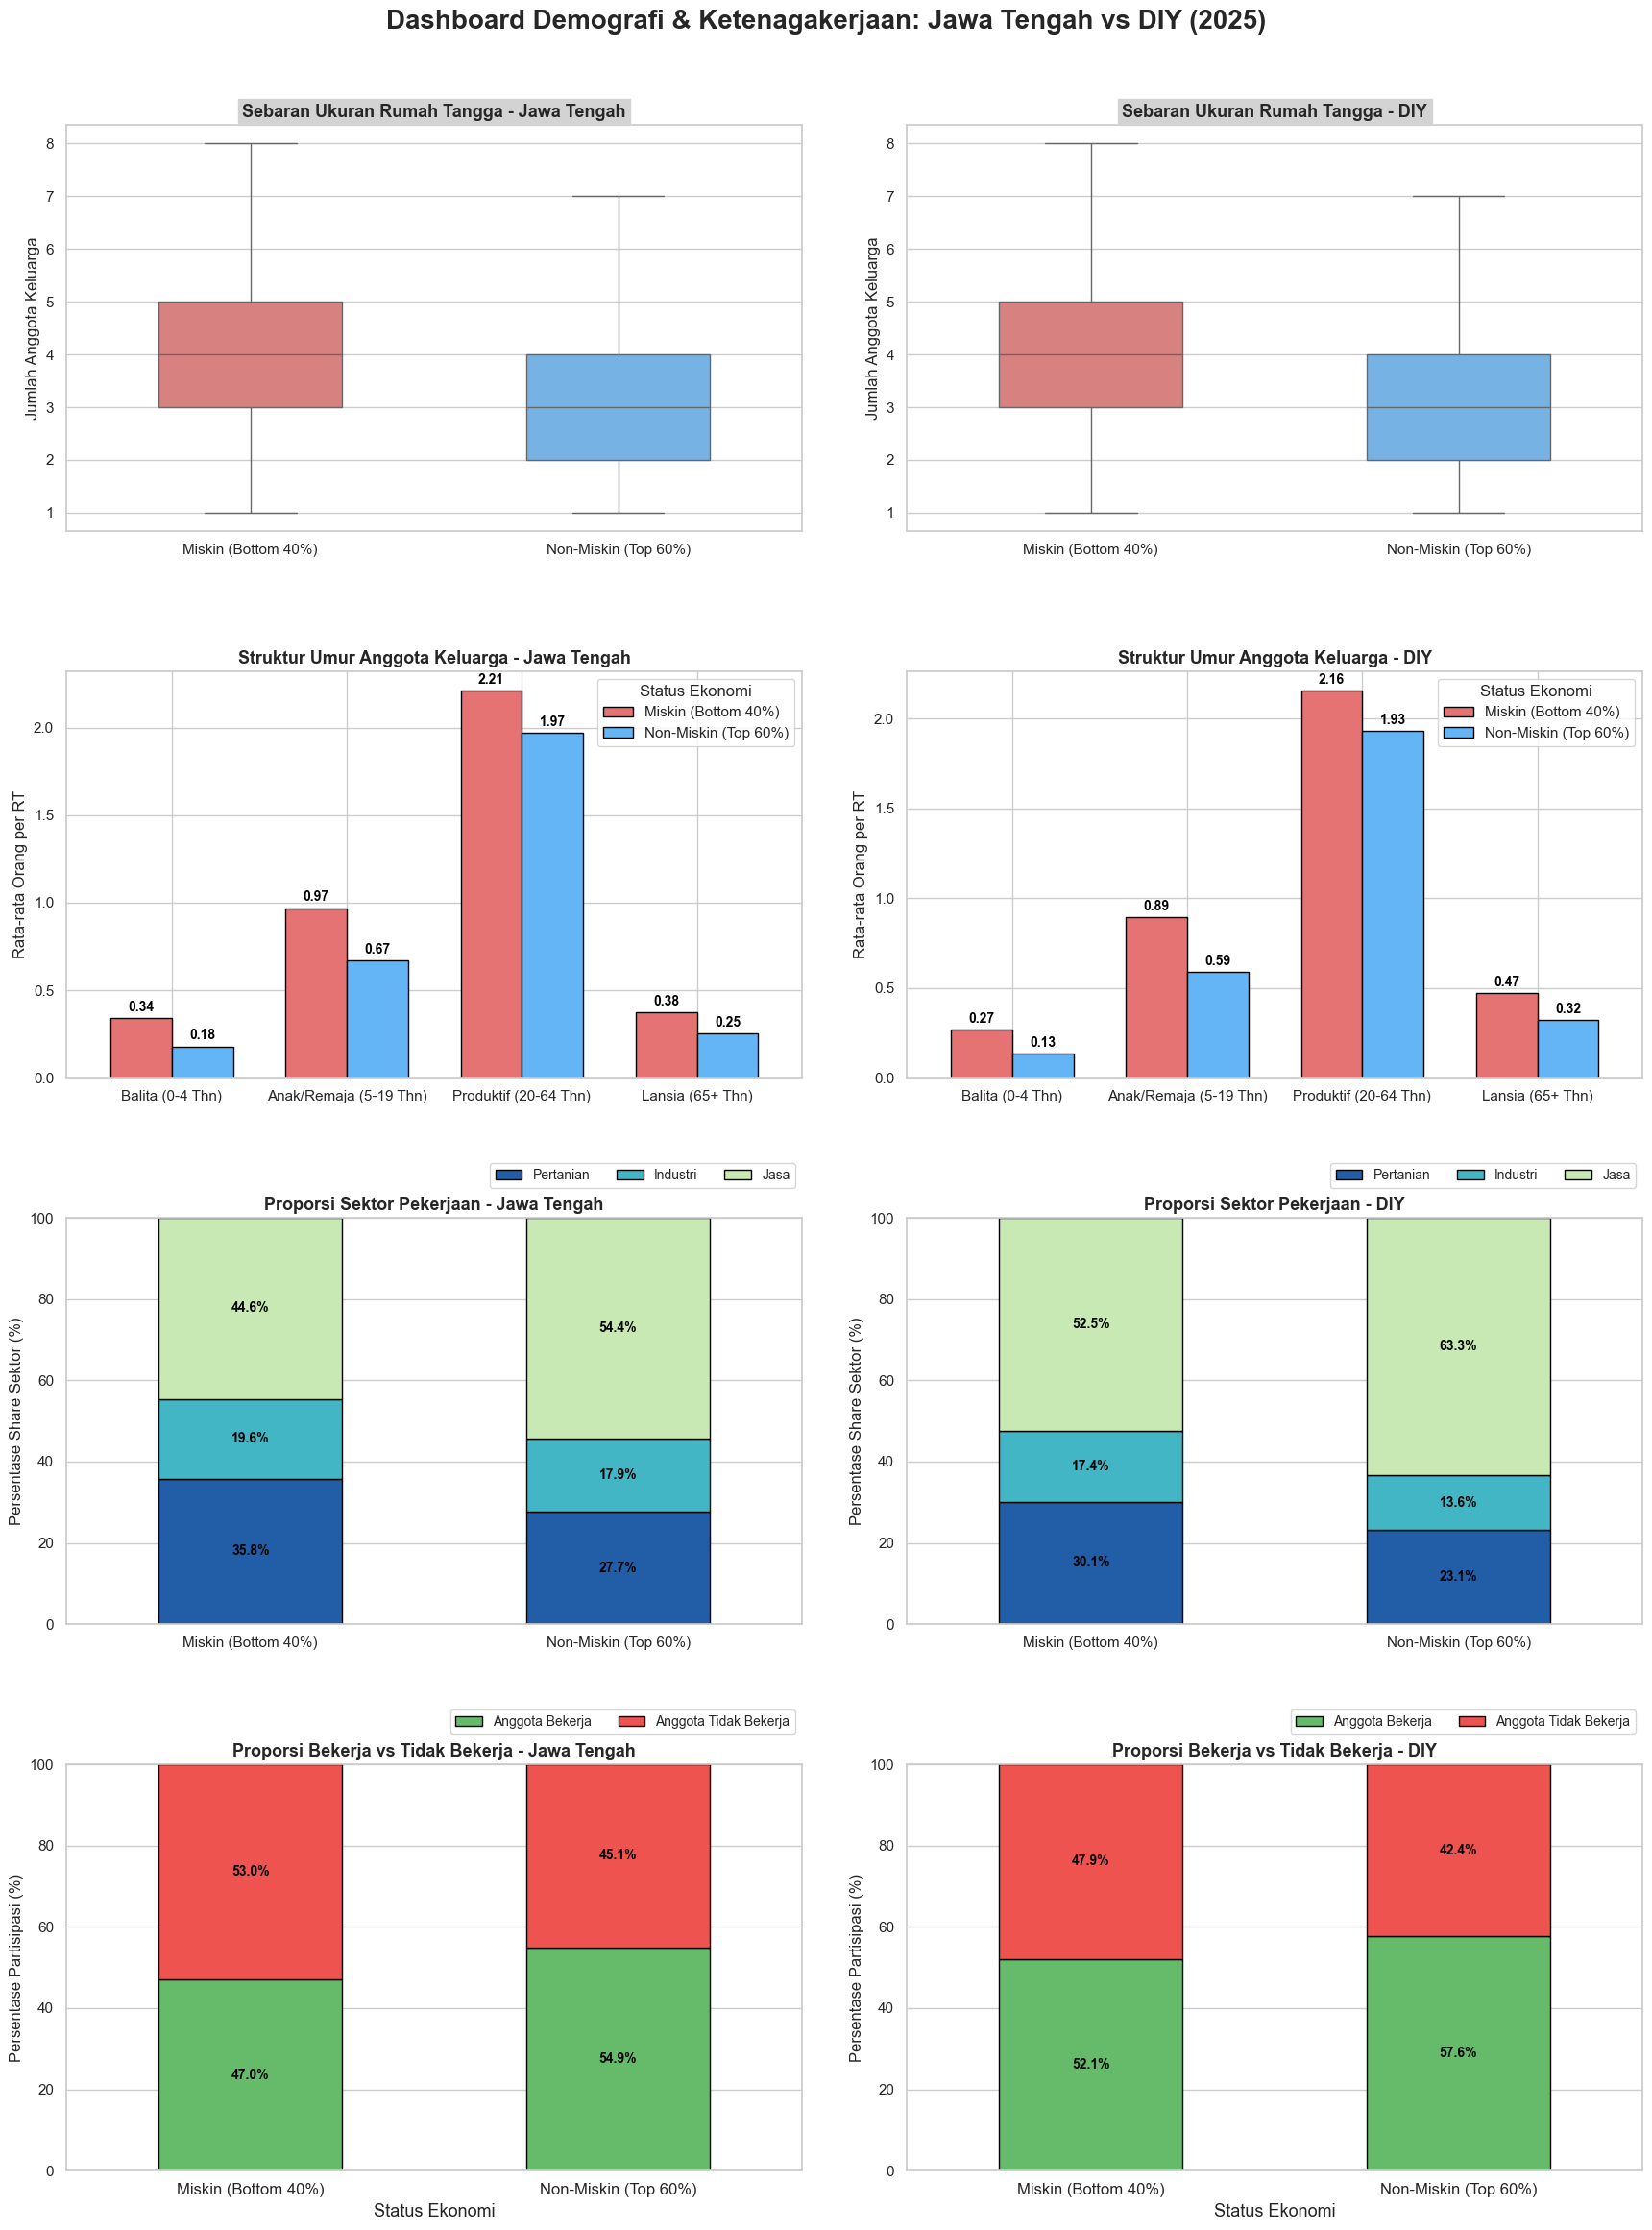


TABEL RINGKASAN PROPORSI DATA DEMOGRAFI & KETENAGAKERJAAN (2025)

--- A. KARAKTERISTIK DEMOGRAFI & STRUKTUR UMUR (Rata-rata Orang) ---
                                  Balita (0-4 Thn)  Anak/Remaja (5-19 Thn)  Produktif (20-64 Thn)  Lansia (65+ Thn)
Provinsi    Status                                                                                                 
DIY         Miskin (Bottom 40%)               0.27                    0.89                   2.16              0.47
            Non-Miskin (Top 60%)              0.13                    0.59                   1.93              0.32
Jawa Tengah Miskin (Bottom 40%)               0.34                    0.97                   2.21              0.38
            Non-Miskin (Top 60%)              0.18                    0.67                   1.97              0.25

--- B. DISTRIBUSI SEKTOR PEKERJAAN (%) ---
                                  Pertanian  Industri  Jasa
Provinsi    Status                                         
DIY 

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
import warnings

warnings.filterwarnings("ignore")

# ==============================================================================
# 1. FUNGSI PENDUKUNG
# ==============================================================================
def compute_decile_ranks(predictions):
    predictions = np.array(predictions)
    sorted_indices = np.argsort(predictions)
    ranks = np.zeros(len(predictions), dtype=np.int32)
    num_samples = len(predictions)
    decile_size = num_samples // 10
    for i in range(10):
        start_idx = i * decile_size
        end_idx = (i + 1) * decile_size if i < 9 else num_samples
        ranks[sorted_indices[start_idx:end_idx]] = i
    return ranks

def compute_group(df):
    if 'decile' not in df.columns:
        df['decile'] = compute_decile_ranks(df['pcexp'])
    df['group40'] = np.where(df['decile'] <= 3, 0, 1)
    return df

def add_labels_stacked(ax):
    for p in ax.patches:
        height = p.get_height()
        if height > 2.5: # Hanya tampilkan angka jika proporsi > 2.5% agar teks tidak bertumpuk
            x = p.get_x() + p.get_width() / 2
            y = p.get_y() + height / 2
            ax.text(x, y, f'{height:.1f}%', ha='center', va='center', color='black', weight='bold', fontsize=10)

def add_labels_grouped(ax):
    for p in ax.patches:
        height = p.get_height()
        if height > 0.05:
            ax.annotate(f'{height:.2f}', (p.get_x() + p.get_width() / 2, height), 
                        ha='center', va='bottom', color='black', weight='bold', fontsize=10,
                        xytext=(0, 3), textcoords='offset points')

# ==============================================================================
# 2. LOAD DATA (KHUSUS 2025) & EKSTRAK PROVINSI
# ==============================================================================
work_dir = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/'
years = [2022]

print("Membaca data Susenas untuk EDA Demografi & Ketenagakerjaan (2025)...")
dfs = []
for y in years:
    file_path = os.path.join(work_dir, f'susenas_final_{y}.csv')
    if os.path.exists(file_path):
        print(f"Loading {y}...")
        df_temp = pd.read_csv(file_path)
        df_temp['year'] = y
        dfs.append(df_temp)
    else:
        print(f"Warning: File {file_path} tidak ditemukan.")

if not dfs:
    raise FileNotFoundError("Tidak ada file susenas_final_2025.csv yang berhasil dimuat.")

df = pd.concat(dfs, ignore_index=True)

# Membuat kolom Provinsi berdasarkan kode_kab
if 'kode_prov' not in df.columns and 'kode_kab' in df.columns:
    df['kode_prov'] = df['kode_kab'] // 100
    
df['Provinsi'] = df['kode_prov'].map({33: 'Jawa Tengah', 34: 'DIY'})

# Hitung ulang desil
df = compute_group(df)
df['Status'] = df['group40'].map({0: 'Miskin (Bottom 40%)', 1: 'Non-Miskin (Top 60%)'})

status_order = ['Miskin (Bottom 40%)', 'Non-Miskin (Top 60%)']
prov_order = ['Jawa Tengah', 'DIY']
colors_status = ['#E57373', '#64B5F6'] 

demo_cols = ['h_hhcount', 'h_nage04', 'h_nage519', 'h_nage2064', 'h_nage65up']
df[demo_cols] = df[demo_cols].fillna(0)

# ==============================================================================
# 3. TRANSFORMASI DATA (Agregasi Berdasarkan Provinsi & Status)
# ==============================================================================
sec1_cols = [f'h_sec1_stat{i}' for i in range(1, 7) if f'h_sec1_stat{i}' in df.columns]
sec2_cols = [f'h_sec2_stat{i}' for i in range(1, 7) if f'h_sec2_stat{i}' in df.columns]
sec3_cols = [f'h_sec3_stat{i}' for i in range(1, 7) if f'h_sec3_stat{i}' in df.columns]

df['Pertanian'] = df[sec1_cols].sum(axis=1)
df['Industri'] = df[sec2_cols].sum(axis=1)
df['Jasa'] = df[sec3_cols].sum(axis=1)

df['Total_Bekerja'] = df['Pertanian'] + df['Industri'] + df['Jasa']
df['Tidak_Bekerja'] = df['h_hhcount'] - df['Total_Bekerja']
df['Tidak_Bekerja'] = np.where(df['Tidak_Bekerja'] < 0, 0, df['Tidak_Bekerja'])

# Agregasi Demografi Umur
df_age = df.groupby(['Provinsi', 'Status'])[['h_nage04', 'h_nage519', 'h_nage2064', 'h_nage65up']].mean()
df_age.columns = ['Balita (0-4 Thn)', 'Anak/Remaja (5-19 Thn)', 'Produktif (20-64 Thn)', 'Lansia (65+ Thn)']

# Agregasi Persentase Sektor
df_sec = df.groupby(['Provinsi', 'Status'])[['Pertanian', 'Industri', 'Jasa']].mean()
df_sec_pct = df_sec.div(df_sec.sum(axis=1), axis=0) * 100

# Agregasi Persentase Partisipasi Kerja
df_kerja = df.groupby(['Provinsi', 'Status'])[['Total_Bekerja', 'Tidak_Bekerja']].mean()
df_kerja_pct = df_kerja.div(df_kerja.sum(axis=1), axis=0) * 100
df_kerja_pct.columns = ['Anggota Bekerja', 'Anggota Tidak Bekerja']

# ==============================================================================
# 4. VISUALISASI 4x2 DASHBOARD (Jateng vs DIY)
# ==============================================================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(4, 2, figsize=(18, 24)) # Layout 4 Baris, 2 Kolom
fig.suptitle('Dashboard Demografi & Ketenagakerjaan: Jawa Tengah vs DIY (2025)', fontsize=20, fontweight='bold', y=0.98)

# Konstanta Pengaturan Tampilan
bar_width = 0.5 
colors_sec = sns.color_palette('YlGnBu_r', n_colors=3)
colors_kerja = ['#66BB6A', '#EF5350'] 

for col_idx, prov in enumerate(prov_order):
    # Mengatur Judul Kolom (Provinsi) di bagian paling atas plot
    axes[0, col_idx].set_title(f"PROVINSI {prov.upper()}", fontsize=16, fontweight='bold', pad=20, backgroundcolor='lightgray')
    
    # --- BARIS 1: BOXPLOT UKURAN RUMAH TANGGA ---
    sns.boxplot(data=df[df['Provinsi'] == prov], x='Status', y='h_hhcount', ax=axes[0, col_idx], 
                palette=colors_status, order=status_order, showfliers=False, width=bar_width)
    axes[0, col_idx].set_ylabel('Jumlah Anggota Keluarga', fontsize=12)
    axes[0, col_idx].set_xlabel('')
    axes[0, col_idx].set_title(f'Sebaran Ukuran Rumah Tangga - {prov}', fontsize=13, fontweight='bold')

    # --- BARIS 2: GROUPED BAR CHART (STRUKTUR UMUR) ---
    df_age_prov = df_age.loc[prov].T[status_order]
    df_age_prov.plot(kind='bar', ax=axes[1, col_idx], color=colors_status, edgecolor='black', width=0.7)
    axes[1, col_idx].set_ylabel('Rata-rata Orang per RT', fontsize=12)
    axes[1, col_idx].set_xlabel('')
    axes[1, col_idx].set_title(f'Struktur Umur Anggota Keluarga - {prov}', fontsize=13, fontweight='bold')
    axes[1, col_idx].tick_params(axis='x', rotation=0)
    add_labels_grouped(axes[1, col_idx])
    axes[1, col_idx].legend(title='Status Ekonomi')

    # --- BARIS 3: 100% STACKED BAR (SEKTOR PEKERJAAN) ---
    df_sec_prov = df_sec_pct.loc[prov].loc[status_order]
    df_sec_prov.plot(kind='bar', stacked=True, ax=axes[2, col_idx], color=colors_sec, edgecolor='black', width=bar_width)
    axes[2, col_idx].set_ylabel('Persentase Share Sektor (%)', fontsize=12)
    axes[2, col_idx].set_xlabel('')
    axes[2, col_idx].set_ylim(0, 100)
    axes[2, col_idx].set_title(f'Proporsi Sektor Pekerjaan - {prov}', fontsize=13, fontweight='bold')
    axes[2, col_idx].tick_params(axis='x', rotation=0)
    add_labels_stacked(axes[2, col_idx])
    axes[2, col_idx].legend(loc='upper right', bbox_to_anchor=(1, 1.15), ncol=3, fontsize=10)

    # --- BARIS 4: 100% STACKED BAR (PARTISIPASI KERJA) ---
    df_kerja_prov = df_kerja_pct.loc[prov].loc[status_order]
    df_kerja_prov.plot(kind='bar', stacked=True, ax=axes[3, col_idx], color=colors_kerja, edgecolor='black', width=bar_width)
    axes[3, col_idx].set_ylabel('Persentase Partisipasi (%)', fontsize=12)
    axes[3, col_idx].set_xlabel('Status Ekonomi', fontsize=13)
    axes[3, col_idx].set_ylim(0, 100)
    axes[3, col_idx].set_title(f'Proporsi Bekerja vs Tidak Bekerja - {prov}', fontsize=13, fontweight='bold')
    axes[3, col_idx].tick_params(axis='x', rotation=0, labelsize=12)
    add_labels_stacked(axes[3, col_idx])
    axes[3, col_idx].legend(loc='upper right', bbox_to_anchor=(1, 1.15), ncol=2, fontsize=10)

plt.tight_layout(pad=3.0, h_pad=4.0, w_pad=3.0)
plt.subplots_adjust(top=0.93) # Memberi ruang untuk Super Title
plt.show()

# ==============================================================================
# 5. TABEL RINGKASAN & STATISTIK DESKRIPTIF DETAIL (DIPISAH PROVINSI)
# ==============================================================================
print("\n" + "="*90)
print("TABEL RINGKASAN PROPORSI DATA DEMOGRAFI & KETENAGAKERJAAN (2025)")
print("="*90)

print("\n--- A. KARAKTERISTIK DEMOGRAFI & STRUKTUR UMUR (Rata-rata Orang) ---")
print(df_age.round(2))

print("\n--- B. DISTRIBUSI SEKTOR PEKERJAAN (%) ---")
print(df_sec_pct.round(1))

print("\n--- C. STATUS PARTISIPASI KERJA (%) ---")
print(df_kerja_pct.round(1))

# --- D. TABEL STATISTIK DESKRIPTIF DETAIL ---
print("\n" + "="*90)
print("--- D. ANALISIS STATISTIK DESKRIPTIF DETAIL PER PROVINSI & STATUS ---")
print("="*90)

target_vars = ['h_hhcount', 'h_nage04', 'h_nage519', 'h_nage2064', 'h_nage65up', 
               'Pertanian', 'Industri', 'Jasa', 'Total_Bekerja', 'Tidak_Bekerja']

desc_list = []
for prov in prov_order:
    for status_val in status_order:
        sub_df = df[(df['Provinsi'] == prov) & (df['Status'] == status_val)][target_vars]
        stat_df = pd.DataFrame({
            'Mean': sub_df.mean(),
            'Min': sub_df.min(),
            'Max': sub_df.max(),
            'Std Dev': sub_df.std()
        }).T
        stat_df.index = pd.MultiIndex.from_tuples([(prov, status_val, metric) for metric in stat_df.index], 
                                                  names=['Provinsi', 'Status', 'Metric'])
        desc_list.append(stat_df)

desc_final = pd.concat(desc_list)
pd.set_option('display.max_columns', 15)
pd.set_option('display.width', 1000)
print(desc_final.round(3))
print("="*90)

## PENDIDIKAN

Membaca data Susenas untuk EDA Pendidikan (2025)...


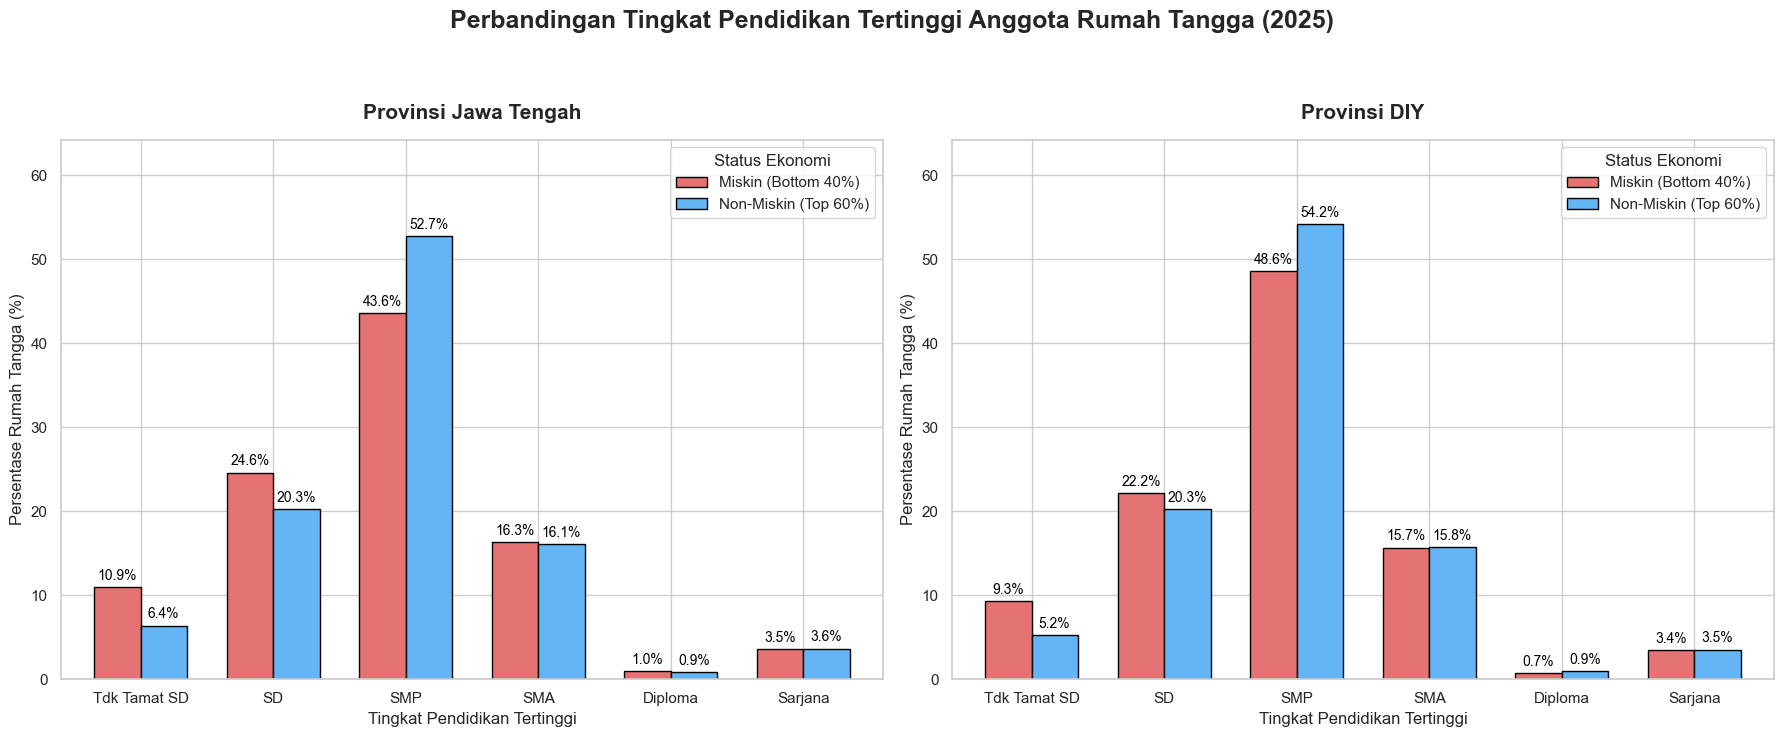


--- A. RINGKASAN PERSENTASE PENDIDIKAN (%) [PER PROVINSI] ---
                                  Tdk Tamat SD     SD    SMP    SMA  Diploma  Sarjana
Provinsi    Status                                                                   
DIY         Miskin (Bottom 40%)          9.32% 22.21% 48.63% 15.67%    0.74%    3.44%
            Non-Miskin (Top 60%)         5.22% 20.31% 54.25% 15.77%    0.92%    3.53%
Jawa Tengah Miskin (Bottom 40%)         10.93% 24.60% 43.62% 16.34%    0.95%    3.55%
            Non-Miskin (Top 60%)         6.38% 20.29% 52.74% 16.06%    0.89%    3.64%

--- B. TABEL ANALISIS STATISTIK DESKRIPTIF DETAIL PENDIDIKAN (SATUAN ORANG) ---
                                               Tdk Tamat SD     SD     SMP    SMA  Diploma  Sarjana
Provinsi    Status               Metric                                                            
Jawa Tengah Miskin (Bottom 40%)  Mean (Orang)        0.1381 0.3108  0.5511 0.2064   0.0120   0.0448
                                 Min    

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
import warnings

warnings.filterwarnings("ignore")

# ==============================================================================
# 1. FUNGSI PENDUKUNG 
# ==============================================================================
def compute_decile_ranks(predictions):
    predictions = np.array(predictions)
    sorted_indices = np.argsort(predictions)
    ranks = np.zeros(len(predictions), dtype=np.int32)
    num_samples = len(predictions)
    decile_size = num_samples // 10
    for i in range(10):
        start_idx = i * decile_size
        end_idx = (i + 1) * decile_size if i < 9 else num_samples
        ranks[sorted_indices[start_idx:end_idx]] = i
    return ranks

def compute_group(df):
    if 'decile' not in df.columns:
        df['decile'] = compute_decile_ranks(df['pcexp'])
    df['group40'] = np.where(df['decile'] <= 3, 0, 1)
    return df

def add_labels_grouped(ax):
    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            ax.annotate(f'{height:.1f}%', 
                        (p.get_x() + p.get_width() / 2., height), 
                        ha='center', va='bottom', 
                        fontsize=10, color='black', 
                        xytext=(0, 3), 
                        textcoords='offset points')

# ==============================================================================
# 2. LOAD DATA (KHUSUS 2025) & EKSTRAK PROVINSI
# ==============================================================================
work_dir = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/'
years = [2025] # Dialihkan ke 2025 saja agar grafik stabil terbebas dari missing values 2024

print("Membaca data Susenas untuk EDA Pendidikan (2025)...")
dfs = []
for y in years:
    filename = f'susenas_final_{y}.csv'
    filepath = os.path.join(work_dir, filename)
    if os.path.exists(filepath):
        df_temp = pd.read_csv(filepath)
        df_temp['year'] = y
        dfs.append(df_temp)
    else:
        print(f" [WARNING] File tidak ditemukan: {filename}")

if not dfs:
    raise FileNotFoundError("Tidak ada satupun file susenas_final_*.csv yang ditemukan di direktori!")

df = pd.concat(dfs, ignore_index=True)

# Membuat kolom Provinsi berdasarkan kode_kab
if 'kode_prov' not in df.columns and 'kode_kab' in df.columns:
    df['kode_prov'] = df['kode_kab'] // 100
    
df['Provinsi'] = df['kode_prov'].map({33: 'Jawa Tengah', 34: 'DIY'})

# Tentukan kelompok pengeluaran (group40)
df = compute_group(df)
df['Status'] = df['group40'].map({0: 'Miskin (Bottom 40%)', 1: 'Non-Miskin (Top 60%)'})

status_order = ['Miskin (Bottom 40%)', 'Non-Miskin (Top 60%)']
prov_order = ['Jawa Tengah', 'DIY']

# ==============================================================================
# 3. TRANSFORMASI DATA ONE-HOT ENCODING (PENDIDIKAN)
# ==============================================================================
edu_cols = ['h_notgrad', 'h_ngrad_sd', 'h_ngrad_smp', 'h_ngrad_sma', 'h_ngrad_d', 'h_ngrad_s']
edu_labels = ['Tdk Tamat SD', 'SD', 'SMP', 'SMA', 'Diploma', 'Sarjana']

for col in edu_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)
    else:
        df[col] = 0

# Grouping dengan menambahkan dimensi Provinsi
df_edu = df.groupby(['Provinsi', 'Status'])[edu_cols].mean() * 100
# Normalisasi total baris agar pas 100%
df_edu = df_edu.div(df_edu.sum(axis=1), axis=0) * 100
df_edu.columns = edu_labels

# ==============================================================================
# 4. VISUALISASI BAR CHART BERJEJER (1 Baris x 2 Kolom)
# ==============================================================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Perbandingan Tingkat Pendidikan Tertinggi Anggota Rumah Tangga (2025)', fontsize=18, fontweight='bold', y=1.05)

colors_status = ['#E57373', '#64B5F6']

for i, prov in enumerate(prov_order):
    df_edu_prov = df_edu.loc[prov].T[status_order]
    
    df_edu_prov.plot(
        kind='bar', 
        ax=axes[i], 
        color=colors_status, 
        edgecolor='black', 
        width=0.7
    )
    
    axes[i].set_title(f'Provinsi {prov}', fontsize=15, fontweight='bold', pad=15)
    axes[i].set_ylabel('Persentase Rumah Tangga (%)', fontsize=12)
    axes[i].set_xlabel('Tingkat Pendidikan Tertinggi', fontsize=12)
    axes[i].tick_params(axis='x', rotation=0, labelsize=11)
    
    # Kunci batas atas Y agar kedua grafik memiliki skala perbandingan yang identik
    axes[i].set_ylim(0, max(df_edu.max()) + 10) 
    axes[i].legend(title='Status Ekonomi', fontsize=11, title_fontsize=12)
    
    add_labels_grouped(axes[i])

plt.tight_layout()
plt.show()

# ==============================================================================
# 5. RINGKASAN & TABEL ANALISIS STATISTIK DESKRIPTIF DETAIL (PER PROVINSI)
# ==============================================================================
print("\n" + "="*90)
print("--- A. RINGKASAN PERSENTASE PENDIDIKAN (%) [PER PROVINSI] ---")
print("="*90)
pd.set_option('display.float_format', lambda x: '%.2f%%' % x)
print(df_edu)

print("\n" + "="*90)
print("--- B. TABEL ANALISIS STATISTIK DESKRIPTIF DETAIL PENDIDIKAN (SATUAN ORANG) ---")
print("="*90)

desc_list = []
for prov in prov_order:
    for status_val in status_order:
        sub_df = df[(df['Provinsi'] == prov) & (df['Status'] == status_val)][edu_cols]
        
        stat_df = pd.DataFrame({
            'Mean (Orang)': sub_df.mean(),
            'Min': sub_df.min(),
            'Max': sub_df.max(),
            'Std Dev': sub_df.std(),
            'Variance': sub_df.var(),
            'Skewness': sub_df.skew(),
            'Kurtosis': sub_df.kurt()
        }).T
        
        stat_df.index = pd.MultiIndex.from_tuples([(prov, status_val, metric) for metric in stat_df.index], 
                                                  names=['Provinsi', 'Status', 'Metric'])
        
        stat_df.columns = edu_labels
        desc_list.append(stat_df)

desc_final = pd.concat(desc_list)

pd.set_option('display.float_format', '{:,.4f}'.format)
pd.set_option('display.max_columns', 15)
pd.set_option('display.width', 1000)
print(desc_final)
print("="*90)

Membaca data Susenas untuk EDA Partisipasi Sekolah (2025)...


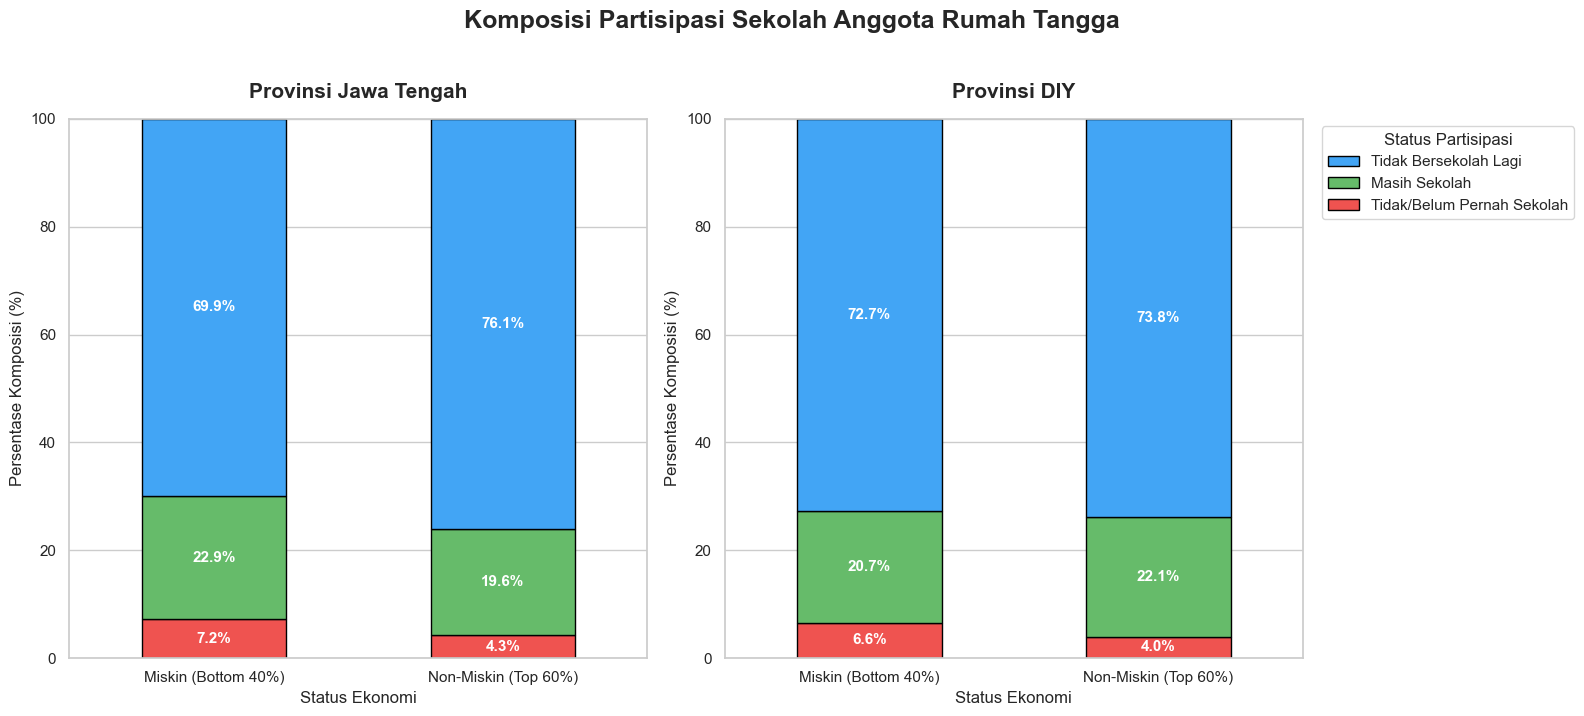


--- A. RINGKASAN KOMPOSISI PARTISIPASI SEKOLAH (%) [PER PROVINSI] ---
                                  Tidak/Belum Pernah Sekolah  Masih Sekolah  Tidak Bersekolah Lagi
Provinsi    Status                                                                                
DIY         Miskin (Bottom 40%)                        6.62%         20.71%                 72.67%
            Non-Miskin (Top 60%)                       4.02%         22.13%                 73.85%
Jawa Tengah Miskin (Bottom 40%)                        7.19%         22.87%                 69.93%
            Non-Miskin (Top 60%)                       4.26%         19.64%                 76.10%

--- B. TABEL ANALISIS STATISTIK DESKRIPTIF DETAIL (JUMLAH ORANG) ---
                                               Tidak/Belum Pernah Sekolah  Masih Sekolah  Tidak Bersekolah Lagi
Provinsi    Status               Metric                                                                        
Jawa Tengah Miskin (Bottom 40%)  Mean (Or

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
import warnings

warnings.filterwarnings("ignore")

# ==============================================================================
# 1. FUNGSI PENDUKUNG 
# ==============================================================================
def compute_decile_ranks(predictions):
    predictions = np.array(predictions)
    sorted_indices = np.argsort(predictions)
    ranks = np.zeros(len(predictions), dtype=np.int32)
    num_samples = len(predictions)
    decile_size = num_samples // 10
    for i in range(10):
        start_idx = i * decile_size
        end_idx = (i + 1) * decile_size if i < 9 else num_samples
        ranks[sorted_indices[start_idx:end_idx]] = i
    return ranks

def compute_group(df):
    if 'decile' not in df.columns:
        df['decile'] = compute_decile_ranks(df['pcexp'])
    df['group40'] = np.where(df['decile'] <= 3, 0, 1)
    return df

# ==============================================================================
# 2. LOAD DATA (KHUSUS 2025) & EKSTRAK PROVINSI
# ==============================================================================
work_dir = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/'
years = [2025] 

print("Membaca data Susenas untuk EDA Partisipasi Sekolah (2025)...")
dfs = []
for y in years:
    filename = f'susenas_clean_{y}.csv'
    filepath = os.path.join(work_dir, filename)
    if os.path.exists(filepath):
        df_temp = pd.read_csv(filepath)
        df_temp['year'] = y
        dfs.append(df_temp)
    else:
        print(f" [WARNING] File tidak ditemukan: {filename}")

if not dfs:
    raise FileNotFoundError("Tidak ada satupun file susenas_final_*.csv yang ditemukan di direktori!")

df = pd.concat(dfs, ignore_index=True)

# Ekstrak Provinsi dari kode_kab
if 'kode_prov' not in df.columns and 'kode_kab' in df.columns:
    df['kode_prov'] = df['kode_kab'] // 100
    
df['Provinsi'] = df['kode_prov'].map({33: 'Jawa Tengah', 34: 'DIY'})

# Tentukan kelompok pengeluaran (group40)
df = compute_group(df)
df['Status'] = df['group40'].map({0: 'Miskin (Bottom 40%)', 1: 'Non-Miskin (Top 60%)'})

status_order = ['Miskin (Bottom 40%)', 'Non-Miskin (Top 60%)']
prov_order = ['Jawa Tengah', 'DIY']

# ==============================================================================
# 3. TRANSFORMASI DATA (KOMPOSISI 100%)
# ==============================================================================
# Menggunakan jumlah orang (count) alih-alih biner
raw_part_cols = ['h_neverschool', 'h_stillschool', 'h_notschool']
part_labels = ['Tidak/Belum Pernah Sekolah', 'Masih Sekolah', 'Tidak Bersekolah Lagi']

for col in raw_part_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)
    else:
        df[col] = 0

# Menghitung Rata-rata Jumlah Orang per Kategori berdasarkan Provinsi & Status
df_part_mean = df.groupby(['Provinsi', 'Status'])[raw_part_cols].mean()

# Normalisasi menjadi 100% (Membagi nilai tiap kolom dengan total baris tersebut)
df_part_pct = df_part_mean.div(df_part_mean.sum(axis=1), axis=0) * 100
df_part_pct.columns = part_labels

# ==============================================================================
# 4. VISUALISASI 100% STACKED BAR CHART BERJEJER
# ==============================================================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Komposisi Partisipasi Sekolah Anggota Rumah Tangga', fontsize=18, fontweight='bold', y=1.02)

colors = ['#EF5350', '#66BB6A', '#42A5F5']

for i, prov in enumerate(prov_order):
    # Filter data per provinsi
    df_part_prov = df_part_pct.loc[prov].loc[status_order]
    
    # Plot Stacked Bar
    df_part_prov.plot(
        kind='bar', 
        stacked=True, 
        ax=axes[i], 
        color=colors, 
        edgecolor='black', 
        width=0.5
    )
    
    axes[i].set_title(f'Provinsi {prov}', fontsize=15, fontweight='bold', pad=15)
    axes[i].set_ylabel('Persentase Komposisi (%)', fontsize=12)
    axes[i].set_xlabel('Status Ekonomi', fontsize=12)
    axes[i].tick_params(axis='x', rotation=0, labelsize=11)
    axes[i].set_ylim(0, 100)
    
    # Menambahkan teks angka ke dalam tumpukan bar
    for p in axes[i].patches:
        height = p.get_height()
        if height > 2.5: # Cegah teks bertumpuk jika persentase terlalu kecil
            x = p.get_x() + p.get_width() / 2
            y = p.get_y() + height / 2
            axes[i].text(x, y, f'{height:.1f}%', ha='center', va='center', color='white', fontweight='bold', fontsize=11)
    
    # Atur Legend agar hanya muncul di grafik sebelah kanan
    if i == 1:
        handles, labels = axes[i].get_legend_handles_labels()
        # Membalik urutan legend agar sesuai urutan blok dari atas ke bawah
        axes[i].legend(reversed(handles), reversed(labels), title='Status Partisipasi', bbox_to_anchor=(1.02, 1), loc='upper left')
    else:
        axes[i].get_legend().remove()

plt.tight_layout()
plt.show()

# ==============================================================================
# 5. RINGKASAN PERSENTASE & TABEL ANALISIS STATISTIK DESKRIPTIF
# ==============================================================================
print("\n" + "="*90)
print("--- A. RINGKASAN KOMPOSISI PARTISIPASI SEKOLAH (%) [PER PROVINSI] ---")
print("="*90)
pd.set_option('display.float_format', lambda x: '%.2f%%' % x)
print(df_part_pct)

print("\n" + "="*90)
print("--- B. TABEL ANALISIS STATISTIK DESKRIPTIF DETAIL (JUMLAH ORANG) ---")
print("="*90)

desc_list = []
for prov in prov_order:
    for status_val in status_order:
        sub_df = df[(df['Provinsi'] == prov) & (df['Status'] == status_val)][raw_part_cols]
        
        stat_df = pd.DataFrame({
            'Mean (Orang)': sub_df.mean(),
            'Min': sub_df.min(),
            'Max': sub_df.max(),
            'Std Dev': sub_df.std(),
            'Variance': sub_df.var(),
            'Skewness': sub_df.skew(),
            'Kurtosis': sub_df.kurt()
        }).T
        
        stat_df.index = pd.MultiIndex.from_tuples([(prov, status_val, metric) for metric in stat_df.index], 
                                                  names=['Provinsi', 'Status', 'Metric'])
        stat_df.columns = part_labels
        desc_list.append(stat_df)

desc_final = pd.concat(desc_list)
pd.set_option('display.float_format', '{:,.4f}'.format)
pd.set_option('display.max_columns', 15)
pd.set_option('display.width', 1000)
print(desc_final)
print("="*90)

## ASET

Membaca data Susenas untuk EDA Kepemilikan Aset (2025)...


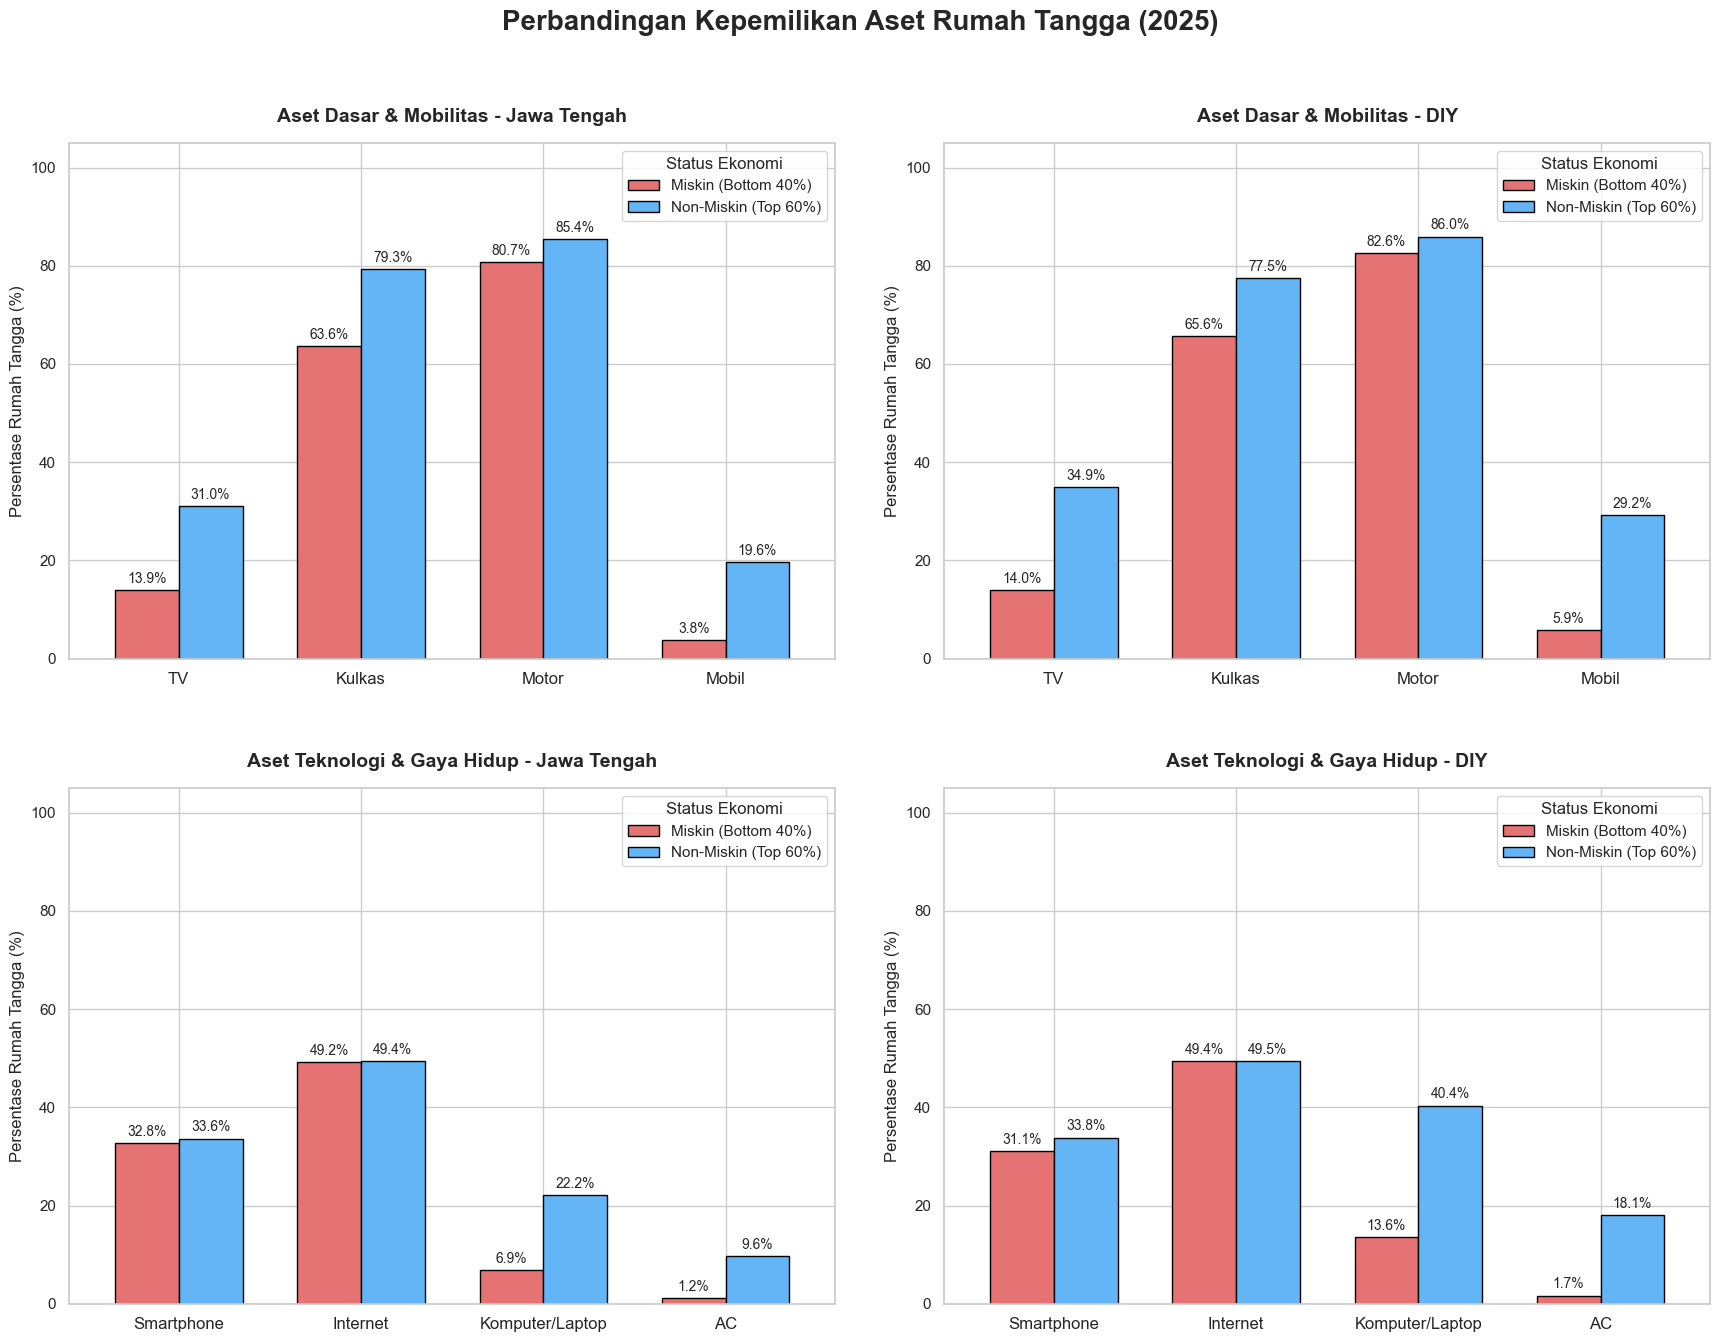


--- RINGKASAN PERSENTASE KEPEMILIKAN ASET (%) [PER PROVINSI] ---

1. Mobilitas & Elektronik Dasar:
                                     TV  Kulkas  Motor  Mobil
Provinsi    Status                                           
DIY         Miskin (Bottom 40%)  13.97%  65.62% 82.59%  5.87%
            Non-Miskin (Top 60%) 34.92%  77.52% 85.96% 29.19%
Jawa Tengah Miskin (Bottom 40%)  13.94%  63.57% 80.68%  3.79%
            Non-Miskin (Top 60%) 30.97%  79.27% 85.35% 19.56%

2. Teknologi & Gaya Hidup:
                                  Smartphone  Internet  Komputer/Laptop     AC
Provinsi    Status                                                            
DIY         Miskin (Bottom 40%)       31.06%    49.36%           13.58%  1.66%
            Non-Miskin (Top 60%)      33.83%    49.47%           40.36% 18.05%
Jawa Tengah Miskin (Bottom 40%)       32.80%    49.21%            6.88%  1.21%
            Non-Miskin (Top 60%)      33.62%    49.36%           22.17%  9.64%


In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
import warnings

warnings.filterwarnings("ignore")

# ==============================================================================
# 1. FUNGSI PENDUKUNG
# ==============================================================================
def compute_decile_ranks(predictions):
    predictions = np.array(predictions)
    sorted_indices = np.argsort(predictions)
    ranks = np.zeros(len(predictions), dtype=np.int32)
    num_samples = len(predictions)
    decile_size = num_samples // 10
    for i in range(10):
        start_idx = i * decile_size
        end_idx = (i + 1) * decile_size if i < 9 else num_samples
        ranks[sorted_indices[start_idx:end_idx]] = i
    return ranks

def compute_group(df):
    if 'decile' not in df.columns:
        df['decile'] = compute_decile_ranks(df['pcexp'])
    df['group40'] = np.where(df['decile'] <= 3, 0, 1)
    return df

def add_bar_labels(ax):
    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            ax.annotate(f'{height:.1f}%', (p.get_x() + p.get_width() / 2., height), 
                        ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

# ==============================================================================
# 2. LOAD DATA (KHUSUS 2025) & EKSTRAK PROVINSI
# ==============================================================================
work_dir = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/'
years = [2025] 
dfs = []

print("Membaca data Susenas untuk EDA Kepemilikan Aset (2025)...")
for y in years:
    filename = f'susenas_final_{y}.csv'
    filepath = os.path.join(work_dir, filename)
    if os.path.exists(filepath):
        df_temp = pd.read_csv(filepath)
        df_temp['year'] = y
        dfs.append(df_temp)
    else:
        print(f" [WARNING] File tidak ditemukan: {filename}")

if not dfs:
    raise FileNotFoundError("Tidak ada satupun file susenas_final_*.csv yang ditemukan di direktori!")

df = pd.concat(dfs, ignore_index=True)

# Ekstrak Provinsi dari kode_kab
if 'kode_prov' not in df.columns and 'kode_kab' in df.columns:
    df['kode_prov'] = df['kode_kab'] // 100
    
df['Provinsi'] = df['kode_prov'].map({33: 'Jawa Tengah', 34: 'DIY'})

# Tentukan kelompok pengeluaran
df = compute_group(df)
df['Status'] = df['group40'].map({0: 'Miskin (Bottom 40%)', 1: 'Non-Miskin (Top 60%)'})

status_order = ['Miskin (Bottom 40%)', 'Non-Miskin (Top 60%)']
prov_order = ['Jawa Tengah', 'DIY']

# ==============================================================================
# 3. TRANSFORMASI DATA ASET MENJADI PERSENTASE (%) PER PROVINSI
# ==============================================================================
aset_dasar_cols = ['h_asset_tv', 'h_asset_fridge', 'h_asset_motorcycle', 'h_asset_car']
aset_tech_cols = ['h_asset_smartphone', 'h_asset_internet', 'h_asset_computer', 'h_asset_ac']

all_asset_cols = aset_dasar_cols + aset_tech_cols
for col in all_asset_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)
    else:
        df[col] = 0 

# Agregasi MultiIndex: Provinsi dan Status
df_dasar = df.groupby(['Provinsi', 'Status'])[aset_dasar_cols].mean() * 100
df_dasar.columns = ['TV', 'Kulkas', 'Motor', 'Mobil']

aset_tech_ada = [col for col in aset_tech_cols if col in df.columns]
df_tech = df.groupby(['Provinsi', 'Status'])[aset_tech_ada].mean() * 100

nama_tech = {
    'h_asset_smartphone': 'Smartphone', 
    'h_asset_internet': 'Internet', 
    'h_asset_computer': 'Komputer/Laptop', 
    'h_asset_ac': 'AC'
}
df_tech.columns = [nama_tech[col] for col in aset_tech_ada]

# ==============================================================================
# 4. VISUALISASI 2x2 SUBPLOTS (BARIS 1: DASAR, BARIS 2: TEKNOLOGI)
# ==============================================================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
fig.suptitle('Perbandingan Kepemilikan Aset Rumah Tangga (2025)', fontsize=20, fontweight='bold', y=0.98)

colors_status = ['#E57373', '#64B5F6']

for i, prov in enumerate(prov_order):
    # --- BARIS 1: PLOT ASET DASAR (Kolom Kiri: Jateng, Kanan: DIY) ---
    df_dasar_prov = df_dasar.loc[prov].T[status_order]
    ax1 = df_dasar_prov.plot(kind='bar', ax=axes[0, i], color=colors_status, width=0.7, edgecolor='black')
    
    axes[0, i].set_title(f'Aset Dasar & Mobilitas - {prov}', fontsize=14, fontweight='bold', pad=15)
    axes[0, i].set_ylabel('Persentase Rumah Tangga (%)', fontsize=12)
    axes[0, i].set_xlabel('')
    axes[0, i].set_ylim(0, 105)
    axes[0, i].tick_params(axis='x', rotation=0, labelsize=12)
    axes[0, i].legend(title='Status Ekonomi', fontsize=11)
    add_bar_labels(ax1)

    # --- BARIS 2: PLOT ASET TEKNOLOGI (Kolom Kiri: Jateng, Kanan: DIY) ---
    df_tech_prov = df_tech.loc[prov].T[status_order]
    ax2 = df_tech_prov.plot(kind='bar', ax=axes[1, i], color=colors_status, width=0.7, edgecolor='black')
    
    axes[1, i].set_title(f'Aset Teknologi & Gaya Hidup - {prov}', fontsize=14, fontweight='bold', pad=15)
    axes[1, i].set_ylabel('Persentase Rumah Tangga (%)', fontsize=12)
    axes[1, i].set_xlabel('')
    axes[1, i].set_ylim(0, 105)
    axes[1, i].tick_params(axis='x', rotation=0, labelsize=12)
    axes[1, i].legend(title='Status Ekonomi', fontsize=11)
    add_bar_labels(ax2)

plt.tight_layout(pad=3.0, h_pad=4.0)
plt.show()

# ==============================================================================
# 5. TABEL ANGKA PASTI (PERSENTASE KEPEMILIKAN PER PROVINSI)
# ==============================================================================
print("\n" + "="*80)
print("--- RINGKASAN PERSENTASE KEPEMILIKAN ASET (%) [PER PROVINSI] ---")
print("="*80)
pd.set_option('display.float_format', lambda x: '%.2f%%' % x)

print("\n1. Mobilitas & Elektronik Dasar:")
print(df_dasar)

print("\n2. Teknologi & Gaya Hidup:")
print(df_tech)
print("="*80)

## PERUMAHAN

Membaca data Susenas untuk EDA Luas Lantai (2025)...


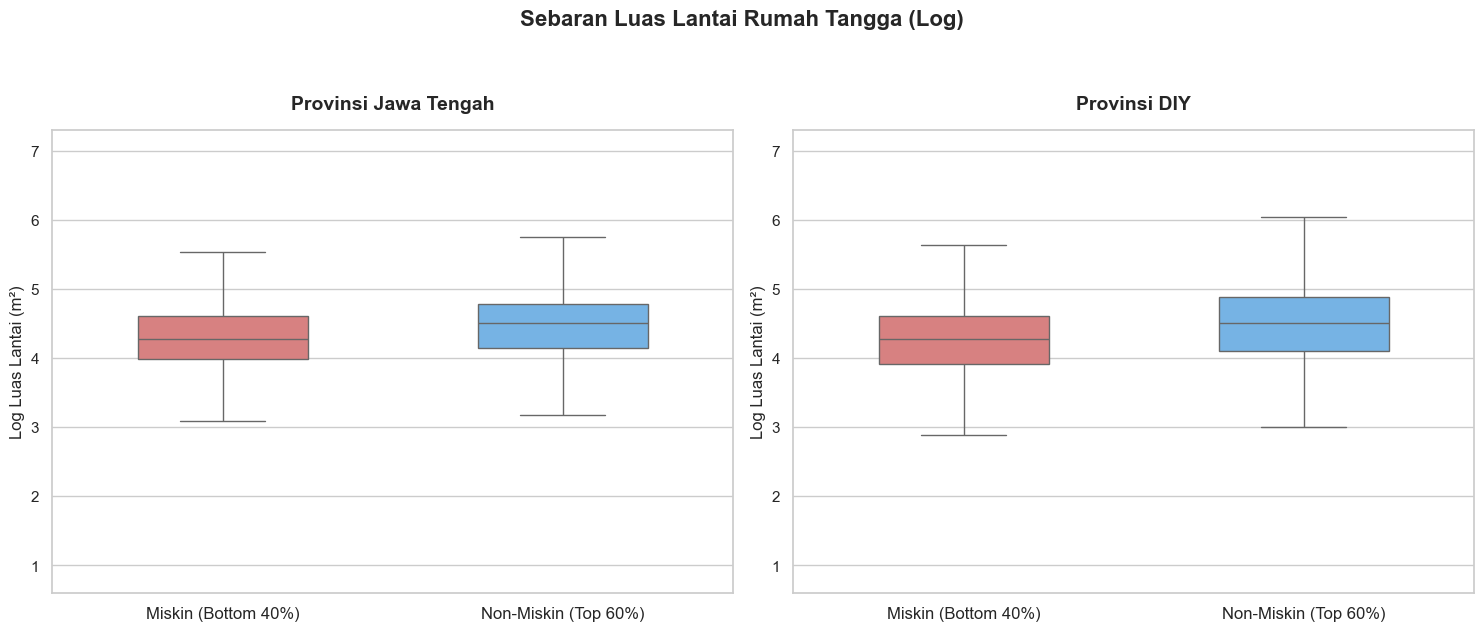


--- TABEL ANALISIS STATISTIK DESKRIPTIF: LOG LUAS LANTAI (2025) ---
                                   Mean    Min    Max  Std Dev  Variance  Skewness  Kurtosis
Provinsi    Status Ekonomi                                                                  
Jawa Tengah Miskin (Bottom 40%)  4.3186 1.6094 6.3969   0.5115    0.2617   -0.1125    1.4739
            Non-Miskin (Top 60%) 4.5107 1.3863 6.8024   0.5569    0.3102   -0.1143    1.6401
DIY         Miskin (Bottom 40%)  4.2154 1.6094 6.2146   0.6261    0.3921   -0.4979    1.2538
            Non-Miskin (Top 60%) 4.4037 1.0986 6.6593   0.8037    0.6460   -0.9025    1.3368


In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
import warnings

warnings.filterwarnings("ignore")

# ==============================================================================
# 1. FUNGSI PENDUKUNG
# ==============================================================================
def compute_decile_ranks(predictions):
    predictions = np.array(predictions)
    sorted_indices = np.argsort(predictions)
    ranks = np.zeros(len(predictions), dtype=np.int32)
    num_samples = len(predictions)
    decile_size = num_samples // 10
    for i in range(10):
        start_idx = i * decile_size
        end_idx = (i + 1) * decile_size if i < 9 else num_samples
        ranks[sorted_indices[start_idx:end_idx]] = i
    return ranks

def compute_group(df):
    if 'decile' not in df.columns:
        df['decile'] = compute_decile_ranks(df['pcexp'])
    df['group40'] = np.where(df['decile'] <= 3, 0, 1)
    return df

# ==============================================================================
# 2. LOAD DATA (KHUSUS 2025) & EKSTRAK PROVINSI
# ==============================================================================
work_dir = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/'
years = [2025] 
dfs = []

print("Membaca data Susenas untuk EDA Luas Lantai (2025)...")
for y in years:
    filename = f'susenas_final_{y}.csv'
    filepath = os.path.join(work_dir, filename)
    if os.path.exists(filepath):
        df_temp = pd.read_csv(filepath)
        df_temp['year'] = y
        dfs.append(df_temp)
    else:
        print(f" [WARNING] File tidak ditemukan: {filename}")

if not dfs:
    raise FileNotFoundError("Tidak ada satupun file susenas_final_*.csv yang ditemukan di direktori!")

df = pd.concat(dfs, ignore_index=True)

# Ekstrak Provinsi dari kode_kab
if 'kode_prov' not in df.columns and 'kode_kab' in df.columns:
    df['kode_prov'] = df['kode_kab'] // 100
    
df['Provinsi'] = df['kode_prov'].map({33: 'Jawa Tengah', 34: 'DIY'})

# Tentukan kelompok pengeluaran
df = compute_group(df)
df['Status'] = df['group40'].map({0: 'Miskin (Bottom 40%)', 1: 'Non-Miskin (Top 60%)'})
status_order = ['Miskin (Bottom 40%)', 'Non-Miskin (Top 60%)']
prov_order = ['Jawa Tengah', 'DIY']

# Pastikan kolom luas lantai numerik
if 'h_lnluaslantai' in df.columns:
    df['h_lnluaslantai'] = pd.to_numeric(df['h_lnluaslantai'], errors='coerce')
else:
    df['h_lnluaslantai'] = 0

# ==============================================================================
# 3. VISUALISASI BOXPLOT BERJEJER (1x2 SUBPLOTS)
# ==============================================================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Sebaran Luas Lantai Rumah Tangga (Log)', fontsize=16, fontweight='bold', y=1.05)

colors = ['#E57373', '#64B5F6'] 

for i, prov in enumerate(prov_order):
    sns.boxplot(
        data=df[df['Provinsi'] == prov], 
        x='Status', 
        y='h_lnluaslantai', 
        ax=axes[i],
        palette=colors, 
        order=status_order, 
        showfliers=False,
        width=0.5
    )
    
    axes[i].set_title(f'Provinsi {prov}', fontsize=14, fontweight='bold', pad=15)
    axes[i].set_ylabel('Log Luas Lantai (m²)', fontsize=12)
    axes[i].set_xlabel('')
    
    # PERBAIKAN DI SINI: Gunakan labelsize, bukan fontsize
    axes[i].tick_params(axis='x', labelsize=12)
    
    # Menyeragamkan batas sumbu Y agar perbandingan apple-to-apple
    y_min = df['h_lnluaslantai'].min()
    y_max = df['h_lnluaslantai'].max()
    axes[i].set_ylim(y_min - 0.5, y_max + 0.5)

plt.tight_layout()
plt.show()

# ==============================================================================
# 4. TABEL ANALISIS STATISTIK DESKRIPTIF DETAIL (PER PROVINSI)
# ==============================================================================
print("\n" + "="*90)
print("--- TABEL ANALISIS STATISTIK DESKRIPTIF: LOG LUAS LANTAI (2025) ---")
print("="*90)

desc_list = []
for prov in prov_order:
    for status_val in status_order:
        sub_series = df[(df['Provinsi'] == prov) & (df['Status'] == status_val)]['h_lnluaslantai'].dropna()
        
        stat_df = pd.DataFrame({
            'Mean': [sub_series.mean()],
            'Min': [sub_series.min()],
            'Max': [sub_series.max()],
            'Std Dev': [sub_series.std()],
            'Variance': [sub_series.var()],
            'Skewness': [sub_series.skew()],
            'Kurtosis': [sub_series.kurt()]
        })
        
        stat_df.index = pd.MultiIndex.from_tuples([(prov, status_val)], names=['Provinsi', 'Status Ekonomi'])
        desc_list.append(stat_df)

desc_final = pd.concat(desc_list)
pd.set_option('display.float_format', '{:,.4f}'.format)
pd.set_option('display.max_columns', 10)
pd.set_option('display.width', 1000)
print(desc_final)
print("="*90)

Membaca data Susenas untuk EDA Kepemilikan Rumah (2025)...


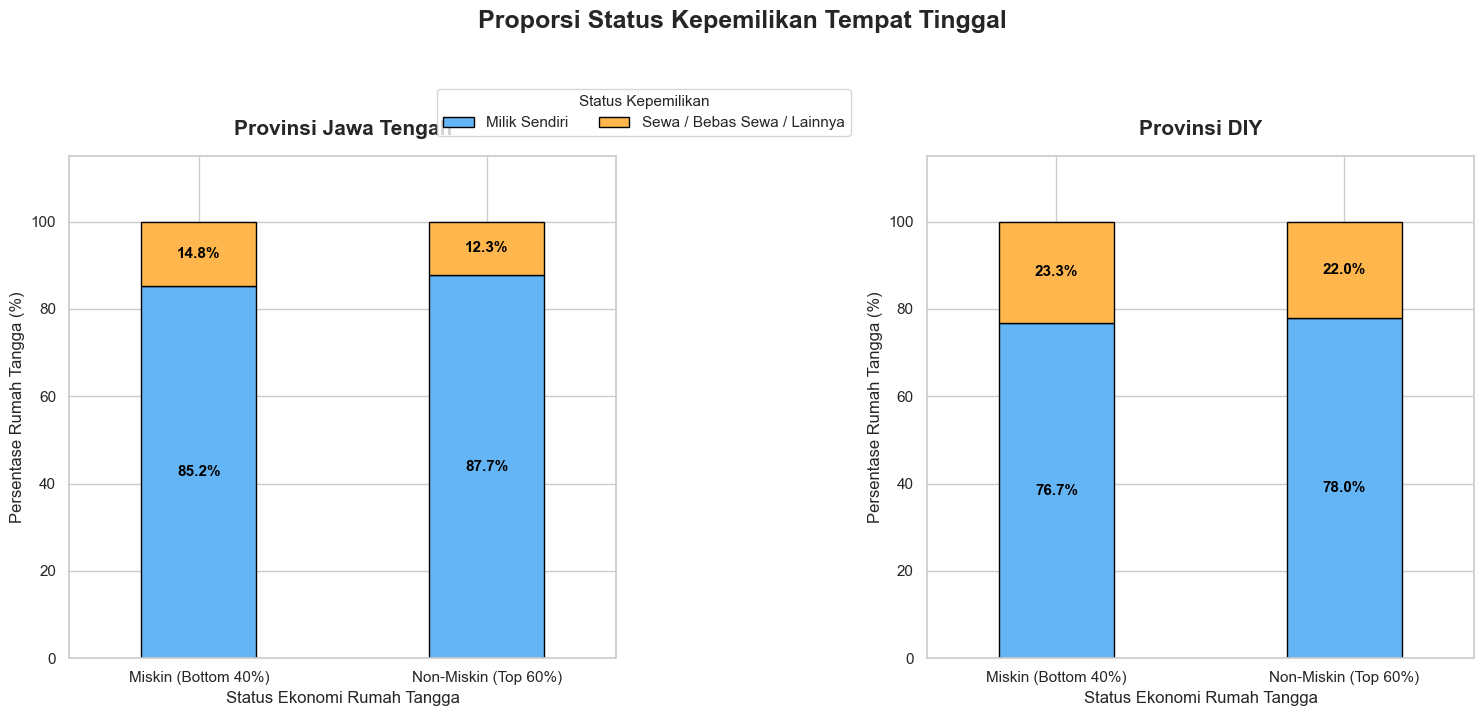


--- TABEL ANALISIS STATISTIK DESKRIPTIF: STATUS KEPEMILIKAN RUMAH (2025) ---
                                  Mean (Proporsi)  Min  Max  Std Dev  Variance  Skewness  Kurtosis
Provinsi    Status Ekonomi                                                                        
Jawa Tengah Miskin (Bottom 40%)            0.8519    0    1   0.3552    0.1262   -1.9820    1.9285
            Non-Miskin (Top 60%)           0.8774    0    1   0.3280    0.1076   -2.3012    3.2959
DIY         Miskin (Bottom 40%)            0.7672    0    1   0.4227    0.1787   -1.2658   -0.3981
            Non-Miskin (Top 60%)           0.7798    0    1   0.4144    0.1718   -1.3516   -0.1734


In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
import warnings

warnings.filterwarnings("ignore")

# ==============================================================================
# 1. FUNGSI PENDUKUNG
# ==============================================================================
def compute_decile_ranks(predictions):
    predictions = np.array(predictions)
    sorted_indices = np.argsort(predictions)
    ranks = np.zeros(len(predictions), dtype=np.int32)
    num_samples = len(predictions)
    decile_size = num_samples // 10
    for i in range(10):
        start_idx = i * decile_size
        end_idx = (i + 1) * decile_size if i < 9 else num_samples
        ranks[sorted_indices[start_idx:end_idx]] = i
    return ranks

def compute_group(df):
    if 'decile' not in df.columns:
        df['decile'] = compute_decile_ranks(df['pcexp'])
    df['group40'] = np.where(df['decile'] <= 3, 0, 1)
    return df

# ==============================================================================
# 2. LOAD DATA (KHUSUS 2025) & EKSTRAK PROVINSI
# ==============================================================================
work_dir = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/'
years = [2025] 
dfs = []

print("Membaca data Susenas untuk EDA Kepemilikan Rumah (2025)...")
for y in years:
    filename = f'susenas_final_{y}.csv'
    filepath = os.path.join(work_dir, filename)
    if os.path.exists(filepath):
        df_temp = pd.read_csv(filepath)
        df_temp['year'] = y
        dfs.append(df_temp)
    else:
        print(f" [WARNING] File tidak ditemukan: {filename}")

if not dfs:
    raise FileNotFoundError("Tidak ada satupun file susenas_final_*.csv yang ditemukan di direktori!")

# Gabungkan semua tahun menjadi satu dataframe besar
df = pd.concat(dfs, ignore_index=True)

# Ekstrak Provinsi dari kode_kab
if 'kode_prov' not in df.columns and 'kode_kab' in df.columns:
    df['kode_prov'] = df['kode_kab'] // 100
    
df['Provinsi'] = df['kode_prov'].map({33: 'Jawa Tengah', 34: 'DIY'})

# Tentukan kelompok pengeluaran
df = compute_group(df)
df['Status'] = df['group40'].map({0: 'Miskin (Bottom 40%)', 1: 'Non-Miskin (Top 60%)'})

status_order = ['Miskin (Bottom 40%)', 'Non-Miskin (Top 60%)']
prov_order = ['Jawa Tengah', 'DIY']

# ==============================================================================
# 3. TRANSFORMASI DATA KEPEMILIKAN RUMAH
# ==============================================================================
if 'h_house1' in df.columns:
    df['h_house1'] = pd.to_numeric(df['h_house1'], errors='coerce').fillna(0)
else:
    df['h_house1'] = 0

# Hitung persentase kepemilikan berdasarkan Provinsi dan Status
df_milik = df.groupby(['Provinsi', 'Status'])[['h_house1']].mean() * 100
df_milik_full = pd.DataFrame({
    'Milik Sendiri': df_milik['h_house1'],
    'Sewa / Bebas Sewa / Lainnya': 100 - df_milik['h_house1']
})

# ==============================================================================
# 4. VISUALISASI STACKED BAR CHART BERJEJER (1x2 SUBPLOTS)
# ==============================================================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
fig.suptitle('Proporsi Status Kepemilikan Tempat Tinggal', fontsize=18, fontweight='bold', y=1.02)

colors_stack = ['#64B5F6', '#FFB74D'] 

for i, prov in enumerate(prov_order):
    # Ekstrak data per provinsi dan urutkan sesuai status_order
    df_prov = df_milik_full.loc[prov].loc[status_order]
    
    df_prov.plot(
        kind='bar', 
        stacked=True, 
        ax=axes[i], 
        color=colors_stack, 
        edgecolor='black', 
        width=0.4
    )
    
    axes[i].set_title(f'Provinsi {prov}', fontsize=15, fontweight='bold', pad=15)
    axes[i].set_ylabel('Persentase Rumah Tangga (%)', fontsize=12)
    axes[i].set_xlabel('Status Ekonomi Rumah Tangga', fontsize=12)
    axes[i].set_ylim(0, 115)
    axes[i].tick_params(axis='x', rotation=0, labelsize=11)
    
    # Tambahkan label persentase di tengah setiap segmen bar
    for p in axes[i].patches:
        width = p.get_width()
        height = p.get_height()
        if height > 5: 
            x = p.get_x() + width / 2
            y = p.get_y() + height / 2
            axes[i].text(x, y, f'{height:.1f}%', ha='center', va='center', color='black', weight='bold', fontsize=11)
    
    # Menempatkan legend hanya di plot pertama agar tidak menumpuk
    if i == 0:
        axes[i].legend(title='Status Kepemilikan', fontsize=11, title_fontsize=11, loc='upper center', bbox_to_anchor=(1.05, 1.15), ncol=2, frameon=True)
    else:
        axes[i].get_legend().remove()

plt.tight_layout()
plt.show()

# ==============================================================================
# 5. TABEL ANALISIS STATISTIK DESKRIPTIF DETAIL (PER PROVINSI)
# ==============================================================================
print("\n" + "="*90)
print("--- TABEL ANALISIS STATISTIK DESKRIPTIF: STATUS KEPEMILIKAN RUMAH (2025) ---")
print("="*90)

desc_list = []
for prov in prov_order:
    for status_val in status_order:
        sub_series = df[(df['Provinsi'] == prov) & (df['Status'] == status_val)]['h_house1'].dropna()
        
        stat_df = pd.DataFrame({
            'Mean (Proporsi)': [sub_series.mean()],
            'Min': [sub_series.min()],
            'Max': [sub_series.max()],
            'Std Dev': [sub_series.std()],
            'Variance': [sub_series.var()],
            'Skewness': [sub_series.skew()],
            'Kurtosis': [sub_series.kurt()]
        })
        
        stat_df.index = pd.MultiIndex.from_tuples([(prov, status_val)], names=['Provinsi', 'Status Ekonomi'])
        desc_list.append(stat_df)

desc_final = pd.concat(desc_list)
pd.set_option('display.float_format', '{:,.4f}'.format)
pd.set_option('display.max_columns', 10)
pd.set_option('display.width', 1000)
print(desc_final)
print("="*90)

Membaca data Susenas untuk EDA Perumahan (2022)...


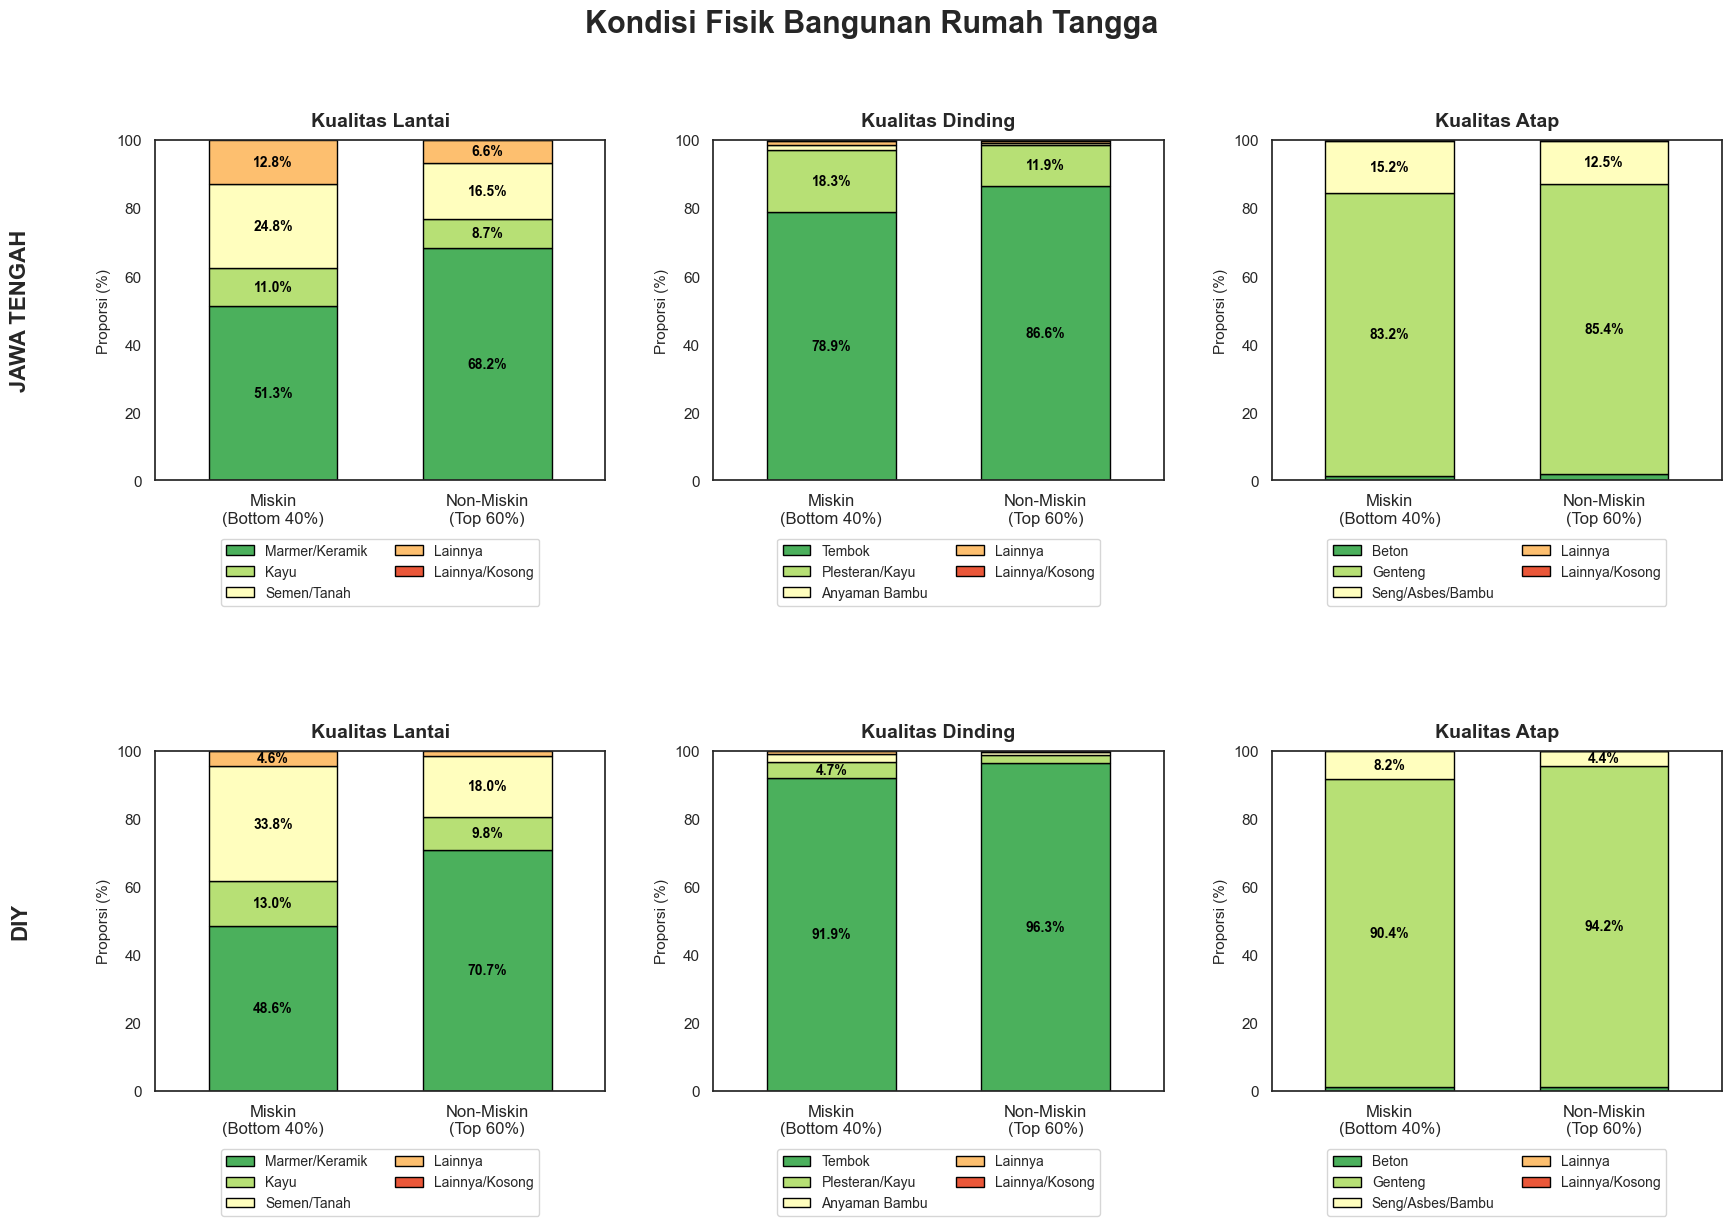

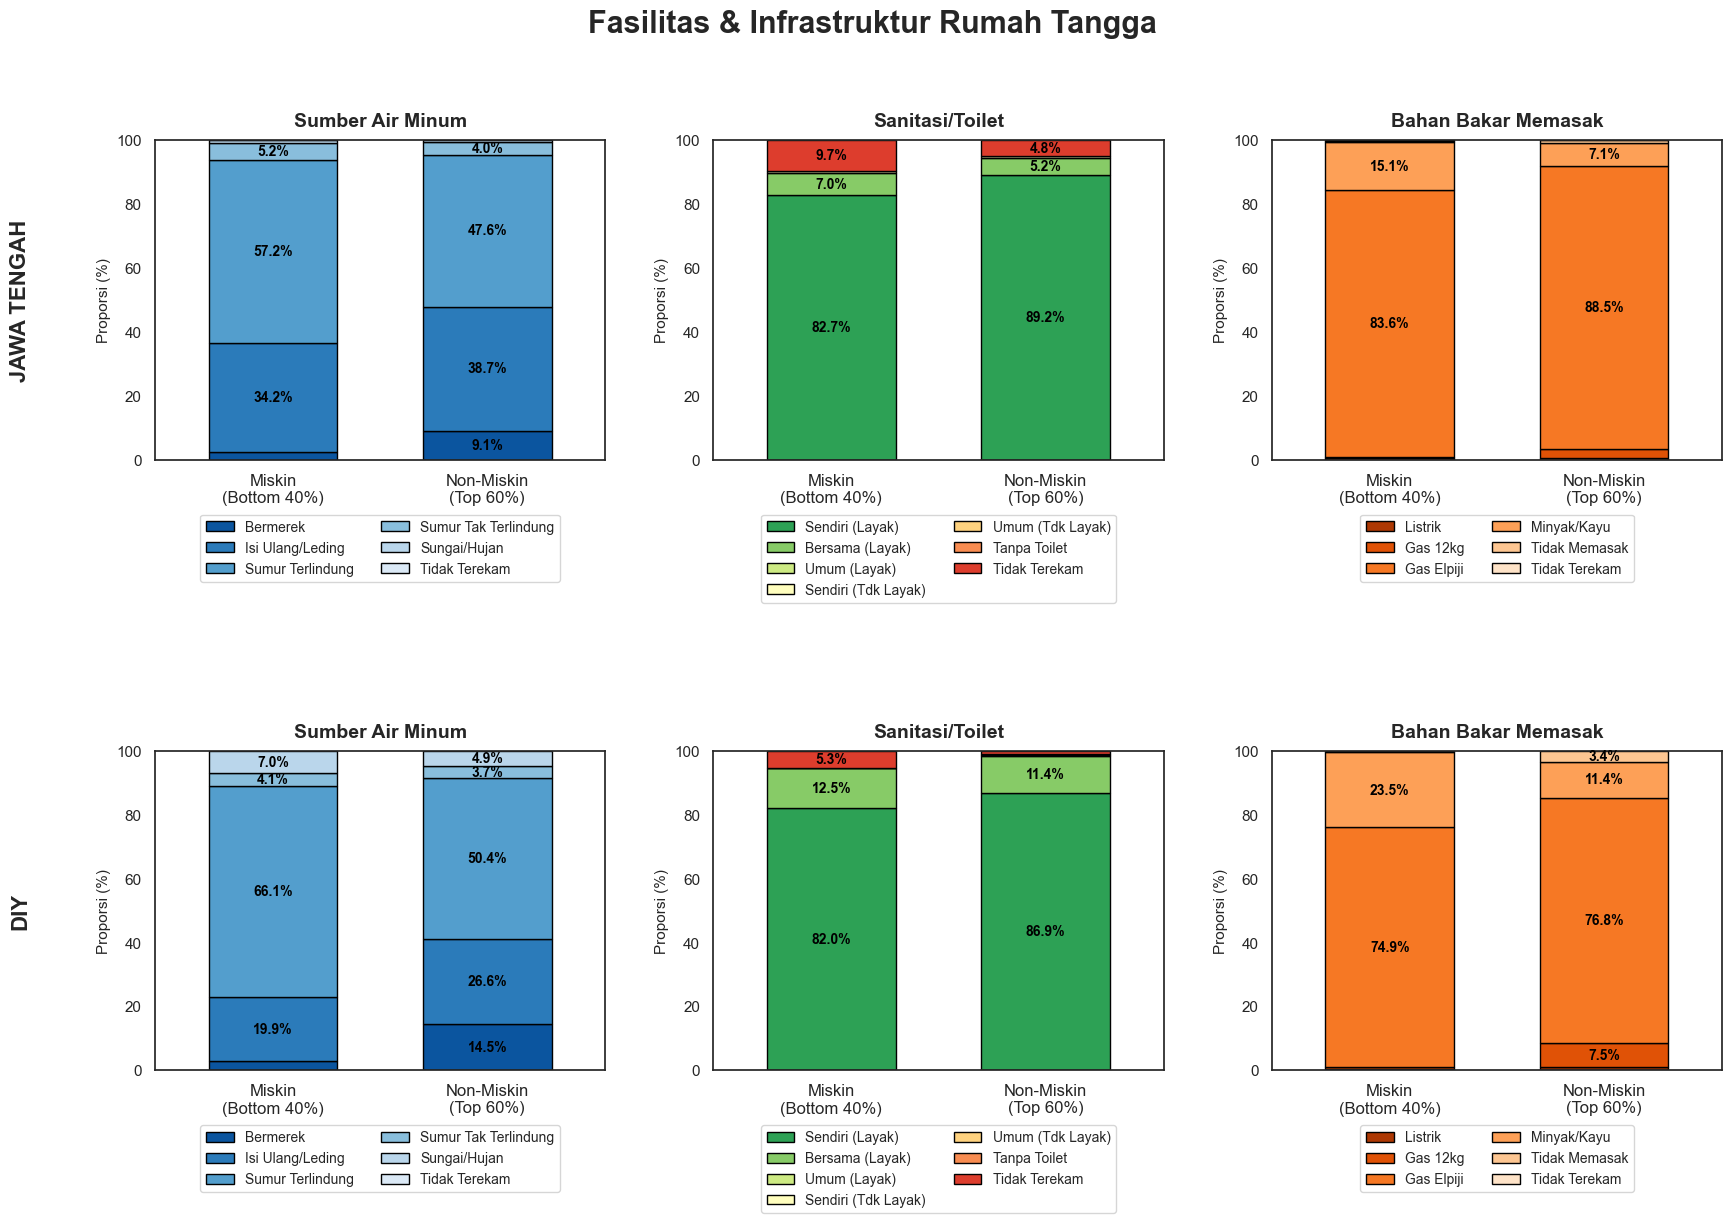


--- RINGKASAN PROPORSI KELAYAKAN PERUMAHAN & INFRASTRUKTUR (%) [2022] ---

>> PROVINSI: JAWA TENGAH
--------------------------------------------------
1. Material Lantai:
Status          Miskin\n(Bottom 40%)  Non-Miskin\n(Top 60%)
Marmer/Keramik                 51.3%                  68.2%
Kayu                           11.0%                   8.7%
Semen/Tanah                    24.8%                  16.5%
Lainnya                        12.8%                   6.6%
Lainnya/Kosong                  0.0%                   0.0%

2. Material Dinding:
Status          Miskin\n(Bottom 40%)  Non-Miskin\n(Top 60%)
Tembok                         78.9%                  86.6%
Plesteran/Kayu                 18.3%                  11.9%
Anyaman Bambu                   1.4%                   0.7%
Lainnya                         1.3%                   0.6%
Lainnya/Kosong                  0.2%                   0.2%

3. Material Atap:
Status            Miskin\n(Bottom 40%)  Non-Miskin\n(Top 60%)
Beton

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os
import warnings

warnings.filterwarnings("ignore")

# ==============================================================================
# 1. FUNGSI PENDUKUNG
# ==============================================================================
def compute_decile_ranks(predictions):
    predictions = np.array(predictions)
    sorted_indices = np.argsort(predictions)
    ranks = np.zeros(len(predictions), dtype=np.int32)
    num_samples = len(predictions)
    decile_size = num_samples // 10
    for i in range(10):
        start_idx = i * decile_size
        end_idx = (i + 1) * decile_size if i < 9 else num_samples
        ranks[sorted_indices[start_idx:end_idx]] = i
    return ranks

def compute_group(df):
    if 'decile' not in df.columns:
        df['decile'] = compute_decile_ranks(df['pcexp'])
    df['group40'] = np.where(df['decile'] <= 3, 0, 1)
    return df

# ==============================================================================
# 2. LOAD DATA (KHUSUS 2022)
# ==============================================================================
work_dir = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/'
years = [2022]
dfs = []

print("Membaca data Susenas untuk EDA Perumahan (2022)...")
for y in years:
    filename = f'susenas_clean_{y}.csv'
    filepath = os.path.join(work_dir, filename)
    if os.path.exists(filepath):
        df_temp = pd.read_csv(filepath)
        df_temp['year'] = y
        dfs.append(df_temp)
    else:
        print(f" [WARNING] File tidak ditemukan: {filename}")

if not dfs:
    raise FileNotFoundError("Tidak ada file susenas_clean_2022.csv di direktori!")

df = pd.concat(dfs, ignore_index=True)

# Ekstrak Provinsi
if 'kode_prov' not in df.columns and 'kode_kab' in df.columns:
    df['kode_prov'] = df['kode_kab'] // 100
df['Provinsi'] = df['kode_prov'].map({33: 'Jawa Tengah', 34: 'DIY'})

df = compute_group(df)
df['Status'] = df['group40'].map({0: 'Miskin\n(Bottom 40%)', 1: 'Non-Miskin\n(Top 60%)'})
status_order = ['Miskin\n(Bottom 40%)', 'Non-Miskin\n(Top 60%)']
prov_order = ['Jawa Tengah', 'DIY']

# ==============================================================================
# 3. TRANSFORMASI DATA PROPORSI (%) PER PROVINSI
# ==============================================================================
# --- KELOMPOK 1: FISIK BANGUNAN ---
floor_cols = ['h_floor1', 'h_floor2', 'h_floor3', 'h_floor4']
wall_cols = ['h_wall1', 'h_wall2', 'h_wall3', 'h_wall4']
roof_cols = ['h_roof1', 'h_roof2', 'h_roof3', 'h_roof4']

for col in floor_cols + wall_cols + roof_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)
    else:
        df[col] = 0

df_floor = df.groupby(['Provinsi', 'Status'])[floor_cols].mean() * 100
df_wall = df.groupby(['Provinsi', 'Status'])[wall_cols].mean() * 100
df_roof = df.groupby(['Provinsi', 'Status'])[roof_cols].mean() * 100

df_floor['Lainnya/Kosong'] = 100 - df_floor.sum(axis=1)
df_wall['Lainnya/Kosong'] = 100 - df_wall.sum(axis=1)
df_roof['Lainnya/Kosong'] = 100 - df_roof.sum(axis=1)

df_floor[df_floor < 0] = 0; df_wall[df_wall < 0] = 0; df_roof[df_roof < 0] = 0

df_floor.columns = ['Marmer/Keramik', 'Kayu', 'Semen/Tanah', 'Lainnya', 'Lainnya/Kosong']
df_wall.columns = ['Tembok', 'Plesteran/Kayu', 'Anyaman Bambu', 'Lainnya', 'Lainnya/Kosong']
df_roof.columns = ['Beton', 'Genteng', 'Seng/Asbes/Bambu', 'Lainnya', 'Lainnya/Kosong']

# --- KELOMPOK 2: INFRASTRUKTUR DASAR ---
water_cols = ['h_dwater1', 'h_dwater2', 'h_dwater3', 'h_dwater4', 'h_dwater5']
toil_cols = ['h_toiltype1', 'h_toiltype2', 'h_toiltype3', 'h_toiltype4', 'h_toiltype5', 'h_toiltype6']
cook_cols = ['h_cookingfuel1', 'h_cookingfuel2', 'h_cookingfuel3', 'h_cookingfuel4', 'h_cookingfuel5']

for col in water_cols + toil_cols + cook_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce').fillna(0)
    else:
        df[col] = 0

df_water = df.groupby(['Provinsi', 'Status'])[water_cols].mean() * 100
df_toil = df.groupby(['Provinsi', 'Status'])[toil_cols].mean() * 100
df_cook = df.groupby(['Provinsi', 'Status'])[cook_cols].mean() * 100

df_water['Tidak Terekam'] = 100 - df_water.sum(axis=1)
df_toil['Tidak Terekam'] = 100 - df_toil.sum(axis=1)
df_cook['Tidak Terekam'] = 100 - df_cook.sum(axis=1)

df_water[df_water < 0] = 0; df_toil[df_toil < 0] = 0; df_cook[df_cook < 0] = 0

df_water.columns = ['Bermerek', 'Isi Ulang/Leding', 'Sumur Terlindung', 'Sumur Tak Terlindung', 'Sungai/Hujan','Tidak Terekam']
df_toil.columns = ['Sendiri (Layak)', 'Bersama (Layak)', 'Umum (Layak)', 'Sendiri (Tdk Layak)', 'Umum (Tdk Layak)', 'Tanpa Toilet', 'Tidak Terekam']
df_cook.columns = ['Listrik', 'Gas 12kg', 'Gas Elpiji', 'Minyak/Kayu', 'Tidak Memasak','Tidak Terekam']

# ==============================================================================
# 4. FUNGSI PLOTTING
# ==============================================================================
def add_labels_vertical(ax):
    for p in ax.patches:
        height = p.get_height()
        if height > 3.0:
            x = p.get_x() + p.get_width() / 2
            y = p.get_y() + height / 2
            ax.text(x, y, f'{height:.1f}%', ha='center', va='center', color='black', weight='bold', fontsize=10)

def plot_stacked_vertical(df_plot, ax, title, cmap_name='RdYlGn_r'):
    df_ordered = df_plot.reindex(status_order)
    colors = sns.color_palette(cmap_name, n_colors=len(df_plot.columns))
    df_ordered.plot(kind='bar', stacked=True, ax=ax, color=colors, edgecolor='black', width=0.6)
    
    ax.set_title(title, fontsize=14, fontweight='bold', pad=10)
    ax.set_ylabel('Proporsi (%)', fontsize=11)
    ax.set_xlabel('')
    ax.set_ylim(0, 100)
    ax.tick_params(axis='x', rotation=0, labelsize=12)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), fontsize=10, ncol=2)
    add_labels_vertical(ax)

# ==============================================================================
# 5A. VISUALISASI GAMBAR 1: KONDISI FISIK BANGUNAN (2x3)
# ==============================================================================
sns.set_theme(style="white")
fig1, axes1 = plt.subplots(2, 3, figsize=(18, 13))
fig1.suptitle('Kondisi Fisik Bangunan Rumah Tangga', fontsize=22, fontweight='bold', y=0.98)

for i, prov in enumerate(prov_order):
    # Label baris untuk penanda Provinsi
    axes1[i, 0].text(-0.3, 0.5, f'{prov.upper()}', ha='center', va='center', rotation=90, 
                     transform=axes1[i, 0].transAxes, fontsize=16, fontweight='bold')
    
    plot_stacked_vertical(df_floor.loc[prov], axes1[i, 0], f'Kualitas Lantai')
    plot_stacked_vertical(df_wall.loc[prov], axes1[i, 1], f'Kualitas Dinding')
    plot_stacked_vertical(df_roof.loc[prov], axes1[i, 2], f'Kualitas Atap')

plt.tight_layout(pad=3.0, h_pad=6.0, w_pad=3.0)
plt.show()

# ==============================================================================
# 5B. VISUALISASI GAMBAR 2: INFRASTRUKTUR DASAR (2x3)
# ==============================================================================
fig2, axes2 = plt.subplots(2, 3, figsize=(18, 13))
fig2.suptitle('Fasilitas & Infrastruktur Rumah Tangga', fontsize=22, fontweight='bold', y=0.98)

for i, prov in enumerate(prov_order):
    # Label baris untuk penanda Provinsi
    axes2[i, 0].text(-0.3, 0.5, f'{prov.upper()}', ha='center', va='center', rotation=90, 
                     transform=axes2[i, 0].transAxes, fontsize=16, fontweight='bold')
    
    plot_stacked_vertical(df_water.loc[prov], axes2[i, 0], f'Sumber Air Minum', cmap_name='Blues_r')
    plot_stacked_vertical(df_toil.loc[prov], axes2[i, 1], f'Sanitasi/Toilet')
    plot_stacked_vertical(df_cook.loc[prov], axes2[i, 2], f'Bahan Bakar Memasak', cmap_name='Oranges_r')

plt.tight_layout(pad=3.0, h_pad=6.0, w_pad=3.0)
plt.show()

# ==============================================================================
# 6. TABEL RINGKASAN PER PROVINSI
# ==============================================================================
print("\n" + "="*90)
print("--- RINGKASAN PROPORSI KELAYAKAN PERUMAHAN & INFRASTRUKTUR (%) [2022] ---")
print("="*90)
pd.set_option('display.float_format', lambda x: '%.1f%%' % x)

for prov in prov_order:
    print(f"\n>> PROVINSI: {prov.upper()}")
    print("-" * 50)
    print("1. Material Lantai:"); print(df_floor.loc[prov].T)
    print("\n2. Material Dinding:"); print(df_wall.loc[prov].T)
    print("\n3. Material Atap:"); print(df_roof.loc[prov].T)
    print("\n4. Sumber Air Minum:"); print(df_water.loc[prov].T)
    print("\n5. Jenis Sanitasi/Toilet:"); print(df_toil.loc[prov].T)
    print("\n6. Bahan Bakar Memasak:"); print(df_cook.loc[prov].T)
print("="*90)

In [19]:
# Cek nilai unik (unique values) pada kolom sanitasi mentah sebelum di-filter
raw_toil_cols = ['h_toiltype1', 'h_toiltype2', 'h_toiltype3', 'h_toiltype4', 'h_toiltype5', 'h_toiltype6']
for col in raw_toil_cols:
    if col in df.columns:
        print(f"Kolom {col} memiliki nilai unik: {df[col].unique()}")

Kolom h_toiltype1 memiliki nilai unik: [1 0]
Kolom h_toiltype2 memiliki nilai unik: [0 1]
Kolom h_toiltype3 memiliki nilai unik: [0]
Kolom h_toiltype4 memiliki nilai unik: [0 1]
Kolom h_toiltype5 memiliki nilai unik: [0 1]
Kolom h_toiltype6 memiliki nilai unik: [0]


In [23]:
import pandas as pd
import numpy as np
import warnings
import os
import gpboost as gpb
import json
from sklearn.metrics import mean_squared_error

warnings.filterwarnings("ignore")

# ==============================================================================
# 1. KONFIGURASI & CUSTOM ENCODER
# ==============================================================================
work_dir = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/'
model_save_path = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/Models'
TEST_YEAR = 2025
RANDOM_STATE = 123

if not os.path.exists(model_save_path):
    os.makedirs(model_save_path)

class NpEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, np.integer):
            return int(obj)
        if isinstance(obj, np.floating):
            return float(obj)
        if isinstance(obj, np.ndarray):
            return obj.tolist()
        return super(NpEncoder, self).default(obj)

# ==============================================================================
# 2. FUNGSI EVALUASI BERBOBOT (KHUSUS RMSE)
# ==============================================================================
def compute_decile_ranks(predictions):
    predictions = np.array(predictions)
    sorted_indices = np.argsort(predictions)
    ranks = np.zeros(len(predictions), dtype=np.int32)
    num_samples = len(predictions)
    decile_size = num_samples // 10
    
    for i in range(10):
        start_idx = i * decile_size
        end_idx = (i + 1) * decile_size if i < 9 else num_samples
        ranks[sorted_indices[start_idx:end_idx]] = i
    return ranks

def evaluate_subset_rmse_only(df_subset, district_train_name, district_test_name, model_name, train_size, weight_col='WERT'):
    if len(df_subset) < 10:
        return None 
        
    df_eval = df_subset.copy()
    
    w = df_eval[weight_col].astype(str).str.replace(',', '.').astype(float).values
    
    df_eval['decile'] = compute_decile_ranks(df_eval['pcexp'])
    
    df_eval['group20'] = np.where(df_eval['decile'] <= 1, 0, 1)
    df_eval['group40'] = np.where(df_eval['decile'] <= 3, 0, 1)
    df_eval['group60'] = np.where(df_eval['decile'] <= 5, 0, 1)
    
    y_true_log = df_eval['lpcexp_final'].values
    y_pred_log = np.log(df_eval['pred_gpboost']).values
    
    # 1. Menghitung RMSE Global
    weighted_mse = np.sum(w * (y_true_log - y_pred_log) ** 2) / np.sum(w)
    rmse = np.round(np.sqrt(weighted_mse), 4)
    
    # 2. Menghitung RMSE 20, 40, 60 (Berbobot)
    def get_rmse_cutoff(mask):
        if np.sum(w[mask]) == 0: return 0.0
        mse_cutoff = np.sum(w[mask] * (y_true_log[mask] - y_pred_log[mask]) ** 2) / np.sum(w[mask])
        return np.round(np.sqrt(mse_cutoff), 4)

    rmse20 = get_rmse_cutoff(df_eval['group20'] == 0)
    rmse40 = get_rmse_cutoff(df_eval['group40'] == 0)
    rmse60 = get_rmse_cutoff(df_eval['group60'] == 0)
    
    return {
        'district_train': district_train_name,
        'district_test': district_test_name,
        'train_desc': f'Years_Excl_{TEST_YEAR}_Weighted',
        'test_desc': str(TEST_YEAR),
        'model': model_name,
        'RMSE_Log': rmse, 
        'RMSE20': rmse20, 
        'RMSE40': rmse40, 
        'RMSE60': rmse60, 
        'train_size': train_size,
        'test_size': len(df_eval)
    }

# ==============================================================================
# 3. LOAD DATA
# ==============================================================================
print("--- Loading Data Susenas ---")
dfs = {}
for year in [2022, 2023, 2024, 2025]:
    filename = os.path.join(work_dir, f'susenas_final_{year}.csv')
    
    if os.path.exists(filename):
        print(f"Loading {year}...")
        df_temp = pd.read_csv(filename)
        df_temp['year'] = year
        if 'NFOOD' in df_temp.columns and 'NONFOOD' not in df_temp.columns:
            df_temp['NONFOOD'] = df_temp['NFOOD']
        
        if 'kode_kab' in df_temp.columns:
             df_temp['kode_kab'] = df_temp['kode_kab'].fillna(0).astype(int)
             df_temp['kode_prov'] = df_temp['kode_kab'] // 100
             
        dfs[year] = df_temp
    else:
        print(f"[GAGAL] File tidak ditemukan: {filename}")

if not dfs:
    raise FileNotFoundError("TIDAK ADA SATUPUN FILE YANG BERHASIL DI-LOAD.")

train_years = [y for y in dfs.keys() if y != TEST_YEAR]
train_df = pd.concat([dfs[y] for y in train_years], ignore_index=True)
test_df = dfs[TEST_YEAR].copy().reset_index(drop=True)

# ==============================================================================
# 4. DEFINISI STRUKTUR VARIABEL (2 SKEMA IPM + RANDOM SLOPE)
# ==============================================================================
vars_level_1 = [
    'h_hhcount','h_nmale','h_nfemale','h_nage04','h_nage519','h_nage2064','h_nage65up', 
    'h_ngrad_sd','h_ngrad_smp', 'h_ngrad_sma','h_ngrad_d','h_ngrad_s','h_notgrad',
    'h_sec1_stat1', 'h_sec1_stat2', 'h_sec1_stat3', 'h_sec1_stat4', 'h_sec1_stat5', 'h_sec1_stat6',
    'h_sec2_stat1', 'h_sec2_stat2', 'h_sec2_stat3', 'h_sec2_stat4', 'h_sec2_stat5', 'h_sec2_stat6',
    'h_sec3_stat1', 'h_sec3_stat2', 'h_sec3_stat3', 'h_sec3_stat4', 'h_sec3_stat5', 'h_sec3_stat6',
    'h_neverschool', 'h_stillschool', 'h_notschool',
    'h_house1','h_house2','h_house3','h_house4',
    'h_floor1','h_floor2','h_floor3','h_floor4', 
    'h_wall1','h_wall2','h_wall3','h_wall4',
    'h_roof1','h_roof2','h_roof3','h_roof4', 
    'h_dwater1','h_dwater2','h_dwater3','h_dwater4','h_dwater5',
    'h_lighting1','h_lighting2','h_lighting3', 
    'h_epower1','h_epower2','h_epower3',
    'h_cookingfuel1','h_cookingfuel2','h_cookingfuel3','h_cookingfuel4','h_cookingfuel5',
    'h_toiltype1','h_toiltype2','h_toiltype3','h_toiltype4', 'h_toiltype5', 'h_toiltype6', 
    'h_septic1','h_septic2','h_septic3', 'h_septic4', 'h_septic5',
    'h_asset_lpg5kg', 'h_asset_fridge', 'h_asset_ac', 'h_asset_wheater', 'h_asset_phone', 'h_asset_computer',
    'h_asset_jewelry', 'h_asset_motorcycle', 'h_asset_boat', 'h_asset_motorboat', 'h_asset_car', 'h_asset_tv',
    'h_asset_smartphone', 'h_asset_land', 
    'h_lnluaslantai', 'h_nfamily','h_notmarried', 'h_married', 'h_divorced', 'h_widowed'
]

var_ipm = ['IPM']
vars_citra = ['NDBI', 'LST', 'NTL', 'elevation', 'slope', 'NDVI']
slope_vars = ['h_notgrad']

scenarios = {
    'Multilevel_IPM': vars_level_1 + var_ipm,
    'Multilevel_Citra_IPM': vars_level_1 + var_ipm + vars_citra
}

all_features = list(set(vars_level_1 + var_ipm + vars_citra + slope_vars))
train_df[all_features] = train_df[all_features].fillna(0)
test_df[all_features] = test_df[all_features].fillna(0)

# ==============================================================================
# 5. FUNGSI TRAINING MODEL PROVINSI
# ==============================================================================
def train_provincial_gpboost_slope(train_data, test_data, features, slope_vars, scenario_name, prov_code, prov_name):
    print(f"\n  > [{prov_name.upper()}] Training Model (Random Intercept + Slope)...")
    
    train_prov = train_data[train_data['kode_prov'] == prov_code].copy()
    test_prov = test_data[test_data['kode_prov'] == prov_code].copy()
    
    X_train = train_prov[features]
    y_train = train_prov['lpcexp_final']
    clusters_train = train_prov['kode_kab'].values 
    rand_coef_train = train_prov[slope_vars].values 
    
    X_test = test_prov[features]
    clusters_test = test_prov['kode_kab'].values
    rand_coef_test = test_prov[slope_vars].values   

    gp_model = gpb.GPModel(
        group_data=clusters_train, 
        group_rand_coef_data=rand_coef_train,
        ind_effect_group_rand_coef=[1],
        likelihood='gaussian'
    )
    data_train_gpb = gpb.Dataset(data=X_train, label=y_train)

    param_grid = {
        'learning_rate': [0.05, 0.1],
        'max_depth': [6, 8],
        'min_data_in_leaf': [20, 50],
        'l2_regularization': [0, 1]
    }
    params_base = {'objective': 'regression_l2', 'verbose': 0, 'random_state': RANDOM_STATE}
    
    opt_params = gpb.grid_search_tune_parameters(
        param_grid=param_grid, params=params_base, train_set=data_train_gpb,
        gp_model=gp_model, num_boost_round=400, nfold=3, verbose_eval=0, 
        metric='rmse', shuffle=True, seed=RANDOM_STATE
    )
    
    gp_model_final = gpb.GPModel(
        group_data=clusters_train, 
        group_rand_coef_data=rand_coef_train,
        ind_effect_group_rand_coef=[1],
        likelihood='gaussian'
    )
    final_params = {**params_base, **opt_params['best_params']}
    
    bst_tuned = gpb.train(
        params=final_params, train_set=data_train_gpb, 
        gp_model=gp_model_final, num_boost_round=int(opt_params['best_iter'])
    )

    pred_obj = bst_tuned.predict(
        data=X_test, 
        group_data_pred=clusters_test, 
        group_rand_coef_data_pred=rand_coef_test
    )
    test_prov['pred_gpboost'] = np.exp(pred_obj['response_mean'])
    
    filename = os.path.join(model_save_path, f'Model_Slope_{scenario_name}_{prov_name}_{TEST_YEAR}.json')
    bst_tuned.save_model(filename)
    
    return test_prov, len(train_prov)

# ==============================================================================
# 6 & 7. EKSEKUSI & TAMPILKAN HASIL RMSE LANGSUNG
# ==============================================================================
columns_order = [
    'district_train', 'district_test', 'model', 
    'RMSE_Log', 'RMSE20', 'RMSE40', 'RMSE60',
    'train_size', 'test_size'
]

print("\n" + "="*70)
print("Memulai Pelatihan 2 Skenario (IPM & Citra) + Random Slope")
print("="*70)

all_scenarios_results = []

for sc_name, features in scenarios.items():
    print(f"\n--- Memproses Skenario: {sc_name} ---")

    test_pred_jateng, train_size_jateng = train_provincial_gpboost_slope(
        train_df, test_df, features, slope_vars, sc_name, 33, 'Jateng'
    )
    test_pred_diy, train_size_diy = train_provincial_gpboost_slope(
        train_df, test_df, features, slope_vars, sc_name, 34, 'DIY'
    )

    print("  > Menghitung Evaluasi RMSE Berbobot (WERT)...")
    all_metrics = []

    eval_jateng = evaluate_subset_rmse_only(test_pred_jateng, 'PROV_JATENG', 'PROV_JATENG', f"Slope_{sc_name}", train_size_jateng, weight_col='WERT')
    eval_diy = evaluate_subset_rmse_only(test_pred_diy, 'PROV_DIY', 'PROV_DIY', f"Slope_{sc_name}", train_size_diy, weight_col='WERT')

    avg_metrics = {
        'district_train': 'AVG_JATENG_DIY',
        'district_test': 'AVG_JATENG_DIY',
        'model': f'Weighted_Slope_{sc_name}_Average',
    }
    
    num_keys = ['RMSE_Log', 'RMSE20', 'RMSE40', 'RMSE60']
                
    for k in num_keys:
        avg_metrics[k] = (eval_jateng[k] + eval_diy[k]) / 2.0
        
    avg_metrics['train_size'] = eval_jateng['train_size'] + eval_diy['train_size']
    avg_metrics['test_size'] = eval_jateng['test_size'] + eval_diy['test_size']

    all_metrics.append(avg_metrics)
    all_metrics.append(eval_jateng)
    all_metrics.append(eval_diy)

    for kab in sorted(test_pred_jateng['kode_kab'].unique()):
        subset_kab = test_pred_jateng[test_pred_jateng['kode_kab'] == kab]
        eval_kab = evaluate_subset_rmse_only(subset_kab, 'PROV_JATENG', f'KAB_{kab}', f"Slope_{sc_name}", train_size_jateng, weight_col='WERT')
        if eval_kab:
            all_metrics.append(eval_kab)

    for kab in sorted(test_pred_diy['kode_kab'].unique()):
        subset_kab = test_pred_diy[test_pred_diy['kode_kab'] == kab]
        eval_kab = evaluate_subset_rmse_only(subset_kab, 'PROV_DIY', f'KAB_{kab}', f"Slope_{sc_name}", train_size_diy, weight_col='WERT')
        if eval_kab:
            all_metrics.append(eval_kab)

    df_results = pd.DataFrame(all_metrics)[columns_order]
    all_scenarios_results.append(df_results)
    
final_df = pd.concat(all_scenarios_results, ignore_index=True)

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', '{:.4f}'.format)

print("\n" + "="*80)
print("HASIL EVALUASI RMSE (GLOBAL, 20, 40, 60)")
print("="*80)
print(final_df)
print("="*80)

--- Loading Data Susenas ---
Loading 2022...
Loading 2023...
Loading 2024...
Loading 2025...

Memulai Pelatihan 2 Skenario (IPM & Citra) + Random Slope

--- Memproses Skenario: Multilevel_IPM ---

  > [JATENG] Training Model (Random Intercept + Slope)...
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPB

[GPBoost] [Fatal] There was Nan or Inf value generated in the Conjugate Gradient Method!


[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown par

[GPBoost] [Fatal] There was Nan or Inf value generated in the Conjugate Gradient Method!


Error for parameter combination 14 of 16: {'learning_rate': 0.1, 'max_depth': 6, 'min_data_in_leaf': 50, 'l2_regularization': 1}
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warni

In [5]:
import gpboost as gpb
import os

model_save_path = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/Models'
TEST_YEAR = 2025
scenarios = ['Multilevel_IPM', 'Multilevel_Citra_IPM']
provinces = ['Jateng', 'DIY']

print("--- MENGECEK ULANG KONFIGURASI MODEL TERBAIK ---")
for sc_name in scenarios:
    for prov in provinces:
        path = os.path.join(model_save_path, f'Model_Slope_{sc_name}_{prov}_{TEST_YEAR}.json')
        if os.path.exists(path):
            bst = gpb.Booster(model_file=path)
            print(f"Skenario: {sc_name} | Provinsi: {prov} -> Jumlah Pohon Akhir (Best Iteration): {bst.best_iteration}")

--- MENGECEK ULANG KONFIGURASI MODEL TERBAIK ---
Finished loading model, total used 84 iterations
Skenario: Multilevel_IPM | Provinsi: Jateng -> Jumlah Pohon Akhir (Best Iteration): -1
Finished loading model, total used 27 iterations
Skenario: Multilevel_IPM | Provinsi: DIY -> Jumlah Pohon Akhir (Best Iteration): -1
Finished loading model, total used 80 iterations
Skenario: Multilevel_Citra_IPM | Provinsi: Jateng -> Jumlah Pohon Akhir (Best Iteration): -1
Finished loading model, total used 28 iterations
Skenario: Multilevel_Citra_IPM | Provinsi: DIY -> Jumlah Pohon Akhir (Best Iteration): -1


# SHAP

Memuat data test 2025 untuk SHAP Analysis...

MEMULAI EKSTRAKSI SHAP VALUES UNTUK SEMUA MODEL (OTOMATIS FITUR)

Memproses: XGBoost Baseline - Jateng
  > Menghitung SHAP values...


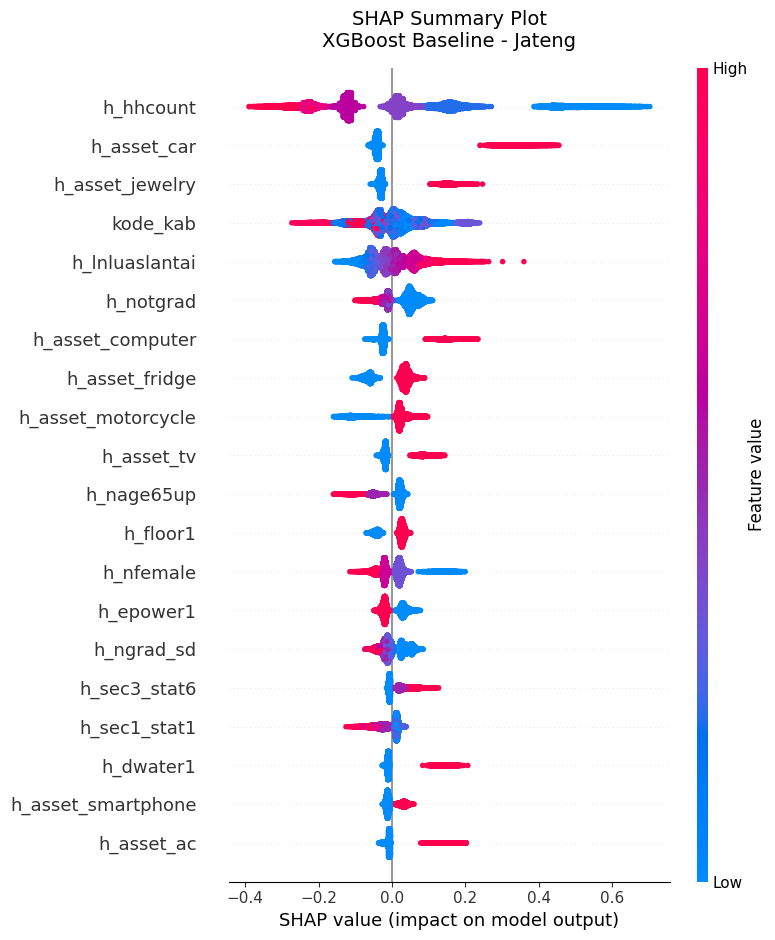


Memproses: XGBoost Baseline - DIY
  > Menghitung SHAP values...


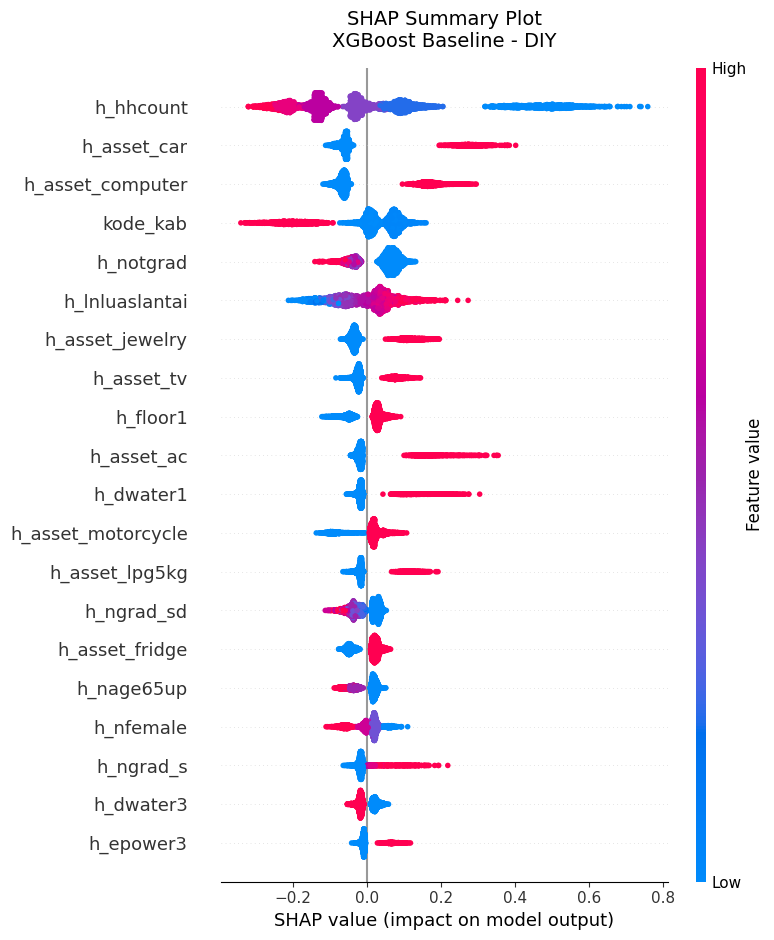


Memproses: XGBoost Citra - Jateng
  > Menghitung SHAP values...


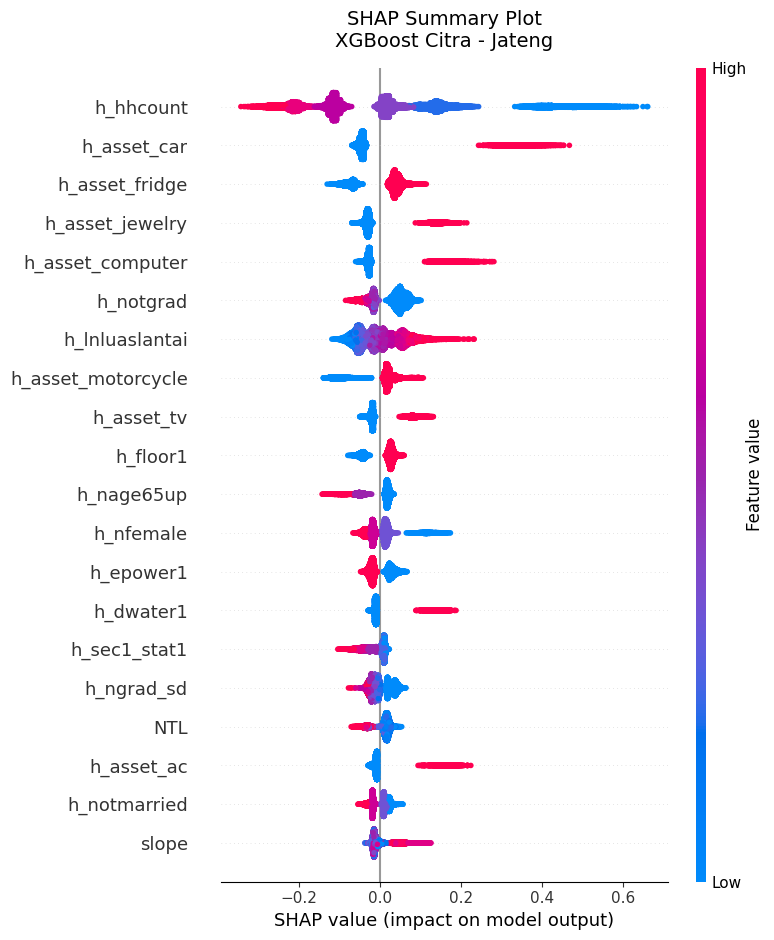


Memproses: XGBoost Citra - DIY
  > Menghitung SHAP values...


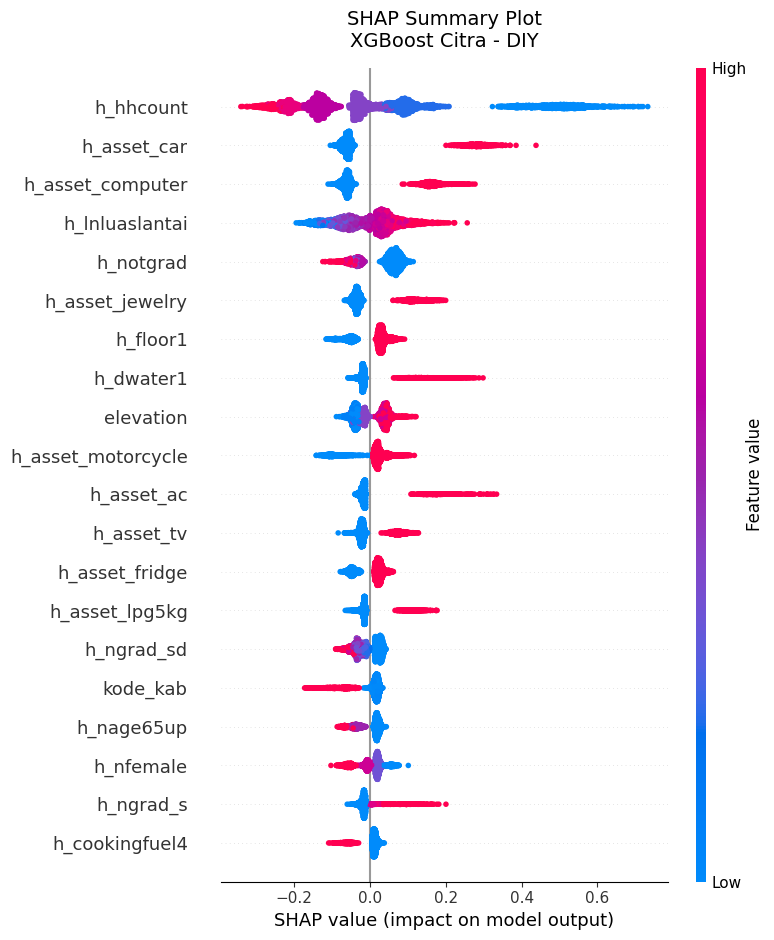


Memproses: GPBoost Multilevel (IPM) - Jateng
Finished loading model, total used 84 iterations
  > Menghitung SHAP values...


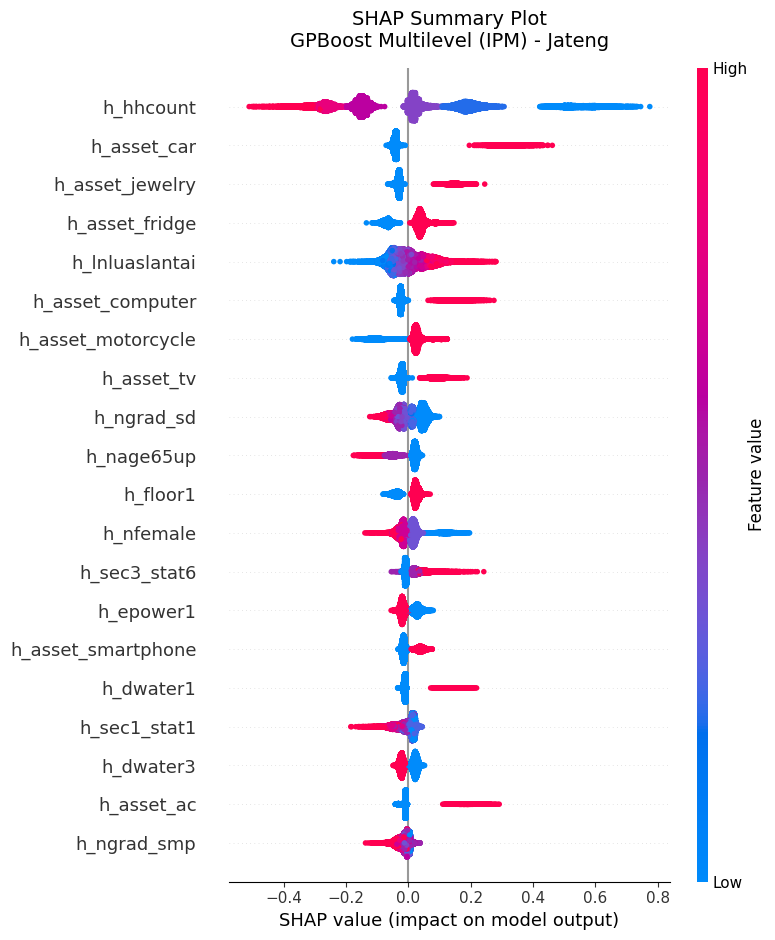


Memproses: GPBoost Multilevel (IPM) - DIY
Finished loading model, total used 27 iterations
  > Menghitung SHAP values...


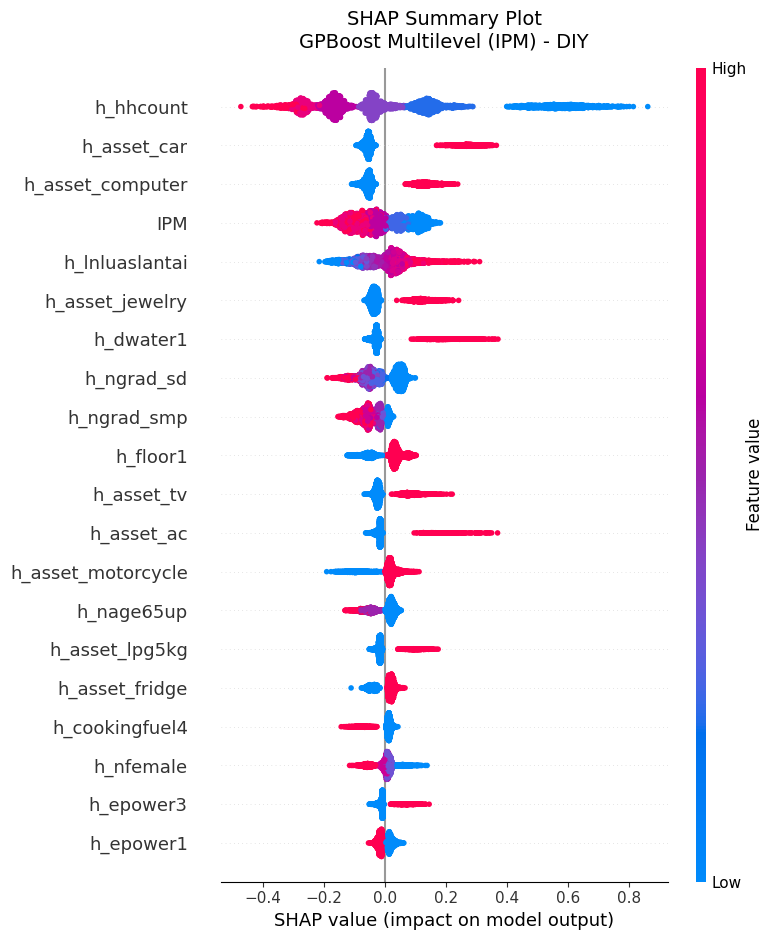


Memproses: GPBoost Multilevel Citra - Jateng
Finished loading model, total used 80 iterations
  > Menghitung SHAP values...


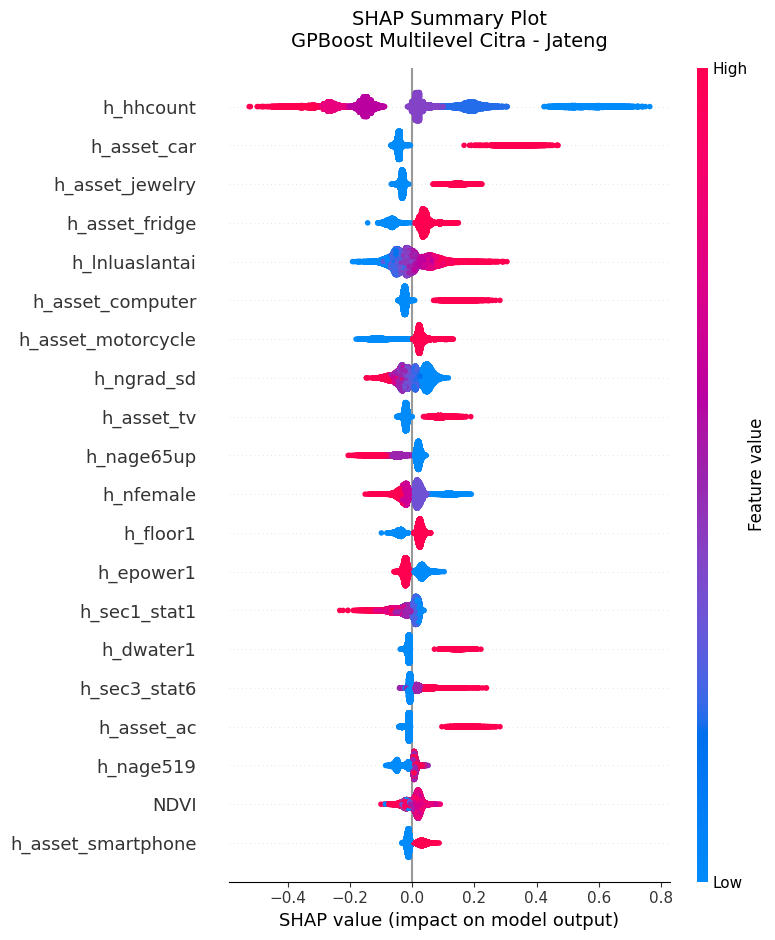


Memproses: GPBoost Multilevel Citra - DIY
Finished loading model, total used 28 iterations
  > Menghitung SHAP values...


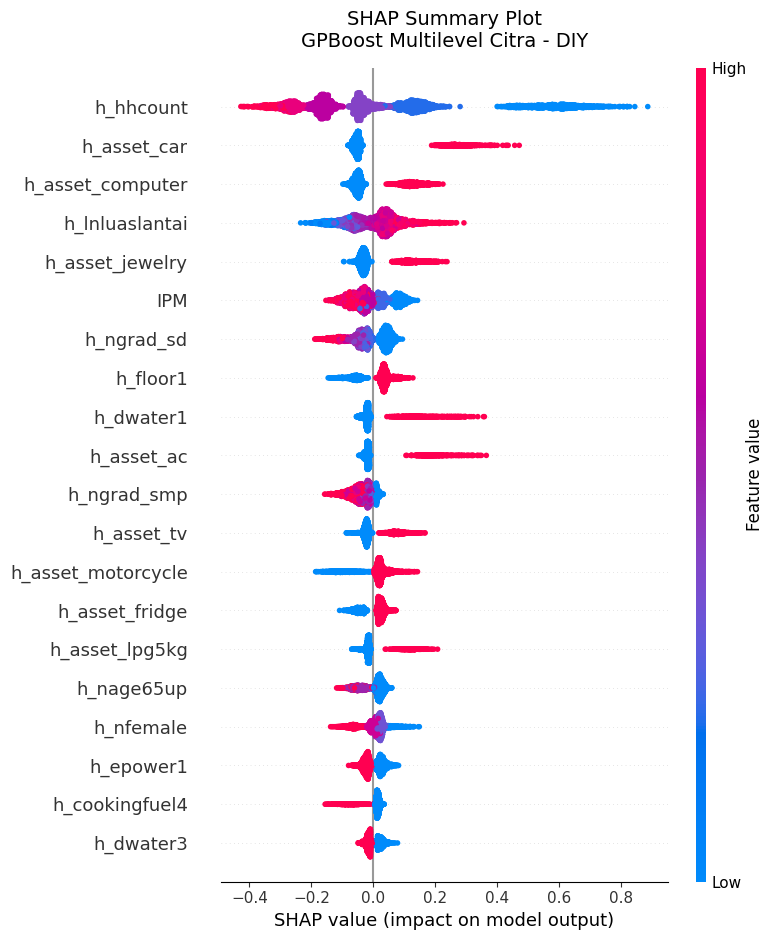


SELURUH ANALISIS SHAP SELESAI!


In [3]:
import pandas as pd
import numpy as np
import os
import joblib
import gpboost as gpb
import shap
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

# ==============================================================================
# 1. KONFIGURASI PATH & DATA TEST 2025
# ==============================================================================
work_dir = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/'
model_save_path = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/Models'
TEST_YEAR = 2025

# Load data test 2025
test_file = os.path.join(work_dir, f'susenas_final_{TEST_YEAR}.csv')
print(f"Memuat data test {TEST_YEAR} untuk SHAP Analysis...")
test_df = pd.read_csv(test_file)

# Pastikan tidak ada missing values
test_df = test_df.fillna(0)

# Cek apakah ada variasi nama kolom 'ipm' (huruf kecil/besar)
if 'ipm' in test_df.columns and 'IPM' not in test_df.columns:
    test_df.rename(columns={'ipm': 'IPM'}, inplace=True)

# Pisahkan berdasarkan kode provinsi (33: Jateng, 34: DIY)
test_jateng = test_df[test_df['kode_kab'] // 100 == 33].copy()
test_diy = test_df[test_df['kode_kab'] // 100 == 34].copy()

# ==============================================================================
# 2. LIST 8 MODEL DAN KONFIGURASINYA
# ==============================================================================
models_info = [
    # --- XGBOOST BASELINE (Aja) ---
    {'file': 'model_xgboost_TUNED_Jawa_Tengah_Test2025.pkl', 'type': 'xgb', 'data': test_jateng, 'title': 'XGBoost Baseline - Jateng'},
    {'file': 'model_xgboost_TUNED_DIY_Test2025.pkl', 'type': 'xgb', 'data': test_diy, 'title': 'XGBoost Baseline - DIY'},
    
    # --- XGBOOST CITRA ---
    {'file': 'model_xgboost_aja_TUNED_Jawa_Tengah_Test2025.pkl', 'type': 'xgb', 'data': test_jateng, 'title': 'XGBoost Citra - Jateng'},
    {'file': 'model_xgboost_aja_TUNED_DIY_Test2025.pkl', 'type': 'xgb', 'data': test_diy, 'title': 'XGBoost Citra - DIY'},
    
    # --- GPBOOST MULTILEVEL (IPM) ---
    {'file': 'Model_Slope_Multilevel_IPM_Jateng_2025.json', 'type': 'gpb', 'data': test_jateng, 'title': 'GPBoost Multilevel (IPM) - Jateng'},
    {'file': 'Model_Slope_Multilevel_IPM_DIY_2025.json', 'type': 'gpb', 'data': test_diy, 'title': 'GPBoost Multilevel (IPM) - DIY'},
    
    # --- GPBOOST MULTILEVEL CITRA ---
    {'file': 'Model_Slope_Multilevel_Citra_IPM_Jateng_2025.json', 'type': 'gpb', 'data': test_jateng, 'title': 'GPBoost Multilevel Citra - Jateng'},
    {'file': 'Model_Slope_Multilevel_Citra_IPM_DIY_2025.json', 'type': 'gpb', 'data': test_diy, 'title': 'GPBoost Multilevel Citra - DIY'}
]

# ==============================================================================
# 3. LOOPING UNTUK MENGHITUNG & PLOTTING SHAP VALUES (AMBIL FITUR OTOMATIS)
# ==============================================================================
print("\n" + "="*70)
print("MEMULAI EKSTRAKSI SHAP VALUES UNTUK SEMUA MODEL (OTOMATIS FITUR)")
print("="*70)

for info in models_info:
    model_path = os.path.join(model_save_path, info['file'])
    
    print(f"\nMemproses: {info['title']}")
    
    if not os.path.exists(model_path):
        print(f"[GAGAL] File model tidak ditemukan: {info['file']}")
        continue
        
    try:
        if info['type'] == 'xgb':
            # Load XGBoost (.pkl)
            model = joblib.load(model_path)
            # Ambil nama fitur asli yang digunakan saat training model XGBoost ini
            model_features = model.feature_names_in_
            explainer = shap.TreeExplainer(model)
        else:
            # Load GPBoost (.json)
            model = gpb.Booster(model_file=model_path)
            # Ambil nama fitur asli dari booster LightGBM di dalam GPBoost
            model_features = model.feature_name()
            explainer = shap.TreeExplainer(model)
        
        # Filter data test hanya mengambil kolom yang sesuai dengan model tersebut
        X_test = info['data'][model_features]
        
        # Kalkulasi SHAP values
        print("  > Menghitung SHAP values...")
        shap_values = explainer.shap_values(X_test)
        
        # Membuat Plot
        plt.figure(figsize=(10, 6))
        shap.summary_plot(shap_values, X_test, max_display=20, show=False)
        plt.title(f"SHAP Summary Plot\n{info['title']}", fontsize=14, pad=15)
        plt.tight_layout()
        plt.show()
        
    except Exception as e:
        print(f"[ERROR] Terjadi kesalahan saat memproses {info['title']}: {e}")

print("\n" + "="*70)
print("SELURUH ANALISIS SHAP SELESAI!")
print("="*70)

In [4]:
import pandas as pd
import numpy as np
import os

work_dir = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/'
years = [2022, 2023, 2024, 2025]
dfs = []

print("Memuat dan membersihkan data gabungan 2022-2025 untuk Tableau...")
for y in years:
    filepath = os.path.join(work_dir, f'susenas_final_{y}.csv')
    if os.path.exists(filepath):
        df = pd.read_csv(filepath, low_memory=False)
        df['year'] = y
        
        # Daftar kolom esensial sesuai variabel yang ingin dianalisis
        cols_to_keep = [
            'kode_kab', 'WERT', 'pcexp', 'lpcexp_final', 'year',
            # 1. Ukuran & Kelompok Umur Rumah Tangga
            'h_hhcount', 'h_nfamily', 'h_nmale', 'h_nfemale', 
            'h_nage04', 'h_nage519', 'h_nage2064', 'h_nage65up',
            # 2. Pendidikan Kepala Rumah Tangga
            'h_ngrad_sd', 'h_ngrad_smp', 'h_ngrad_sma', 'h_ngrad_d', 'h_ngrad_s', 'h_notgrad',
            'h_neverschool', 'h_stillschool', 'h_notschool',
            # 3. Lapangan Usaha / Pekerjaan (Sektor 1, 2, 3)
            'h_sec1_stat1', 'h_sec1_stat2', 'h_sec1_stat3', 'h_sec1_stat4', 'h_sec1_stat5', 'h_sec1_stat6',
            'h_sec2_stat1', 'h_sec2_stat2', 'h_sec2_stat3', 'h_sec2_stat4', 'h_sec2_stat5', 'h_sec2_stat6',
            'h_sec3_stat1', 'h_sec3_stat2', 'h_sec3_stat3', 'h_sec3_stat4', 'h_sec3_stat5', 'h_sec3_stat6',
            # 4. Kepemilikan Tempat Tinggal & Kualitas Fisik Rumah
            'h_house1', 'h_house2', 'h_house3', 'h_house4',
            'h_floor1', 'h_floor2', 'h_floor3', 'h_floor4',
            'h_wall1', 'h_wall2', 'h_wall3', 'h_wall4',
            'h_roof1', 'h_roof2', 'h_roof3', 'h_roof4',
            'h_lnluaslantai',
            # 5. Infrastruktur Rumah (Air, Listrik, Bahan Bakar, Sanitasi)
            'h_dwater1', 'h_dwater2', 'h_dwater3', 'h_dwater4', 'h_dwater5',
            'h_lighting1', 'h_lighting2', 'h_lighting3',
            'h_epower1', 'h_epower2', 'h_epower3',
            'h_cookingfuel1', 'h_cookingfuel2', 'h_cookingfuel3', 'h_cookingfuel4', 'h_cookingfuel5',
            'h_toiltype1', 'h_toiltype2', 'h_toiltype3', 'h_toiltype4', 'h_toiltype5', 'h_toiltype6',
            'h_septic1', 'h_septic2', 'h_septic3', 'h_septic4', 'h_septic5',
            # 6. Aset Dasar, Mobilitas, Teknologi, & Gaya Hidup
            'h_asset_lpg5kg', 'h_asset_fridge', 'h_asset_ac', 'h_asset_wheater', 
            'h_asset_phone', 'h_asset_computer', 'h_asset_jewelry', 'h_asset_motorcycle', 
            'h_asset_boat', 'h_asset_motorboat', 'h_asset_car', 'h_asset_tv', 
            'h_asset_smartphone', 'h_asset_land',
            # 7. Status Perkawinan
            'h_notmarried', 'h_married', 'h_divorced', 'h_widowed'
        ]
        
        # Tambahkan variabel opsional jika tersedia di file
        optional_cols = ['IPM', 'NDVI', 'NDBI', 'LST', 'NTL', 'elevation', 'slope']
        for col in optional_cols:
            if col in df.columns:
                cols_to_keep.append(col)
                
        existing_cols = [c for c in cols_to_keep if c in df.columns]
        dfs.append(df[existing_cols])

df_all = pd.concat(dfs, ignore_index=True)

# Fungsi menghitung desil pengeluaran per tahun secara akurat
def assign_desile(group):
    group_sorted = group.copy()
    group_sorted['decile'] = pd.qcut(group_sorted['pcexp'], q=10, labels=False, duplicates='drop') + 1
    return group_sorted

print("Menghitung desil pengeluaran dan status kemiskinan...")
df_all = df_all.groupby('year', group_keys=False).apply(assign_desile)

# Menentukan Status Kemiskinan (Bottom 40% sebagai Miskin, Sisanya Non-Miskin)
df_all['status_kemiskinan'] = np.where(df_all['decile'] <= 4, 'Miskin (Bottom 40%)', 'Non-Miskin')

# Menyimpan file bersih dengan pemisah titik koma (sep=';')
output_tableau = os.path.join(work_dir, 'data_EDA_tableau_clean.csv')
df_all.to_csv(output_tableau, index=False, sep=';')

print(f"\n[SUKSES] File CSV Tableau yang bersih berhasil dibuat!")
print(f"Lokasi penyimpanan: {output_tableau}")
print(f"Jumlah Total Baris: {len(df_all):,} baris")
print(f"Jumlah Total Kolom: {len(df_all.columns)} kolom")

Memuat dan membersihkan data gabungan 2022-2025 untuk Tableau...
Menghitung desil pengeluaran dan status kemiskinan...

[SUKSES] File CSV Tableau yang bersih berhasil dibuat!
Lokasi penyimpanan: /Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/data_EDA_tableau_clean.csv
Jumlah Total Baris: 134,988 baris
Jumlah Total Kolom: 111 kolom


In [5]:
import pandas as pd
import os

work_dir = '/Users/kvnananda/Downloads/'

# Ganti 'nama_file_excel_mu.xlsx' dengan nama file Excel kamu yang berisi tabel IPM tersebut
input_file = os.path.join(work_dir, 'IPM YEAR.xlsx') 
df_ipm = pd.read_excel(input_file)

# Mengubah format wide (kolom IPM_22, dst) menjadi long format (baris ke bawah)
df_long = pd.melt(
    df_ipm, 
    id_vars=['Provinsi', 'Kabupaten_Kota'], 
    value_vars=['IPM_22', 'IPM_23', 'IPM_24', 'IPM_25'],
    var_name='Year', 
    value_name='IPM'
)

# Membersihkan nama tahun agar hanya berupa angka (misal: 'IPM_22' jadi '2022')
df_long['Year'] = df_long['Year'].str.replace('IPM_', '20')

# Simpan ke file excel baru untuk Tableau
output_file = os.path.join(work_dir, 'ipm_tableau_clean.xlsx')
df_long.to_excel(output_file, index=False)

print(f"File siap! Tersimpan di: {output_file}")

File siap! Tersimpan di: /Users/kvnananda/Downloads/ipm_tableau_clean.xlsx


/var/folders/mz/yjr69ktn2csdc34wndxs4t740000gn/T/ipykernel_9844/1941876518.py:24: UserWarning: Pandas requires version '1.4.3' or newer of 'xlsxwriter' (version '1.2.9' currently installed).
  df_long.to_excel(output_file, index=False)


# FIX BANGET HELP

##

## BASELINE

In [12]:
import pandas as pd
import numpy as np
import warnings
import joblib
import xgboost 
from xgboost import XGBRegressor
from sklearn.metrics import confusion_matrix, mean_squared_error, accuracy_score
from scipy.stats import kendalltau
from sklearn.model_selection import GridSearchCV
import os

warnings.filterwarnings("ignore")

# ==============================================================================
# 1. KONFIGURASI 
# ==============================================================================
work_dir = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/'

files_susenas = {
    2022: 'susenas_citra_2022.csv',
    2023: 'susenas_citra_2023.csv',
    2024: 'susenas_citra_2024.csv',
    2025: 'susenas_citra_2025.csv'
}

model_save_path = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/Models'  
TEST_YEAR = 2025 
RANDOM_STATE = 123

if not os.path.exists(model_save_path):
    os.makedirs(model_save_path)

# ==============================================================================
# 2. FUNGSI PENDUKUNG & EVALUASI LOKAL
# ==============================================================================
def compute_decile_ranks(predictions):
    predictions = np.array(predictions)
    sorted_indices = np.argsort(predictions)
    ranks = np.zeros(len(predictions), dtype=np.int32)
    num_samples = len(predictions)
    decile_size = num_samples // 10
    
    for i in range(10):
        start_idx = i * decile_size
        end_idx = (i + 1) * decile_size if i < 9 else num_samples
        ranks[sorted_indices[start_idx:end_idx]] = i
    return ranks

def inclusion_exclusion(testset, pred_group, group):
    cm = confusion_matrix(testset[group], testset[pred_group], labels=[0, 1])
    tp = cm[0, 0] 
    fp = cm[1, 0] 
    fn = cm[0, 1] 
    tn = cm[1, 1] 

    ie = fp / (tp + fp) if (tp + fp) > 0 else 0
    ee = fn / (tp + fn) if (tp + fn) > 0 else 0
    return {'ie': ie, 'ee': ee}

def evaluate_subset(df_subset, district_train_name, district_test_name, model_name, train_size):
    """
    Fungsi untuk menghitung metrik evaluasi pada subset data tertentu.
    Desil dihitung ulang HANYA berdasarkan populasi di dalam subset ini.
    """
    if len(df_subset) < 10:
        return None 
        
    df_eval = df_subset.copy()
    
    # Hitung ulang desil relatif terhadap populasi lokal
    df_eval['decile'] = compute_decile_ranks(df_eval['pcexp'])
    df_eval['decile_pred'] = compute_decile_ranks(df_eval['pred'])
    
    df_eval['group20'] = np.where(df_eval['decile']<=1, 0, 1)
    df_eval['group40'] = np.where(df_eval['decile']<=3, 0, 1)
    df_eval['group60'] = np.where(df_eval['decile']<=5, 0, 1)
    
    df_eval['group20_pred'] = np.where(df_eval['decile_pred']<=1, 0, 1)
    df_eval['group40_pred'] = np.where(df_eval['decile_pred']<=3, 0, 1)
    df_eval['group60_pred'] = np.where(df_eval['decile_pred']<=5, 0, 1)
    
    taudcl = kendalltau(df_eval['decile_pred'], df_eval['decile']).correlation
    rmse = np.round(mean_squared_error(df_eval['lpcexp_final'], np.log(df_eval['pred']), squared=False), 4)
    
    ie20 = inclusion_exclusion(df_eval, 'group20_pred', 'group20')
    ie40 = inclusion_exclusion(df_eval, 'group40_pred', 'group40')
    ie60 = inclusion_exclusion(df_eval, 'group60_pred', 'group60')
    
    acc20 = accuracy_score(df_eval['group20'], df_eval['group20_pred'])
    acc40 = accuracy_score(df_eval['group40'], df_eval['group40_pred'])
    acc60 = accuracy_score(df_eval['group60'], df_eval['group60_pred'])
    
    return {
        'district_train': district_train_name,
        'district_test': district_test_name,
        'train_desc': f'Years_Excl_{TEST_YEAR}_GridSearch',
        'test_desc': str(TEST_YEAR),
        'model': model_name,
        'IE20': ie20['ie'], 'IE40': ie40['ie'], 'IE60': ie60['ie'],
        'EE20': ie20['ee'], 'EE40': ie40['ee'], 'EE60': ie60['ee'],
        'RMSE_Log': rmse,
        'Acc20': acc20, 'Acc40': acc40, 'Acc60': acc60,
        'KendallTau': taudcl,
        'train_size': train_size,
        'test_size': len(df_eval)
    }

def train_provincial_model(train_df, test_df, predictors, prov_code, prov_name):
    print(f'\n{"="*60}')
    print(f'--- TRAINING MODEL KHUSUS: {prov_name.upper()} (Kode: {prov_code}) ---')
    print(f'{"="*60}')
    
    # Filter data khusus untuk provinsi ini
    train_prov = train_df[train_df['kode_prov'] == prov_code].copy()
    test_prov = test_df[test_df['kode_prov'] == prov_code].copy()
    
    print(f'Ukuran Data {prov_name} -> Train: {len(train_prov)} baris, Test: {len(test_prov)} baris')
    
    xgb_base = XGBRegressor(objective='reg:squarederror', seed=RANDOM_STATE)
    
    param_grid = {
        'max_depth': [5, 6, 7],            
        'learning_rate': [0.01, 0.05, 0.1], 
        'n_estimators': [300, 500], 
        'subsample': [0.7, 0.8],          
        'colsample_bytree': [0.7, 0.8]    
    }
    
    print("Memulai Grid Search 3-Fold CV... (Mohon tunggu)")
    grid_search = GridSearchCV(
        estimator=xgb_base,
        param_grid=param_grid,
        cv=3, 
        scoring='neg_root_mean_squared_error',
        verbose=1,
        n_jobs=-1 
    )
    
    grid_search.fit(train_prov[predictors], train_prov['lpcexp_final'])
    best_model = grid_search.best_estimator_
    
    print(f"\n[SUKSES] Parameter Terbaik {prov_name}: {grid_search.best_params_}")
    
    # Prediksi
    test_prov['pred'] = np.exp(best_model.predict(test_prov[predictors]))
    
    # Simpan model
    model_filename = os.path.join(model_save_path, f'model_xgb_baseline_fix_{prov_name}_Test{TEST_YEAR}.pkl')
    joblib.dump(best_model, model_filename)
    
    return test_prov, len(train_prov)

# ==============================================================================
# 3. EKSEKUSI UTAMA
# ==============================================================================
# A. LOAD DATA & EKSTRAK KODE PROVINSI
print("--- Loading Data ---")
dfs = {}
for year, filename in files_susenas.items():
    path = os.path.join(work_dir, filename)
    if os.path.exists(path):
        print(f"Loading {year}...")
        df_temp = pd.read_csv(path)
        df_temp['year'] = year
        
        if 'NFOOD' in df_temp.columns and 'NONFOOD' not in df_temp.columns:
            df_temp['NONFOOD'] = df_temp['NFOOD']
            
        if 'kode_kab' in df_temp.columns:
            df_temp['kode_kab'] = df_temp['kode_kab'].fillna(0).astype(int)
            # Ekstrak 2 digit pertama sebagai kode provinsi (33 = Jateng, 34 = DIY)
            df_temp['kode_prov'] = df_temp['kode_kab'] // 100 
            
        dfs[year] = df_temp 
    else:
        print(f"Warning: File {filename} tidak ditemukan.")

predictors = [
    'h_hhcount','h_nmale','h_nfemale','h_nage04','h_nage519','h_nage2064','h_nage65up', 
    'h_ngrad_sd','h_ngrad_smp', 'h_ngrad_sma','h_ngrad_d','h_ngrad_s','h_notgrad',
    'h_sec1_stat1', 'h_sec1_stat2', 'h_sec1_stat3', 'h_sec1_stat4', 'h_sec1_stat5', 'h_sec1_stat6',
    'h_sec2_stat1', 'h_sec2_stat2', 'h_sec2_stat3', 'h_sec2_stat4', 'h_sec2_stat5', 'h_sec2_stat6',
    'h_sec3_stat1', 'h_sec3_stat2', 'h_sec3_stat3', 'h_sec3_stat4', 'h_sec3_stat5', 'h_sec3_stat6',
    'h_neverschool', 'h_stillschool', 'h_notschool',
    'h_house1','h_house2','h_house3','h_house4',
    'h_floor1','h_floor2','h_floor3','h_floor4', 
    'h_wall1','h_wall2','h_wall3','h_wall4',
    'h_roof1','h_roof2','h_roof3','h_roof4', 
    'h_dwater1','h_dwater2','h_dwater3','h_dwater4','h_dwater5',
    'h_lighting1','h_lighting2','h_lighting3', 
    'h_epower1','h_epower2','h_epower3',
    'h_cookingfuel1','h_cookingfuel2','h_cookingfuel3','h_cookingfuel4','h_cookingfuel5',
    'h_toiltype1','h_toiltype2','h_toiltype3','h_toiltype4', 'h_toiltype5', 'h_toiltype6', 
    'h_septic1','h_septic2','h_septic3', 'h_septic4', 'h_septic5',
    'h_asset_lpg5kg', 'h_asset_fridge', 'h_asset_ac', 'h_asset_wheater', 'h_asset_phone', 'h_asset_computer',
    'h_asset_jewelry', 'h_asset_motorcycle', 'h_asset_boat', 'h_asset_motorboat', 'h_asset_car', 'h_asset_tv',
    'h_asset_smartphone', 'h_asset_land', 
    'h_lnluaslantai', 'h_nfamily','h_notmarried', 'h_married', 'h_divorced', 'h_widowed' 
]

train_years = [y for y in dfs.keys() if y != TEST_YEAR]
train_df = pd.concat([dfs[y] for y in train_years], ignore_index=True)
test_df = dfs[TEST_YEAR].copy().reset_index(drop=True)

train_df[predictors] = train_df[predictors].fillna(0)
test_df[predictors] = test_df[predictors].fillna(0)

# ==============================================================================
# C. TRAINING & PREDIKSI MODEL TERPISAH
# ==============================================================================
test_pred_jateng, train_size_jateng = train_provincial_model(train_df, test_df, predictors, 33, 'Jawa_Tengah')
test_pred_diy, train_size_diy = train_provincial_model(train_df, test_df, predictors, 34, 'DIY')

# ==============================================================================
# D. REKAPITULASI EVALUASI BERJENJANG
# ==============================================================================
print("\nMenghitung Metrik Evaluasi Berjenjang...")
all_metrics = []

# --- 1. EVALUASI MASING-MASING PROVINSI ---
eval_jateng = evaluate_subset(test_pred_jateng, 'PROV_JATENG', 'PROV_JATENG', 'XGB_Baseline_Fix_Jateng', train_size_jateng)
eval_diy = evaluate_subset(test_pred_diy, 'PROV_DIY', 'PROV_DIY', 'XGB_Baseline_Fix_DIY', train_size_diy)

all_metrics.append(eval_jateng)
all_metrics.append(eval_diy)

# --- 2. EVALUASI RATA-RATA DARI KEDUA PROVINSI ---
# Menghitung rata-rata matematis murni dari metrik evaluasi Jateng dan DIY
avg_metrics = {
    'district_train': 'AVERAGE_JATENG_DIY',
    'district_test': 'AVERAGE_JATENG_DIY',
    'train_desc': eval_jateng['train_desc'],
    'test_desc': eval_jateng['test_desc'],
    'model': 'XGB_Baseline_Fix_Average',
}

# List metrik numerik yang akan dirata-rata
num_keys = ['IE20', 'IE40', 'IE60', 'EE20', 'EE40', 'EE60', 'RMSE_Log', 'Acc20', 'Acc40', 'Acc60', 'KendallTau']
for k in num_keys:
    avg_metrics[k] = (eval_jateng[k] + eval_diy[k]) / 2.0
    
avg_metrics['train_size'] = eval_jateng['train_size'] + eval_diy['train_size']
avg_metrics['test_size'] = eval_jateng['test_size'] + eval_diy['test_size']

all_metrics.insert(0, avg_metrics) # Taruh baris rata-rata di paling atas tabel

# --- 3. EVALUASI PER KABUPATEN/KOTA (JATENG & DIY) ---
# Evaluasi lokal untuk setiap Kabupaten/Kota di Jawa Tengah
for kab in sorted(test_pred_jateng['kode_kab'].unique()):
    subset_kab = test_pred_jateng[test_pred_jateng['kode_kab'] == kab]
    eval_kab = evaluate_subset(subset_kab, 'PROV_JATENG', f'KAB_{kab}', 'XGB_Baseline_Fix_Jateng', train_size_jateng)
    if eval_kab:
        all_metrics.append(eval_kab)

# Evaluasi lokal untuk setiap Kabupaten/Kota di DIY
for kab in sorted(test_pred_diy['kode_kab'].unique()):
    subset_kab = test_pred_diy[test_pred_diy['kode_kab'] == kab]
    eval_kab = evaluate_subset(subset_kab, 'PROV_DIY', f'KAB_{kab}', 'XGB_Baseline_Fix_DIY', train_size_diy)
    if eval_kab:
        all_metrics.append(eval_kab)

# ==============================================================================
# E. SIMPAN HASIL PERFORMA
# ==============================================================================
columns_order = [
    'district_train', 'district_test', 'train_desc', 'test_desc', 'model', 
    'IE20', 'IE40', 'IE60', 'EE20', 'EE40', 'EE60', 
    'RMSE_Log', 'Acc20', 'Acc40', 'Acc60', 'KendallTau', 
    'train_size', 'test_size'
]

perf = pd.DataFrame(all_metrics)[columns_order]
output_excel = os.path.join(model_save_path, f'eval_baseline_rev_{TEST_YEAR}.xlsx')
perf.to_excel(output_excel, index=False)

print(f'\nModeling Selesai. Hasil performa berjenjang disimpan di: {output_excel}')

--- Loading Data ---
Loading 2022...
Loading 2023...
Loading 2024...
Loading 2025...

--- TRAINING MODEL KHUSUS: JAWA_TENGAH (Kode: 33) ---
Ukuran Data Jawa_Tengah -> Train: 89715 baris, Test: 29275 baris
Memulai Grid Search 3-Fold CV... (Mohon tunggu)
Fitting 3 folds for each of 72 candidates, totalling 216 fits

[SUKSES] Parameter Terbaik Jawa_Tengah: {'colsample_bytree': 0.7, 'learning_rate': 0.01, 'max_depth': 7, 'n_estimators': 500, 'subsample': 0.7}

--- TRAINING MODEL KHUSUS: DIY (Kode: 34) ---
Ukuran Data DIY -> Train: 12059 baris, Test: 3939 baris
Memulai Grid Search 3-Fold CV... (Mohon tunggu)
Fitting 3 folds for each of 72 candidates, totalling 216 fits

[SUKSES] Parameter Terbaik DIY: {'colsample_bytree': 0.7, 'learning_rate': 0.01, 'max_depth': 7, 'n_estimators': 500, 'subsample': 0.8}

Menghitung Metrik Evaluasi Berjenjang...

Modeling Selesai. Hasil performa berjenjang disimpan di: /Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/Models/eval_baseline_rev_2025.xl

## BASELINE CITRA

In [13]:
import pandas as pd
import numpy as np
import warnings
import joblib
import xgboost 
from xgboost import XGBRegressor
from sklearn.metrics import confusion_matrix, mean_squared_error, accuracy_score
from scipy.stats import kendalltau
from sklearn.model_selection import GridSearchCV
import os

warnings.filterwarnings("ignore")

# ==============================================================================
# 1. KONFIGURASI 
# ==============================================================================
work_dir = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/'

files_susenas = {
    2022: 'susenas_citrapodes_2022.csv',
    2023: 'susenas_citrapodes_2023.csv',
    2024: 'susenas_citrapodes_2024.csv',
    2025: 'susenas_citrapodes_2025.csv'
}

model_save_path = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/Models'  
TEST_YEAR = 2025 
RANDOM_STATE = 123

if not os.path.exists(model_save_path):
    os.makedirs(model_save_path)

# ==============================================================================
# 2. FUNGSI PENDUKUNG & EVALUASI HOUSEHOLD LEVEL (FIXED QUOTA)
# ==============================================================================
def compute_decile_ranks(predictions):
    predictions = np.array(predictions)
    sorted_indices = np.argsort(predictions)
    ranks = np.zeros(len(predictions), dtype=np.int32)
    num_samples = len(predictions)
    decile_size = num_samples // 10
    
    for i in range(10):
        start_idx = i * decile_size
        end_idx = (i + 1) * decile_size if i < 9 else num_samples
        ranks[sorted_indices[start_idx:end_idx]] = i
    return ranks

def inclusion_exclusion(testset, pred_group, group):
    cm = confusion_matrix(testset[group], testset[pred_group], labels=[0, 1])
    tp = cm[0, 0] 
    fp = cm[1, 0] 
    fn = cm[0, 1] 
    tn = cm[1, 1] 

    # RUMUS IE KEMBALI KE VERSI AWAL: FP / (TP + FP)
    ie = fp / (tp + fp) if (tp + fp) > 0 else 0
    ee = fn / (tp + fn) if (tp + fn) > 0 else 0
    return {'ie': ie, 'ee': ee}

def evaluate_subset(df_subset, district_train_name, district_test_name, model_name, train_size):
    """
    Evaluasi Household Level (Tanpa WERT).
    Fixed Quota: Desil dihitung ulang HANYA berdasarkan baris data di dalam subset ini.
    """
    if len(df_subset) < 10:
        return None 
        
    df_eval = df_subset.copy()
    
    df_eval['decile'] = compute_decile_ranks(df_eval['pcexp'])
    df_eval['decile_pred'] = compute_decile_ranks(df_eval['pred'])
    
    df_eval['group20'] = np.where(df_eval['decile']<=1, 0, 1)
    df_eval['group40'] = np.where(df_eval['decile']<=3, 0, 1)
    df_eval['group60'] = np.where(df_eval['decile']<=5, 0, 1)
    
    df_eval['group20_pred'] = np.where(df_eval['decile_pred']<=1, 0, 1)
    df_eval['group40_pred'] = np.where(df_eval['decile_pred']<=3, 0, 1)
    df_eval['group60_pred'] = np.where(df_eval['decile_pred']<=5, 0, 1)
    
    taudcl = kendalltau(df_eval['decile_pred'], df_eval['decile']).correlation
    rmse = np.round(mean_squared_error(df_eval['lpcexp_final'], np.log(df_eval['pred']), squared=False), 4)
    
    ie20 = inclusion_exclusion(df_eval, 'group20_pred', 'group20')
    ie40 = inclusion_exclusion(df_eval, 'group40_pred', 'group40')
    ie60 = inclusion_exclusion(df_eval, 'group60_pred', 'group60')
    
    acc20 = accuracy_score(df_eval['group20'], df_eval['group20_pred'])
    acc40 = accuracy_score(df_eval['group40'], df_eval['group40_pred'])
    acc60 = accuracy_score(df_eval['group60'], df_eval['group60_pred'])
    
    return {
        'district_train': district_train_name,
        'district_test': district_test_name,
        'train_desc': f'Years_Excl_{TEST_YEAR}_Unweighted',
        'test_desc': str(TEST_YEAR),
        'model': model_name,
        'IE20': ie20['ie'], 'IE40': ie40['ie'], 'IE60': ie60['ie'],
        'EE20': ie20['ee'], 'EE40': ie40['ee'], 'EE60': ie60['ee'],
        'RMSE_Log': rmse,
        'Acc20': acc20, 'Acc40': acc40, 'Acc60': acc60,
        'KendallTau': taudcl,
        'train_size': train_size,
        'test_size': len(df_eval)
    }

def train_provincial_model(train_df, test_df, predictors, prov_code, prov_name):
    print(f'\n{"="*60}')
    print(f'--- TRAINING MODEL CITRA: {prov_name.upper()} (Kode: {prov_code}) ---')
    print(f'{"="*60}')
    
    train_prov = train_df[train_df['kode_prov'] == prov_code].copy()
    test_prov = test_df[test_df['kode_prov'] == prov_code].copy()
    
    print(f'Ukuran Data {prov_name} -> Train: {len(train_prov)} baris, Test: {len(test_prov)} baris')
    
    xgb_base = XGBRegressor(objective='reg:squarederror', seed=RANDOM_STATE)
    
    param_grid = {
        'max_depth': [5, 6, 7],            
        'learning_rate': [0.01, 0.05, 0.1], 
        'n_estimators': [300, 500], 
        'subsample': [0.7, 0.8],          
        'colsample_bytree': [0.7, 0.8]    
    }
    
    print(f"Mulai Grid Search 3-Fold CV untuk {prov_name}... (Mohon tunggu)")
    grid_search = GridSearchCV(
        estimator=xgb_base,
        param_grid=param_grid,
        cv=3, 
        scoring='neg_root_mean_squared_error',
        verbose=1,
        n_jobs=-1 
    )
    
    grid_search.fit(train_prov[predictors], train_prov['lpcexp_final'])
    best_model = grid_search.best_estimator_
    
    print(f"\n[SUKSES] Parameter Terbaik {prov_name}: {grid_search.best_params_}")
    
    test_prov['pred'] = np.exp(best_model.predict(test_prov[predictors]))
    
    # NAMA FILE MODEL DISESUAIKAN
    model_filename = os.path.join(model_save_path, f'model_xgb_baseline_citra_fix_{prov_name}_Test{TEST_YEAR}.pkl')
    joblib.dump(best_model, model_filename)
    
    return test_prov, train_prov

# ==============================================================================
# 3. EKSEKUSI UTAMA
# ==============================================================================
print("--- Loading Data ---")
dfs = {}
for year, filename in files_susenas.items():
    path = os.path.join(work_dir, filename)
    if os.path.exists(path):
        print(f"Loading {year}...")
        df_temp = pd.read_csv(path)
        df_temp['year'] = year
        
        if 'NFOOD' in df_temp.columns and 'NONFOOD' not in df_temp.columns:
            df_temp['NONFOOD'] = df_temp['NFOOD']
            
        if 'kode_kab' in df_temp.columns:
            df_temp['kode_kab'] = df_temp['kode_kab'].fillna(0).astype(int)
            df_temp['kode_prov'] = df_temp['kode_kab'] // 100 
            
        dfs[year] = df_temp 
    else:
        print(f"Warning: File {filename} tidak ditemukan.")

predictors = [
    # --- VARIABEL SUSENAS ---
    'h_hhcount','h_nmale','h_nfemale','h_nage04','h_nage519','h_nage2064','h_nage65up', 
    'h_ngrad_sd','h_ngrad_smp', 'h_ngrad_sma','h_ngrad_d','h_ngrad_s','h_notgrad',
    'h_sec1_stat1', 'h_sec1_stat2', 'h_sec1_stat3', 'h_sec1_stat4', 'h_sec1_stat5', 'h_sec1_stat6',
    'h_sec2_stat1', 'h_sec2_stat2', 'h_sec2_stat3', 'h_sec2_stat4', 'h_sec2_stat5', 'h_sec2_stat6',
    'h_sec3_stat1', 'h_sec3_stat2', 'h_sec3_stat3', 'h_sec3_stat4', 'h_sec3_stat5', 'h_sec3_stat6',
    'h_neverschool', 'h_stillschool', 'h_notschool',
    'h_house1','h_house2','h_house3','h_house4',
    'h_floor1','h_floor2','h_floor3','h_floor4', 
    'h_wall1','h_wall2','h_wall3','h_wall4',
    'h_roof1','h_roof2','h_roof3','h_roof4', 
    'h_dwater1','h_dwater2','h_dwater3','h_dwater4','h_dwater5',
    'h_lighting1','h_lighting2','h_lighting3', 
    'h_epower1','h_epower2','h_epower3',
    'h_cookingfuel1','h_cookingfuel2','h_cookingfuel3','h_cookingfuel4','h_cookingfuel5',
    'h_toiltype1','h_toiltype2','h_toiltype3','h_toiltype4', 'h_toiltype5', 'h_toiltype6', 
    'h_septic1','h_septic2','h_septic3', 'h_septic4', 'h_septic5',
    'h_asset_lpg5kg', 'h_asset_fridge', 'h_asset_ac', 'h_asset_wheater', 'h_asset_phone', 'h_asset_computer',
    'h_asset_jewelry', 'h_asset_motorcycle', 'h_asset_boat', 'h_asset_motorboat', 'h_asset_car', 'h_asset_tv',
    'h_asset_smartphone', 'h_asset_land', 
    'h_lnluaslantai', 'h_nfamily','h_notmarried', 'h_married', 'h_divorced', 'h_widowed',
     
    
    # --- VARIABEL CITRA SATELIT ---
    'NTL', 'slope','NDVI','NDBI','elevation','LST'
]

print(f'\nJumlah Prediktor Akhir (Susenas + Citra): {len(predictors)}')

train_years = [y for y in dfs.keys() if y != TEST_YEAR]
train_df = pd.concat([dfs[y] for y in train_years], ignore_index=True)
test_df = dfs[TEST_YEAR].copy().reset_index(drop=True)

train_df[predictors] = train_df[predictors].fillna(0)
test_df[predictors] = test_df[predictors].fillna(0)

# ==============================================================================
# C. TRAINING & PREDIKSI TERPISAH
# ==============================================================================
test_pred_jateng, train_jateng = train_provincial_model(train_df, test_df, predictors, prov_code=33, prov_name='Jateng')
test_pred_diy, train_diy = train_provincial_model(train_df, test_df, predictors, prov_code=34, prov_name='DIY')

# ==============================================================================
# D. REKAPITULASI EVALUASI (HOUSEHOLD LEVEL / UNWEIGHTED)
# ==============================================================================
print("\nMenghitung Metrik Evaluasi Berjenjang Lintas Wilayah...")
all_metrics = []

# --- 1. EVALUASI MASING-MASING PROVINSI ---
eval_jateng = evaluate_subset(test_pred_jateng, 'PROV_JATENG', 'PROV_JATENG', 'XGB_Baseline_Citra_Fix_Jateng', len(train_jateng))
eval_diy = evaluate_subset(test_pred_diy, 'PROV_DIY', 'PROV_DIY', 'XGB_Baseline_Citra_Fix_DIY', len(train_diy))

# --- 2. EVALUASI RATA-RATA MATEMATIS 2 PROVINSI ---
avg_metrics = {
    'district_train': 'AVG_JATENG_DIY',
    'district_test': 'AVG_JATENG_DIY',
    'train_desc': eval_jateng['train_desc'],
    'test_desc': eval_jateng['test_desc'],
    'model': 'XGB_Baseline_Citra_Fix_Average',
}

num_keys = ['IE20', 'IE40', 'IE60', 'EE20', 'EE40', 'EE60', 'RMSE_Log', 'Acc20', 'Acc40', 'Acc60', 'KendallTau']
for k in num_keys:
    avg_metrics[k] = (eval_jateng[k] + eval_diy[k]) / 2.0
    
avg_metrics['train_size'] = eval_jateng['train_size'] + eval_diy['train_size']
avg_metrics['test_size'] = eval_jateng['test_size'] + eval_diy['test_size']

all_metrics.extend([avg_metrics, eval_jateng, eval_diy])

# --- 3. EVALUASI PER KABUPATEN/KOTA (JATENG) ---
for kab in sorted(test_pred_jateng['kode_kab'].unique()):
    subset_kab = test_pred_jateng[test_pred_jateng['kode_kab'] == kab]
    eval_kab = evaluate_subset(subset_kab, 'PROV_JATENG', f'KAB_{kab}', 'XGB_Baseline_Citra_Fix_Jateng', len(train_jateng))
    if eval_kab: all_metrics.append(eval_kab)

# --- 4. EVALUASI PER KABUPATEN/KOTA (DIY) ---
for kab in sorted(test_pred_diy['kode_kab'].unique()):
    subset_kab = test_pred_diy[test_pred_diy['kode_kab'] == kab]
    eval_kab = evaluate_subset(subset_kab, 'PROV_DIY', f'KAB_{kab}', 'XGB_Baseline_Citra_Fix_DIY', len(train_diy))
    if eval_kab: all_metrics.append(eval_kab)

# ==============================================================================
# E. SIMPAN HASIL PERFORMA
# ==============================================================================
columns_order = [
    'district_train', 'district_test', 'train_desc', 'test_desc', 'model', 
    'IE20', 'IE40', 'IE60', 'EE20', 'EE40', 'EE60', 
    'RMSE_Log', 'Acc20', 'Acc40', 'Acc60', 'KendallTau', 
    'train_size', 'test_size'
]

perf = pd.DataFrame(all_metrics)[columns_order]
# NAMA FILE EXCEL DISESUAIKAN
output_excel = os.path.join(model_save_path, f'eval_baseline_citra_rev_{TEST_YEAR}.xlsx')
perf.to_excel(output_excel, index=False)

print(f'\nModeling Selesai. Hasil tersimpan di: {output_excel}')

--- Loading Data ---
Loading 2022...
Loading 2023...
Loading 2024...
Loading 2025...

Jumlah Prediktor Akhir (Susenas + Citra): 103

--- TRAINING MODEL CITRA: JATENG (Kode: 33) ---
Ukuran Data Jateng -> Train: 89715 baris, Test: 29275 baris
Mulai Grid Search 3-Fold CV untuk Jateng... (Mohon tunggu)
Fitting 3 folds for each of 72 candidates, totalling 216 fits

[SUKSES] Parameter Terbaik Jateng: {'colsample_bytree': 0.7, 'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 300, 'subsample': 0.8}

--- TRAINING MODEL CITRA: DIY (Kode: 34) ---
Ukuran Data DIY -> Train: 12059 baris, Test: 3939 baris
Mulai Grid Search 3-Fold CV untuk DIY... (Mohon tunggu)
Fitting 3 folds for each of 72 candidates, totalling 216 fits

[SUKSES] Parameter Terbaik DIY: {'colsample_bytree': 0.7, 'learning_rate': 0.01, 'max_depth': 7, 'n_estimators': 500, 'subsample': 0.7}

Menghitung Metrik Evaluasi Berjenjang Lintas Wilayah...

Modeling Selesai. Hasil tersimpan di: /Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/

## MULTILEVEL & MULTILEVEL CITRA

In [3]:
import pandas as pd
import numpy as np
import warnings
import os
import gpboost as gpb
import json
from sklearn.metrics import confusion_matrix, mean_squared_error, accuracy_score
from scipy.stats import kendalltau

warnings.filterwarnings("ignore")

# ==============================================================================
# 1. KONFIGURASI & CUSTOM ENCODER
# ==============================================================================
work_dir = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/'
model_save_path = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/Models'
TEST_YEAR = 2025
RANDOM_STATE = 123

if not os.path.exists(model_save_path):
    os.makedirs(model_save_path)

class NpEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, np.integer):
            return int(obj)
        if isinstance(obj, np.floating):
            return float(obj)
        if isinstance(obj, np.ndarray):
            return obj.tolist()
        return super(NpEncoder, self).default(obj)

# ==============================================================================
# 2. FUNGSI EVALUASI HOUSEHOLD LEVEL (UNWEIGHTED / FIXED QUOTA)
# ==============================================================================
def compute_decile_ranks(predictions):
    predictions = np.array(predictions)
    sorted_indices = np.argsort(predictions)
    ranks = np.zeros(len(predictions), dtype=np.int32)
    num_samples = len(predictions)
    decile_size = num_samples // 10
    
    for i in range(10):
        start_idx = i * decile_size
        end_idx = (i + 1) * decile_size if i < 9 else num_samples
        ranks[sorted_indices[start_idx:end_idx]] = i
    return ranks

def inclusion_exclusion(testset, pred_group, group):
    cm = confusion_matrix(testset[group], testset[pred_group], labels=[0, 1])
    tp = cm[0, 0] 
    fp = cm[1, 0] 
    fn = cm[0, 1] 
    tn = cm[1, 1] 

    # RUMUS IE KEMBALI KE VERSI AWAL: FP / (TP + FP)
    ie = fp / (tp + fp) if (tp + fp) > 0 else 0
    ee = fn / (tp + fn) if (tp + fn) > 0 else 0
    return {'ie': ie, 'ee': ee}

def evaluate_subset(df_subset, district_train_name, district_test_name, model_name, train_size):
    """
    Evaluasi Household Level (Tanpa WERT).
    Fixed Quota: Desil dihitung ulang HANYA berdasarkan baris data di dalam subset ini.
    """
    if len(df_subset) < 10:
        return None 
        
    df_eval = df_subset.copy()
    
    df_eval['decile'] = compute_decile_ranks(df_eval['pcexp'])
    df_eval['decile_pred'] = compute_decile_ranks(df_eval['pred_gpboost'])
    
    df_eval['group20'] = np.where(df_eval['decile'] <= 1, 0, 1)
    df_eval['group40'] = np.where(df_eval['decile'] <= 3, 0, 1)
    df_eval['group60'] = np.where(df_eval['decile'] <= 5, 0, 1)
    
    df_eval['group20_pred'] = np.where(df_eval['decile_pred'] <= 1, 0, 1)
    df_eval['group40_pred'] = np.where(df_eval['decile_pred'] <= 3, 0, 1)
    df_eval['group60_pred'] = np.where(df_eval['decile_pred'] <= 5, 0, 1)
    
    taudcl = kendalltau(df_eval['decile_pred'], df_eval['decile']).correlation
    
    # Unweighted RMSE Log
    rmse = np.round(mean_squared_error(df_eval['lpcexp_final'], np.log(df_eval['pred_gpboost']), squared=False), 4)
    
    # Unweighted Inclusion & Exclusion Errors
    ie20 = inclusion_exclusion(df_eval, 'group20_pred', 'group20')
    ie40 = inclusion_exclusion(df_eval, 'group40_pred', 'group40')
    ie60 = inclusion_exclusion(df_eval, 'group60_pred', 'group60')
    
    # Unweighted Accuracy
    acc20 = accuracy_score(df_eval['group20'], df_eval['group20_pred'])
    acc40 = accuracy_score(df_eval['group40'], df_eval['group40_pred'])
    acc60 = accuracy_score(df_eval['group60'], df_eval['group60_pred'])
    
    return {
        'district_train': district_train_name,
        'district_test': district_test_name,
        'train_desc': f'Years_Excl_{TEST_YEAR}_Unweighted',
        'test_desc': str(TEST_YEAR),
        'model': model_name,
        'IE20': ie20['ie'], 'IE40': ie40['ie'], 'IE60': ie60['ie'],
        'EE20': ie20['ee'], 'EE40': ie40['ee'], 'EE60': ie60['ee'],
        'RMSE_Log': rmse,
        'Acc20': acc20, 'Acc40': acc40, 'Acc60': acc60,
        'KendallTau': taudcl,
        'train_size': train_size,
        'test_size': len(df_eval)
    }

# ==============================================================================
# 3. LOAD DATA
# ==============================================================================
print("--- Loading Data Susenas ---")
dfs = {}
for year in [2022, 2023, 2024, 2025]:
    filename = os.path.join(work_dir, f'susenas_final_{year}.csv')
    
    if os.path.exists(filename):
        print(f"Loading {year}...")
        df_temp = pd.read_csv(filename)
        df_temp['year'] = year
        if 'NFOOD' in df_temp.columns and 'NONFOOD' not in df_temp.columns:
            df_temp['NONFOOD'] = df_temp['NFOOD']
        
        if 'kode_kab' in df_temp.columns:
             df_temp['kode_kab'] = df_temp['kode_kab'].fillna(0).astype(int)
             df_temp['kode_prov'] = df_temp['kode_kab'] // 100
             
        dfs[year] = df_temp
    else:
        print(f"[GAGAL] File tidak ditemukan: {filename}")

if not dfs:
    raise FileNotFoundError("TIDAK ADA SATUPUN FILE YANG BERHASIL DI-LOAD.")

train_years = [y for y in dfs.keys() if y != TEST_YEAR]
train_df = pd.concat([dfs[y] for y in train_years], ignore_index=True)
test_df = dfs[TEST_YEAR].copy().reset_index(drop=True)

# ==============================================================================
# 4. DEFINISI STRUKTUR VARIABEL
# ==============================================================================
vars_level_1 = [
    'h_hhcount','h_nmale','h_nfemale','h_nage04','h_nage519','h_nage2064','h_nage65up', 
    'h_ngrad_sd','h_ngrad_smp', 'h_ngrad_sma','h_ngrad_d','h_ngrad_s','h_notgrad',
    'h_sec1_stat1', 'h_sec1_stat2', 'h_sec1_stat3', 'h_sec1_stat4', 'h_sec1_stat5', 'h_sec1_stat6',
    'h_sec2_stat1', 'h_sec2_stat2', 'h_sec2_stat3', 'h_sec2_stat4', 'h_sec2_stat5', 'h_sec2_stat6',
    'h_sec3_stat1', 'h_sec3_stat2', 'h_sec3_stat3', 'h_sec3_stat4', 'h_sec3_stat5', 'h_sec3_stat6',
    'h_neverschool', 'h_stillschool', 'h_notschool',
    'h_house1','h_house2','h_house3','h_house4',
    'h_floor1','h_floor2','h_floor3','h_floor4', 
    'h_wall1','h_wall2','h_wall3','h_wall4',
    'h_roof1','h_roof2','h_roof3','h_roof4', 
    'h_dwater1','h_dwater2','h_dwater3','h_dwater4','h_dwater5',
    'h_lighting1','h_lighting2','h_lighting3', 
    'h_epower1','h_epower2','h_epower3',
    'h_cookingfuel1','h_cookingfuel2','h_cookingfuel3','h_cookingfuel4','h_cookingfuel5',
    'h_toiltype1','h_toiltype2','h_toiltype3','h_toiltype4', 'h_toiltype5', 'h_toiltype6', 
    'h_septic1','h_septic2','h_septic3', 'h_septic4', 'h_septic5',
    'h_asset_lpg5kg', 'h_asset_fridge', 'h_asset_ac', 'h_asset_wheater', 'h_asset_phone', 'h_asset_computer',
    'h_asset_jewelry', 'h_asset_motorcycle', 'h_asset_boat', 'h_asset_motorboat', 'h_asset_car', 'h_asset_tv',
    'h_asset_smartphone', 'h_asset_land', 
    'h_lnluaslantai', 'h_nfamily','h_notmarried', 'h_married', 'h_divorced', 'h_widowed'
]

var_ipm = ['IPM']
vars_citra = ['NDBI', 'LST', 'NTL', 'elevation', 'slope', 'NDVI']
slope_vars = ['h_notgrad'] # Variabel untuk Random Slope

scenarios = {
    'Multilevel_Fix': vars_level_1 + var_ipm,
    'Multilevel_Citra_Fix': vars_level_1 + var_ipm + vars_citra
}

all_features = list(set(vars_level_1 + var_ipm + vars_citra + slope_vars))
train_df[all_features] = train_df[all_features].fillna(0)
test_df[all_features] = test_df[all_features].fillna(0)

# ==============================================================================
# 5. FUNGSI TRAINING MODEL PROVINSI (RANDOM INTERCEPT + RANDOM SLOPE)
# ==============================================================================
def train_provincial_gpboost_slope(train_data, test_data, features, slope_vars, scenario_name, prov_code, prov_name):
    print(f"\n  > [{prov_name.upper()}] Training Model ({scenario_name})...")
    
    train_prov = train_data[train_data['kode_prov'] == prov_code].copy()
    test_prov = test_data[test_data['kode_prov'] == prov_code].copy()
    
    X_train = train_prov[features]
    y_train = train_prov['lpcexp_final']
    clusters_train = train_prov['kode_kab'].values 
    rand_coef_train = train_prov[slope_vars].values 
    
    X_test = test_prov[features]
    clusters_test = test_prov['kode_kab'].values
    rand_coef_test = test_prov[slope_vars].values   

    gp_model = gpb.GPModel(
        group_data=clusters_train, 
        group_rand_coef_data=rand_coef_train,
        ind_effect_group_rand_coef=[1],
        likelihood='gaussian'
    )
    data_train_gpb = gpb.Dataset(data=X_train, label=y_train)

    param_grid = {
        'learning_rate': [0.05, 0.1],
        'max_depth': [6, 8],
        'min_data_in_leaf': [20, 50],
        'l2_regularization': [0, 1]
    }
    params_base = {'objective': 'regression_l2', 'verbose': 0, 'random_state': RANDOM_STATE}
    
    opt_params = gpb.grid_search_tune_parameters(
        param_grid=param_grid, params=params_base, train_set=data_train_gpb,
        gp_model=gp_model, num_boost_round=400, nfold=3, verbose_eval=0, 
        metric='rmse', shuffle=True, seed=RANDOM_STATE
    )
    
    gp_model_final = gpb.GPModel(
        group_data=clusters_train, 
        group_rand_coef_data=rand_coef_train,
        ind_effect_group_rand_coef=[1],
        likelihood='gaussian'
    )
    final_params = {**params_base, **opt_params['best_params']}
    
    bst_tuned = gpb.train(
        params=final_params, train_set=data_train_gpb, 
        gp_model=gp_model_final, num_boost_round=int(opt_params['best_iter'])
    )

    pred_obj = bst_tuned.predict(
        data=X_test, 
        group_data_pred=clusters_test, 
        group_rand_coef_data_pred=rand_coef_test
    )
    test_prov['pred_gpboost'] = np.exp(pred_obj['response_mean'])
    
    # NAMA MODEL JSON DISESUAIKAN
    filename = os.path.join(model_save_path, f'model_gpboost_{scenario_name.lower()}_{prov_name}_Test{TEST_YEAR}.json')
    bst_tuned.save_model(filename)
    
    return test_prov, len(train_prov)

# ==============================================================================
# 6 & 7. EKSEKUSI & EXPORT KE EXCEL (UNWEIGHTED)
# ==============================================================================
provinces = {33: 'Jateng', 34: 'DIY'}
columns_order = [
    'district_train', 'district_test', 'train_desc', 'test_desc', 'model', 
    'IE20', 'IE40', 'IE60', 'EE20', 'EE40', 'EE60', 
    'RMSE_Log', 'Acc20', 'Acc40', 'Acc60', 'KendallTau', 
    'train_size', 'test_size'
]

print("\n" + "="*70)
print("Memulai Pelatihan Model GPBoost (UNWEIGHTED / FIXED QUOTA)")
print("="*70)

for sc_name, features in scenarios.items():
    print(f"\n--- Memproses Skenario: {sc_name} ---")

    # 1. Training per Provinsi
    test_pred_jateng, train_size_jateng = train_provincial_gpboost_slope(
        train_df, test_df, features, slope_vars, sc_name, 33, 'Jateng'
    )
    test_pred_diy, train_size_diy = train_provincial_gpboost_slope(
        train_df, test_df, features, slope_vars, sc_name, 34, 'DIY'
    )

    # 2. Rekapitulasi Evaluasi (Household Level)
    print("  > Menghitung Metrik Evaluasi & Split Kabupaten...")
    all_metrics = []

    # --- Evaluasi Provinsi ---
    eval_jateng = evaluate_subset(test_pred_jateng, 'PROV_JATENG', 'PROV_JATENG', f"GPBoost_{sc_name}", train_size_jateng)
    eval_diy = evaluate_subset(test_pred_diy, 'PROV_DIY', 'PROV_DIY', f"GPBoost_{sc_name}", train_size_diy)

    # --- Evaluasi Rata-rata Agregat (Jateng & DIY) ---
    avg_metrics = {
        'district_train': 'AVG_JATENG_DIY',
        'district_test': 'AVG_JATENG_DIY',
        'train_desc': eval_jateng['train_desc'],
        'test_desc': eval_jateng['test_desc'],
        'model': f'GPBoost_{sc_name}_Average',
    }
    num_keys = ['IE20', 'IE40', 'IE60', 'EE20', 'EE40', 'EE60', 'RMSE_Log', 'Acc20', 'Acc40', 'Acc60', 'KendallTau']
    for k in num_keys:
        avg_metrics[k] = (eval_jateng[k] + eval_diy[k]) / 2.0
        
    avg_metrics['train_size'] = eval_jateng['train_size'] + eval_diy['train_size']
    avg_metrics['test_size'] = eval_jateng['test_size'] + eval_diy['test_size']

    all_metrics.extend([avg_metrics, eval_jateng, eval_diy])

    # --- Split Evaluasi per Kabupaten/Kota (Jateng) ---
    for kab in sorted(test_pred_jateng['kode_kab'].unique()):
        subset_kab = test_pred_jateng[test_pred_jateng['kode_kab'] == kab]
        eval_kab = evaluate_subset(subset_kab, 'PROV_JATENG', f'KAB_{kab}', f"GPBoost_{sc_name}", train_size_jateng)
        if eval_kab:
            all_metrics.append(eval_kab)

    # --- Split Evaluasi per Kabupaten/Kota (DIY) ---
    for kab in sorted(test_pred_diy['kode_kab'].unique()):
        subset_kab = test_pred_diy[test_pred_diy['kode_kab'] == kab]
        eval_kab = evaluate_subset(subset_kab, 'PROV_DIY', f'KAB_{kab}', f"GPBoost_{sc_name}", train_size_diy)
        if eval_kab:
            all_metrics.append(eval_kab)

    # 3. Export Hasil ke Excel
    df_results = pd.DataFrame(all_metrics)[columns_order]
    
    # NAMA FILE EXCEL DISESUAIKAN
    output_excel = os.path.join(model_save_path, f'eval_{sc_name.lower()}_{TEST_YEAR}.xlsx')
    df_results.to_excel(output_excel, index=False)
    print(f"  [SUKSES] Hasil {sc_name} telah diexport ke: eval_{sc_name.lower()}_{TEST_YEAR}.xlsx")

print("\n" + "="*70)
print("SELURUH PROSES SELESAI! File Excel evaluasi berhasil dibuat.")
print("="*70)

--- Loading Data Susenas ---
Loading 2022...
Loading 2023...
Loading 2024...
Loading 2025...

Memulai Pelatihan Model GPBoost (UNWEIGHTED / FIXED QUOTA)

--- Memproses Skenario: Multilevel_Fix ---

  > [JATENG] Training Model (Multilevel_Fix)...
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Wa

[GPBoost] [Fatal] There was Nan or Inf value generated in the Conjugate Gradient Method!


Error for parameter combination 6 of 16: {'learning_rate': 0.1, 'max_depth': 6, 'min_data_in_leaf': 50, 'l2_regularization': 0}
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warnin

[GPBoost] [Fatal] There was Nan or Inf value generated in the Conjugate Gradient Method!


Error for parameter combination 14 of 16: {'learning_rate': 0.1, 'max_depth': 6, 'min_data_in_leaf': 50, 'l2_regularization': 1}
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warning] Unknown parameter: l2_regularization
[GPBoost] [Warni

## SHAP

Memuat data test 2025 untuk SHAP Analysis...

MEMULAI EKSTRAKSI SHAP VALUES UNTUK SEMUA MODEL (OTOMATIS FITUR)

Memproses: XGBoost Baseline - Jateng
  > Menghitung SHAP values...


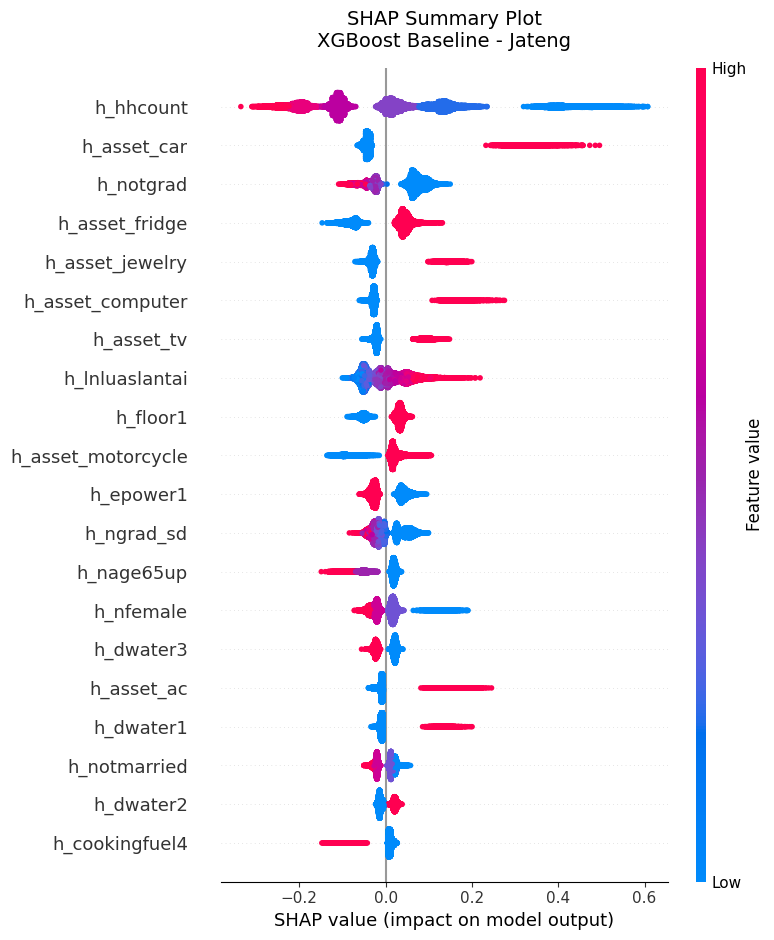


Memproses: XGBoost Baseline - DIY
  > Menghitung SHAP values...


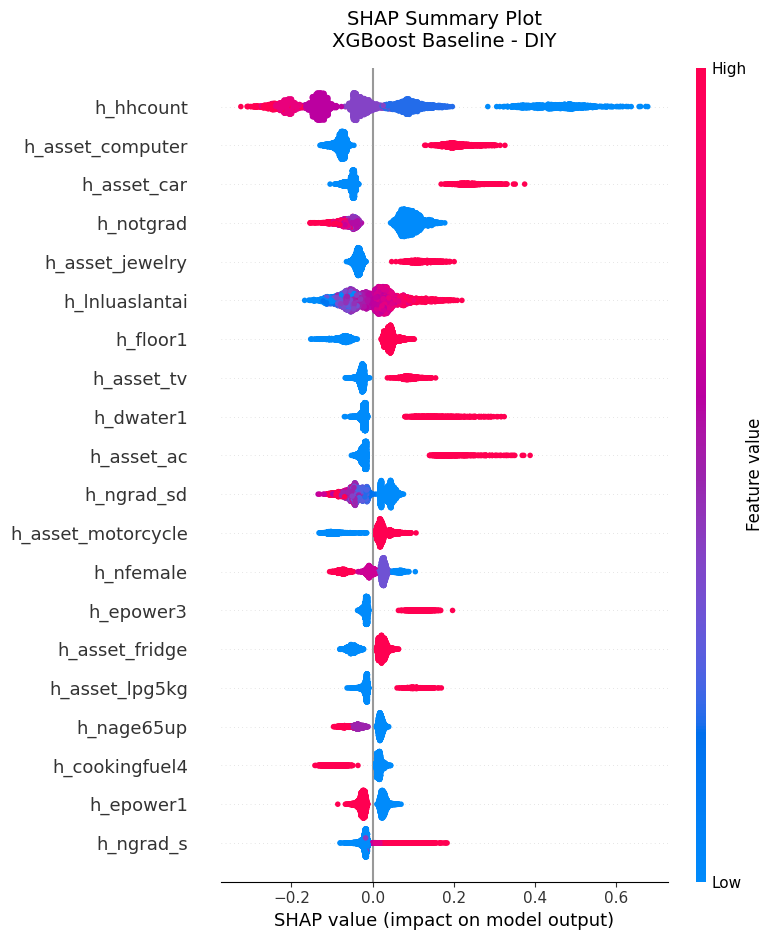


Memproses: XGBoost Citra - Jateng
  > Menghitung SHAP values...


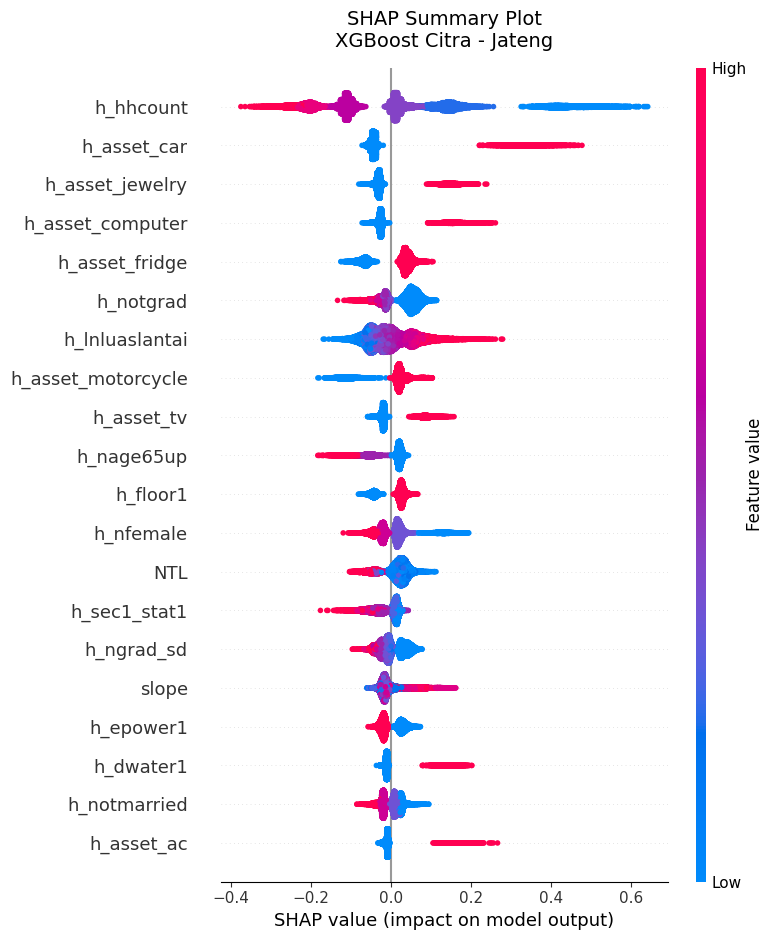


Memproses: XGBoost Citra - DIY
  > Menghitung SHAP values...


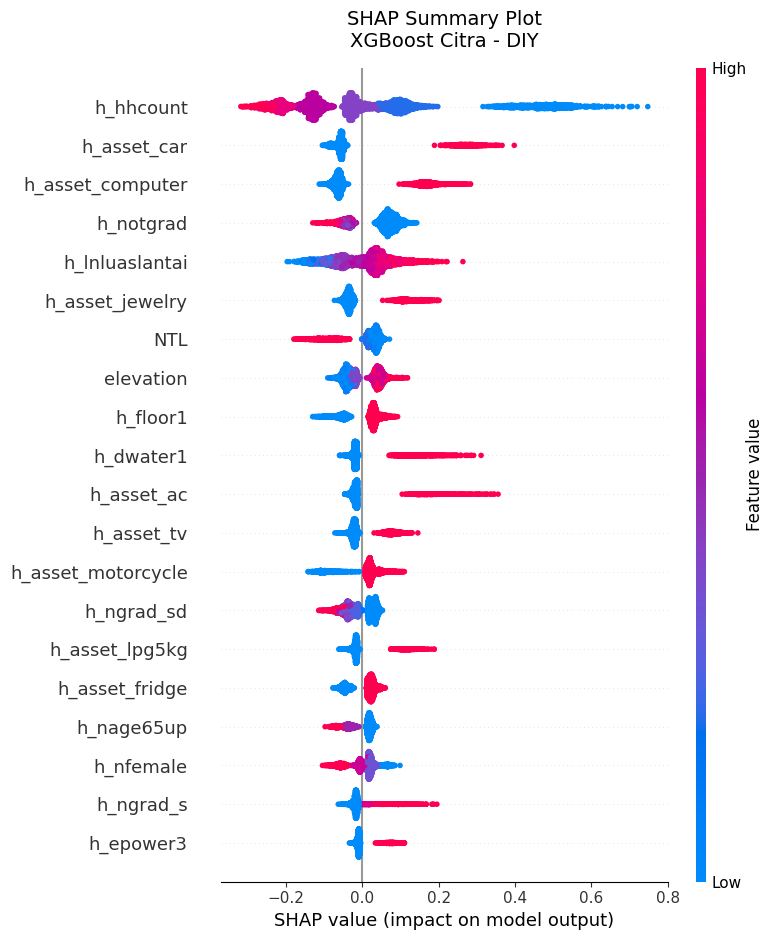


Memproses: GPBoost Multilevel (IPM) - Jateng
Finished loading model, total used 84 iterations
  > Menghitung SHAP values...


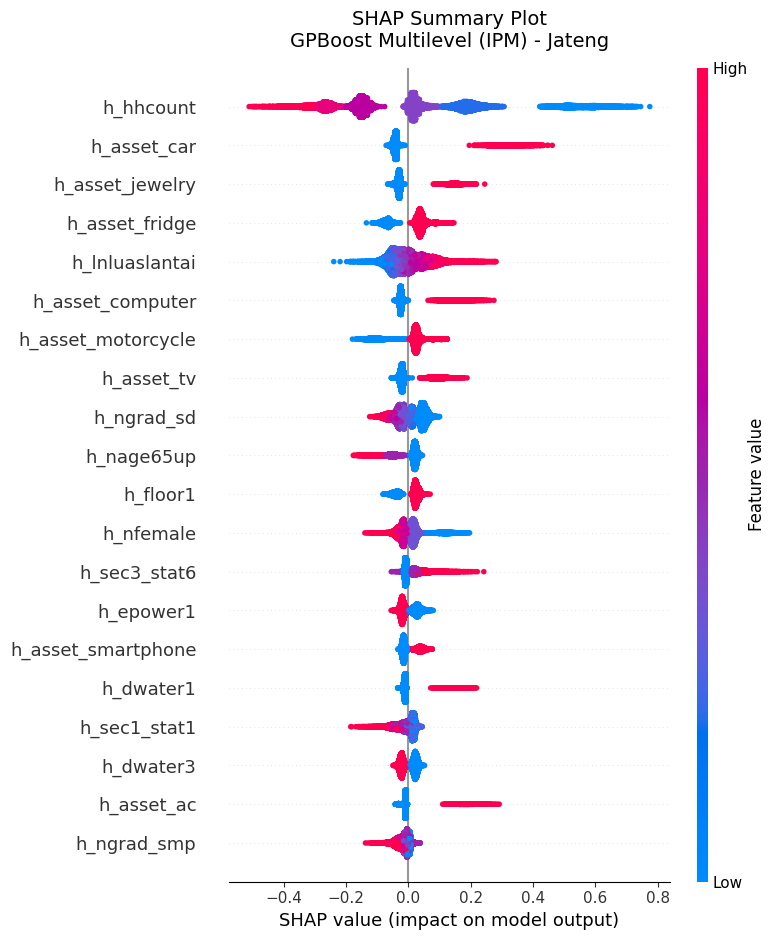


Memproses: GPBoost Multilevel (IPM) - DIY
Finished loading model, total used 27 iterations
  > Menghitung SHAP values...


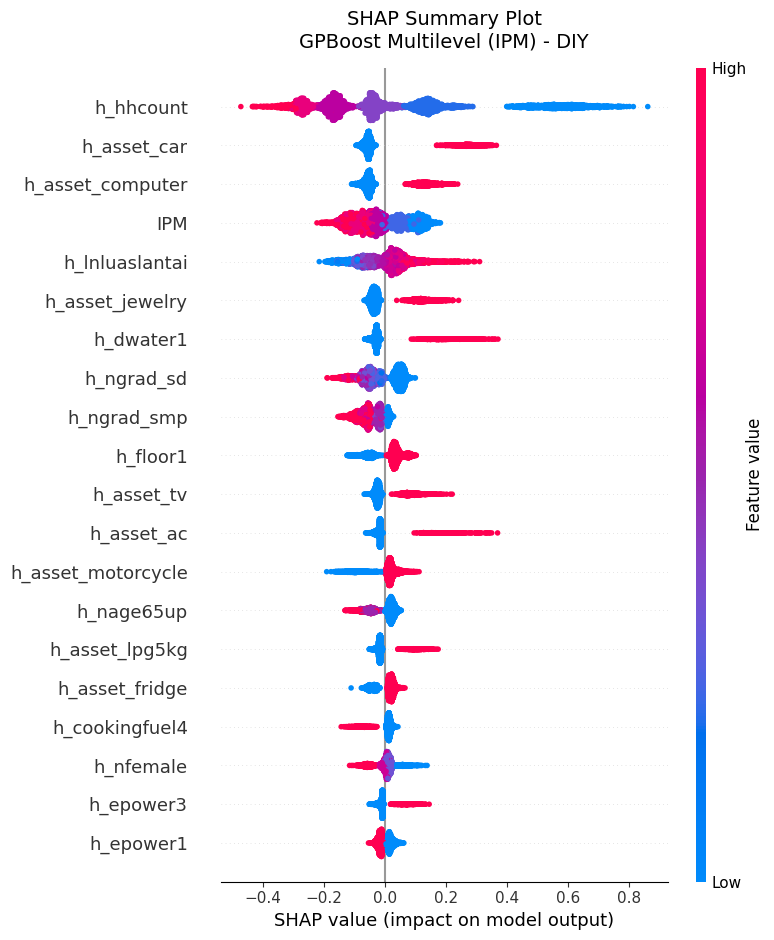


Memproses: GPBoost Multilevel Citra - Jateng
Finished loading model, total used 80 iterations
  > Menghitung SHAP values...


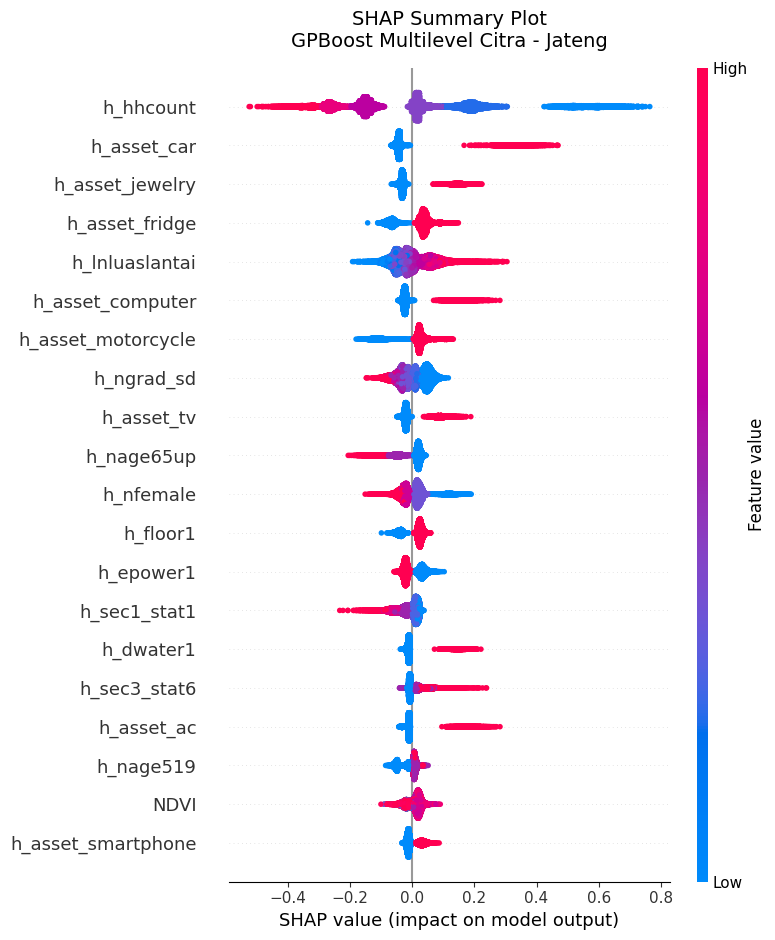


Memproses: GPBoost Multilevel Citra - DIY
Finished loading model, total used 28 iterations
  > Menghitung SHAP values...


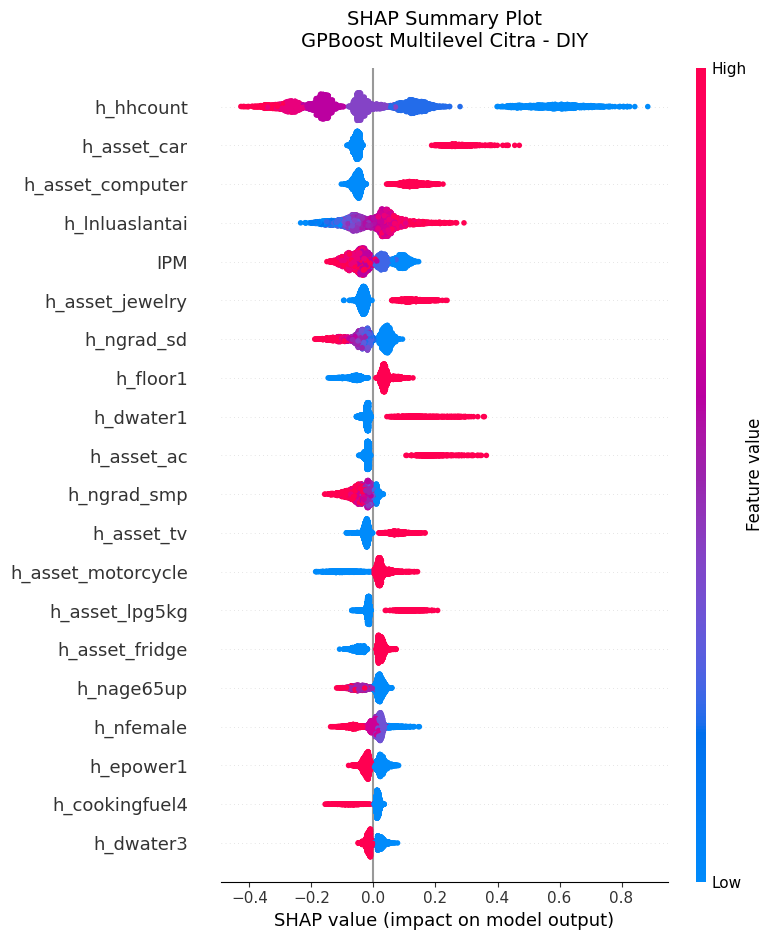


SELURUH ANALISIS SHAP SELESAI!


In [1]:
import pandas as pd
import numpy as np
import os
import joblib
import gpboost as gpb
import shap
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

# ==============================================================================
# 1. KONFIGURASI PATH & DATA TEST 2025
# ==============================================================================
work_dir = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/'
model_save_path = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Preprocessed/Models'
TEST_YEAR = 2025

# Load data test 2025
test_file = os.path.join(work_dir, f'susenas_final_{TEST_YEAR}.csv')
print(f"Memuat data test {TEST_YEAR} untuk SHAP Analysis...")
test_df = pd.read_csv(test_file)

# Pastikan tidak ada missing values
test_df = test_df.fillna(0)

# Cek apakah ada variasi nama kolom 'ipm' (huruf kecil/besar)
if 'ipm' in test_df.columns and 'IPM' not in test_df.columns:
    test_df.rename(columns={'ipm': 'IPM'}, inplace=True)

# Pisahkan berdasarkan kode provinsi (33: Jateng, 34: DIY)
test_jateng = test_df[test_df['kode_kab'] // 100 == 33].copy()
test_diy = test_df[test_df['kode_kab'] // 100 == 34].copy()

# ==============================================================================
# 2. LIST 8 MODEL DAN KONFIGURASINYA
# ==============================================================================
models_info = [
    # --- XGBOOST BASELINE (Aja) ---
    {'file': 'model_xgb_baseline_fix_Jawa_Tengah_Test2025.pkl', 'type': 'xgb', 'data': test_jateng, 'title': 'XGBoost Baseline - Jateng'},
    {'file': 'model_xgb_baseline_fix_DIY_Test2025.pkl', 'type': 'xgb', 'data': test_diy, 'title': 'XGBoost Baseline - DIY'},
    
    # --- XGBOOST CITRA ---
    {'file': 'model_xgb_baseline_citra_fix_Jateng_Test2025.pkl', 'type': 'xgb', 'data': test_jateng, 'title': 'XGBoost Citra - Jateng'},
    {'file': 'model_xgb_baseline_citra_fix_DIY_Test2025.pkl', 'type': 'xgb', 'data': test_diy, 'title': 'XGBoost Citra - DIY'},
    
    # --- GPBOOST MULTILEVEL (IPM) ---
    {'file': 'model_gpboost_multilevel_fix_Jateng_Test2025.json', 'type': 'gpb', 'data': test_jateng, 'title': 'GPBoost Multilevel (IPM) - Jateng'},
    {'file': 'model_gpboost_multilevel_fix_DIY_Test2025.json', 'type': 'gpb', 'data': test_diy, 'title': 'GPBoost Multilevel (IPM) - DIY'},
    
    # --- GPBOOST MULTILEVEL CITRA ---
    {'file': 'model_gpboost_multilevel_citra_fix_Jateng_Test2025.json', 'type': 'gpb', 'data': test_jateng, 'title': 'GPBoost Multilevel Citra - Jateng'},
    {'file': 'model_gpboost_multilevel_citra_fix_DIY_Test2025.json', 'type': 'gpb', 'data': test_diy, 'title': 'GPBoost Multilevel Citra - DIY'}
]

# ==============================================================================
# 3. LOOPING UNTUK MENGHITUNG & PLOTTING SHAP VALUES (AMBIL FITUR OTOMATIS)
# ==============================================================================
print("\n" + "="*70)
print("MEMULAI EKSTRAKSI SHAP VALUES UNTUK SEMUA MODEL (OTOMATIS FITUR)")
print("="*70)

for info in models_info:
    model_path = os.path.join(model_save_path, info['file'])
    
    print(f"\nMemproses: {info['title']}")
    
    if not os.path.exists(model_path):
        print(f"[GAGAL] File model tidak ditemukan: {info['file']}")
        continue
        
    try:
        if info['type'] == 'xgb':
            # Load XGBoost (.pkl)
            model = joblib.load(model_path)
            # Ambil nama fitur asli yang digunakan saat training model XGBoost ini
            model_features = model.feature_names_in_
            explainer = shap.TreeExplainer(model)
        else:
            # Load GPBoost (.json)
            model = gpb.Booster(model_file=model_path)
            # Ambil nama fitur asli dari booster LightGBM di dalam GPBoost
            model_features = model.feature_name()
            explainer = shap.TreeExplainer(model)
        
        # Filter data test hanya mengambil kolom yang sesuai dengan model tersebut
        X_test = info['data'][model_features]
        
        # Kalkulasi SHAP values
        print("  > Menghitung SHAP values...")
        shap_values = explainer.shap_values(X_test)
        
        # Membuat Plot
        plt.figure(figsize=(10, 6))
        shap.summary_plot(shap_values, X_test, max_display=20, show=False)
        plt.title(f"SHAP Summary Plot\n{info['title']}", fontsize=14, pad=15)
        plt.tight_layout()
        plt.show()
        
    except Exception as e:
        print(f"[ERROR] Terjadi kesalahan saat memproses {info['title']}: {e}")

print("\n" + "="*70)
print("SELURUH ANALISIS SHAP SELESAI!")
print("="*70)

# Tambahan

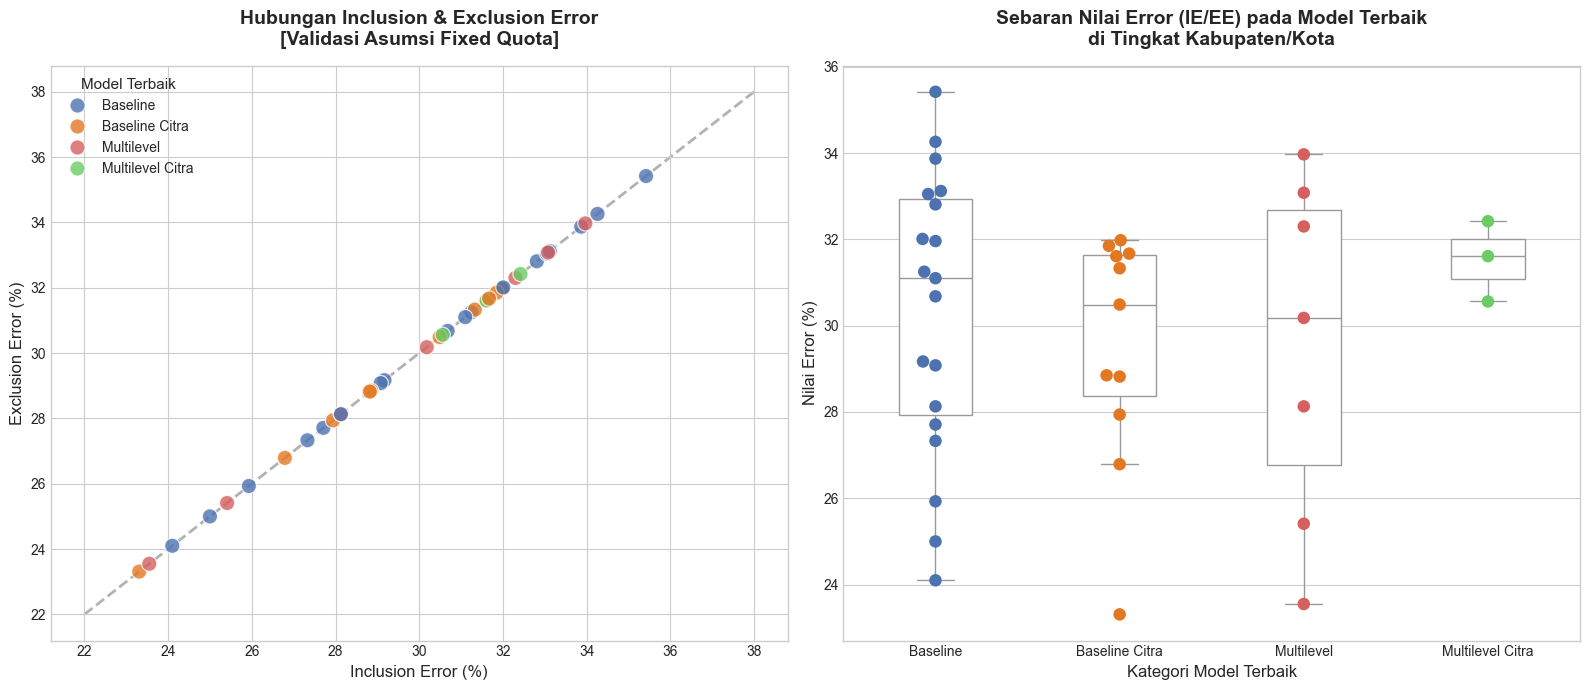


Distribusi Model Terbaik:
Model_Terbaik
Baseline            19
Baseline Citra      11
Multilevel           7
Multilevel Citra     3
Name: count, dtype: int64


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. DATA HARDCODE HASIL EKSTRAKSI TABEL (40 KABUPATEN/KOTA)
data = [
    {"Kab_Kota": "Cilacap", "Model_Terbaik": "Baseline", "IE": 32.81},
    {"Kab_Kota": "Banyumas", "Model_Terbaik": "Baseline", "IE": 29.17},
    {"Kab_Kota": "Purbalingga", "Model_Terbaik": "Baseline", "IE": 35.42},
    {"Kab_Kota": "Banjarnegara", "Model_Terbaik": "Baseline", "IE": 27.71},
    {"Kab_Kota": "Kebumen", "Model_Terbaik": "Baseline", "IE": 31.25},
    {"Kab_Kota": "Purworejo", "Model_Terbaik": "Baseline", "IE": 31.96},
    {"Kab_Kota": "Wonosobo", "Model_Terbaik": "Baseline", "IE": 34.26},
    {"Kab_Kota": "Magelang", "Model_Terbaik": "Baseline", "IE": 30.68},
    {"Kab_Kota": "Boyolali", "Model_Terbaik": "Baseline Citra", "IE": 27.94},
    {"Kab_Kota": "Klaten", "Model_Terbaik": "Multilevel", "IE": 32.30},
    {"Kab_Kota": "Sukoharjo", "Model_Terbaik": "Baseline", "IE": 24.10},
    {"Kab_Kota": "Wonogiri", "Model_Terbaik": "Baseline", "IE": 33.05},
    {"Kab_Kota": "Karanganyar", "Model_Terbaik": "Multilevel", "IE": 30.18},
    {"Kab_Kota": "Sragen", "Model_Terbaik": "Baseline Citra", "IE": 31.33},
    {"Kab_Kota": "Grobogan", "Model_Terbaik": "Baseline", "IE": 33.87},
    {"Kab_Kota": "Blora", "Model_Terbaik": "Baseline Citra", "IE": 30.49},
    {"Kab_Kota": "Rembang", "Model_Terbaik": "Baseline", "IE": 33.12},
    {"Kab_Kota": "Pati", "Model_Terbaik": "Multilevel Citra", "IE": 32.42},
    {"Kab_Kota": "Kudus", "Model_Terbaik": "Multilevel Citra", "IE": 30.56},
    {"Kab_Kota": "Jepara", "Model_Terbaik": "Baseline Citra", "IE": 31.61},
    {"Kab_Kota": "Demak", "Model_Terbaik": "Multilevel Citra", "IE": 31.61},
    {"Kab_Kota": "Semarang", "Model_Terbaik": "Baseline Citra", "IE": 31.98},
    {"Kab_Kota": "Temanggung", "Model_Terbaik": "Multilevel", "IE": 28.13},
    {"Kab_Kota": "Kendal", "Model_Terbaik": "Baseline Citra", "IE": 31.85},
    {"Kab_Kota": "Batang", "Model_Terbaik": "Baseline", "IE": 31.10},
    {"Kab_Kota": "Pekalongan", "Model_Terbaik": "Baseline", "IE": 32.01},
    {"Kab_Kota": "Pemalang", "Model_Terbaik": "Baseline Citra", "IE": 31.67},
    {"Kab_Kota": "Tegal", "Model_Terbaik": "Baseline", "IE": 29.08},
    {"Kab_Kota": "Brebes", "Model_Terbaik": "Multilevel", "IE": 33.08},
    {"Kab_Kota": "Kota Magelang", "Model_Terbaik": "Baseline", "IE": 25.93},
    {"Kab_Kota": "Kota Surakarta", "Model_Terbaik": "Baseline", "IE": 27.33},
    {"Kab_Kota": "Kota Salatiga", "Model_Terbaik": "Multilevel", "IE": 25.41},
    {"Kab_Kota": "Kota Semarang", "Model_Terbaik": "Baseline", "IE": 25.00},
    {"Kab_Kota": "Kota Pekalongan", "Model_Terbaik": "Baseline Citra", "IE": 28.85},
    {"Kab_Kota": "Kota Tegal", "Model_Terbaik": "Baseline", "IE": 28.13},
    {"Kab_Kota": "Kulon Progo", "Model_Terbaik": "Baseline Citra", "IE": 28.82},
    {"Kab_Kota": "Bantul", "Model_Terbaik": "Baseline Citra", "IE": 26.79},
    {"Kab_Kota": "Gunungkidul", "Model_Terbaik": "Multilevel", "IE": 33.97},
    {"Kab_Kota": "Sleman", "Model_Terbaik": "Baseline Citra", "IE": 23.31},
    {"Kab_Kota": "Kota Jogja", "Model_Terbaik": "Multilevel", "IE": 23.55}
]

df = pd.DataFrame(data)

# Karena menggunakan Fixed Quota, nilai EE identik dengan IE
df['EE'] = df['IE'] 

# Urutan Kategori Model agar konsisten di plot
model_order = ["Baseline", "Baseline Citra", "Multilevel", "Multilevel Citra"]

# Warna disesuaikan dengan warna tabel/highlight kamu
colors = {
    'Baseline': '#4C72B0',           # Biru
    'Baseline Citra': '#E37722',     # Oranye
    'Multilevel': '#D65F5F',         # Merah / Pink Gelap
    'Multilevel Citra': '#6ACC64'    # Hijau
}

# 2. KONFIGURASI VISUALISASI
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# --- PLOT 1: Scatter Plot Diagonal (IE vs EE) ---
sns.scatterplot(
    data=df, x='IE', y='EE', hue='Model_Terbaik', 
    palette=colors, s=120, alpha=0.8, ax=axes[0], hue_order=model_order
)
# Tambahkan Garis Diagonal (y=x)
axes[0].plot([22, 38], [22, 38], ls='--', color='gray', linewidth=2, alpha=0.6, zorder=0)

axes[0].set_title('Hubungan Inclusion & Exclusion Error\n[Validasi Asumsi Fixed Quota]', fontsize=14, fontweight='bold', pad=15)
axes[0].set_xlabel('Inclusion Error (%)', fontsize=12)
axes[0].set_ylabel('Exclusion Error (%)', fontsize=12)
axes[0].legend(title='Model Terbaik', title_fontsize=11, fontsize=10, loc='upper left')

# --- PLOT 2: Swarm Plot (Sebaran Nilai Error per Model) ---
# Boxplot transparan sebagai background untuk melihat rentang kuartil
sns.boxplot(
    data=df, x='Model_Terbaik', y='IE', 
    color='white', width=0.4, showfliers=False, ax=axes[1], order=model_order
)
# Swarmplot (titik data) di atas boxplot
sns.swarmplot(
    data=df, x='Model_Terbaik', y='IE', hue='Model_Terbaik', 
    palette=colors, size=9, ax=axes[1], order=model_order, legend=False
)

axes[1].set_title('Sebaran Nilai Error (IE/EE) pada Model Terbaik\ndi Tingkat Kabupaten/Kota', fontsize=14, fontweight='bold', pad=15)
axes[1].set_xlabel('Kategori Model Terbaik', fontsize=12)
axes[1].set_ylabel('Nilai Error (%)', fontsize=12)

# Rapikan layout dan simpan
plt.tight_layout()
plt.savefig('Scatter_Plot_IE_EE_Skripsi.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nDistribusi Model Terbaik:")
print(df['Model_Terbaik'].value_counts())

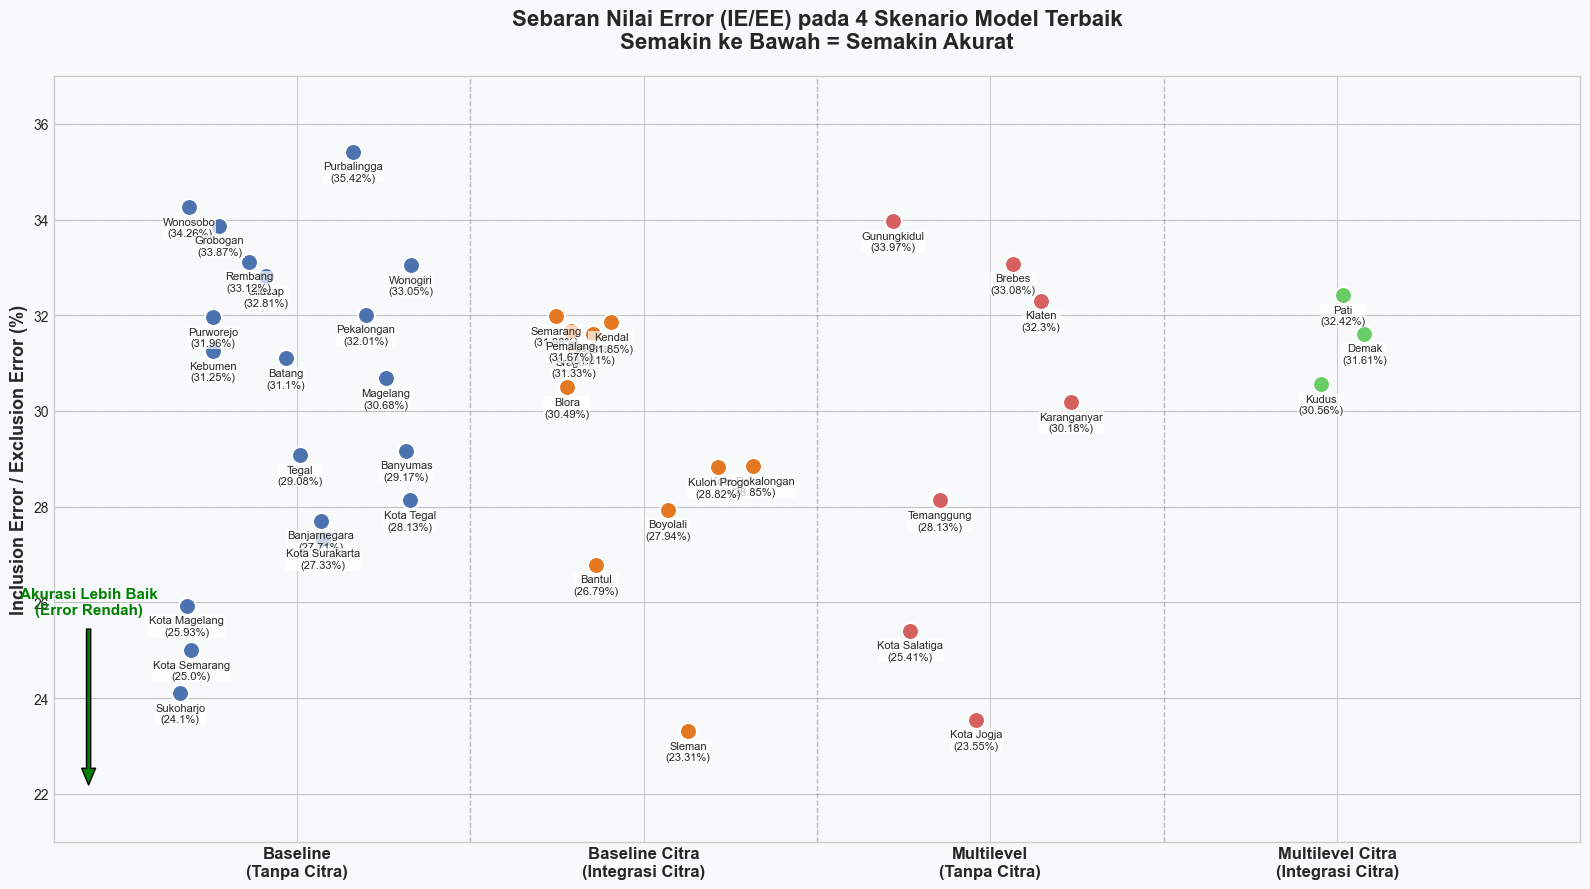

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. DATA HARDCODE HASIL EKSTRAKSI TABEL
data = [
    {"Kab_Kota": "Cilacap", "Model_Terbaik": "Baseline", "IE": 32.81},
    {"Kab_Kota": "Banyumas", "Model_Terbaik": "Baseline", "IE": 29.17},
    {"Kab_Kota": "Purbalingga", "Model_Terbaik": "Baseline", "IE": 35.42},
    {"Kab_Kota": "Banjarnegara", "Model_Terbaik": "Baseline", "IE": 27.71},
    {"Kab_Kota": "Kebumen", "Model_Terbaik": "Baseline", "IE": 31.25},
    {"Kab_Kota": "Purworejo", "Model_Terbaik": "Baseline", "IE": 31.96},
    {"Kab_Kota": "Wonosobo", "Model_Terbaik": "Baseline", "IE": 34.26},
    {"Kab_Kota": "Magelang", "Model_Terbaik": "Baseline", "IE": 30.68},
    {"Kab_Kota": "Boyolali", "Model_Terbaik": "Baseline Citra", "IE": 27.94},
    {"Kab_Kota": "Klaten", "Model_Terbaik": "Multilevel", "IE": 32.30},
    {"Kab_Kota": "Sukoharjo", "Model_Terbaik": "Baseline", "IE": 24.10},
    {"Kab_Kota": "Wonogiri", "Model_Terbaik": "Baseline", "IE": 33.05},
    {"Kab_Kota": "Karanganyar", "Model_Terbaik": "Multilevel", "IE": 30.18},
    {"Kab_Kota": "Sragen", "Model_Terbaik": "Baseline Citra", "IE": 31.33},
    {"Kab_Kota": "Grobogan", "Model_Terbaik": "Baseline", "IE": 33.87},
    {"Kab_Kota": "Blora", "Model_Terbaik": "Baseline Citra", "IE": 30.49},
    {"Kab_Kota": "Rembang", "Model_Terbaik": "Baseline", "IE": 33.12},
    {"Kab_Kota": "Pati", "Model_Terbaik": "Multilevel Citra", "IE": 32.42},
    {"Kab_Kota": "Kudus", "Model_Terbaik": "Multilevel Citra", "IE": 30.56},
    {"Kab_Kota": "Jepara", "Model_Terbaik": "Baseline Citra", "IE": 31.61},
    {"Kab_Kota": "Demak", "Model_Terbaik": "Multilevel Citra", "IE": 31.61},
    {"Kab_Kota": "Semarang", "Model_Terbaik": "Baseline Citra", "IE": 31.98},
    {"Kab_Kota": "Temanggung", "Model_Terbaik": "Multilevel", "IE": 28.13},
    {"Kab_Kota": "Kendal", "Model_Terbaik": "Baseline Citra", "IE": 31.85},
    {"Kab_Kota": "Batang", "Model_Terbaik": "Baseline", "IE": 31.10},
    {"Kab_Kota": "Pekalongan", "Model_Terbaik": "Baseline", "IE": 32.01},
    {"Kab_Kota": "Pemalang", "Model_Terbaik": "Baseline Citra", "IE": 31.67},
    {"Kab_Kota": "Tegal", "Model_Terbaik": "Baseline", "IE": 29.08},
    {"Kab_Kota": "Brebes", "Model_Terbaik": "Multilevel", "IE": 33.08},
    {"Kab_Kota": "Kota Magelang", "Model_Terbaik": "Baseline", "IE": 25.93},
    {"Kab_Kota": "Kota Surakarta", "Model_Terbaik": "Baseline", "IE": 27.33},
    {"Kab_Kota": "Kota Salatiga", "Model_Terbaik": "Multilevel", "IE": 25.41},
    {"Kab_Kota": "Kota Semarang", "Model_Terbaik": "Baseline", "IE": 25.00},
    {"Kab_Kota": "Kota Pekalongan", "Model_Terbaik": "Baseline Citra", "IE": 28.85},
    {"Kab_Kota": "Kota Tegal", "Model_Terbaik": "Baseline", "IE": 28.13},
    {"Kab_Kota": "Kulon Progo", "Model_Terbaik": "Baseline Citra", "IE": 28.82},
    {"Kab_Kota": "Bantul", "Model_Terbaik": "Baseline Citra", "IE": 26.79},
    {"Kab_Kota": "Gunungkidul", "Model_Terbaik": "Multilevel", "IE": 33.97},
    {"Kab_Kota": "Sleman", "Model_Terbaik": "Baseline Citra", "IE": 23.31},
    {"Kab_Kota": "Kota Jogja", "Model_Terbaik": "Multilevel", "IE": 23.55}
]

df = pd.DataFrame(data)

# 2. DEFINISI POSISI SUMBU X UNTUK KE-4 MODEL
x_centers = {
    'Baseline': 1,
    'Baseline Citra': 2,
    'Multilevel': 3,
    'Multilevel Citra': 4
}

colors = {
    'Baseline': '#4C72B0',           # Biru
    'Baseline Citra': '#E37722',     # Oranye
    'Multilevel': '#D65F5F',         # Merah
    'Multilevel Citra': '#6ACC64'    # Hijau
}

# Sumbu Y murni menggunakan angka IE.
# Sumbu X diberi sedikit acakan (horizontal jitter) HANYA ke samping, agar titik berdekatan tidak menumpuk
np.random.seed(42)
df['x_base'] = df['Model_Terbaik'].map(x_centers)
df['x'] = df['x_base'] + np.random.uniform(-0.35, 0.35, len(df))
df['y'] = df['IE'] # <--- POSISI Y SEKARANG 100% BERDASARKAN NILAI ERROR

# 3. KONFIGURASI VISUALISASI
fig, ax = plt.subplots(figsize=(16, 9))
ax.set_facecolor('#F8F9FA')
fig.patch.set_facecolor('#F8F9FA')

# Menggambar batas antar model (garis vertikal pemisah)
for i in [1.5, 2.5, 3.5]:
    ax.axvline(i, color='gray', linewidth=1, linestyle='--', alpha=0.5)

# Background belang-belang horizontal untuk memudahkan baca nilai IE
for y_grid in range(22, 38, 2):
    ax.axhline(y_grid, color='gray', linewidth=0.5, linestyle=':', alpha=0.5)

# Menempatkan titik scatter plot (koordinat Y murni IE)
for model in x_centers.keys():
    subset = df[df['Model_Terbaik'] == model]
    ax.scatter(subset['x'], subset['y'], s=150, c=colors[model], 
               label=model, edgecolors='white', linewidth=1.5, zorder=5)

# Menambahkan teks nama kabupaten
for i, row in df.iterrows():
    ax.text(row['x'], row['y'] - 0.2, f"{row['Kab_Kota']}\n({row['IE']}%)", 
            fontsize=8, ha='center', va='top', zorder=6,
            bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=0.5))

# 4. LABEL DAN TIPOGRAFI
ax.set_xlim(0.3, 4.7)
ax.set_ylim(21, 37) # Rentang nilai IE (sekitar 23% sampai 36%)

# Menyesuaikan Sumbu X
ax.set_xticks([1, 2, 3, 4])
ax.set_xticklabels(['Baseline\n(Tanpa Citra)', 'Baseline Citra\n(Integrasi Citra)', 
                    'Multilevel\n(Tanpa Citra)', 'Multilevel Citra\n(Integrasi Citra)'], 
                   fontsize=12, fontweight='bold')

# Sumbu Y dengan kebalikan arah panah (Karena Error rendah lebih baik)
ax.set_ylabel('Inclusion Error / Exclusion Error (%)', fontsize=13, fontweight='bold')
ax.set_title('Sebaran Nilai Error (IE/EE) pada 4 Skenario Model Terbaik\nSemakin ke Bawah = Semakin Akurat', 
             fontsize=16, fontweight='bold', pad=20)

# Tambahkan panah penunjuk (Arah ke bawah = Lebih Baik)
ax.annotate('Akurasi Lebih Baik\n(Error Rendah)', xy=(0.4, 22), xytext=(0.4, 26),
            arrowprops=dict(facecolor='green', shrink=0.05, width=3, headwidth=10),
            fontsize=11, fontweight='bold', color='green', ha='center', va='center')

plt.tight_layout()
plt.savefig('Scatter_Plot_Error_Asli_Skripsi.png', dpi=300, bbox_inches='tight')
plt.show()

In [8]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# 1. DATA HASIL EVALUASI (Gunakan data dari DataFrame sebelumnya)
# df = pd.DataFrame(data) # Pastikan dataframe 'df' yang berisi kolom 'Kab_Kota' dan 'Model_Terbaik' sudah di-load

# 2. LOAD SHAPEFILE PETA JATENG & DIY
# Ganti dengan path file .shp peta kabupaten/kota Jawa Tengah & DIY milikmu
shp_path = '/Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Spatial_Data/peta_jateng_diy.shp' 
gdf = gpd.read_file(shp_path)

# 3. MERGE DATA PETA DENGAN DATA EXCEL
# Pastikan nama kolom wilayah di SHP (misal: 'KABKOT') cocok dengan kolom 'Kab_Kota' di df
# Jika ada perbedaan penulisan (misal "Kabupaten Cilacap" vs "Cilacap"), lakukan penyesuaian string terlebih dahulu
gdf_merged = gdf.merge(df, left_on='KABKOT', right_on='Kab_Kota', how='left')

# 4. KONFIGURASI WARNA KATEGORIKAL (Sama dengan scatter plot)
color_dict = {
    'Baseline': '#4C72B0',           # Biru
    'Baseline Citra': '#E37722',     # Oranye
    'Multilevel': '#D65F5F',         # Merah
    'Multilevel Citra': '#6ACC64'    # Hijau
}

# 5. VISUALISASI PETA CHOROPLETH
fig, ax = plt.subplots(1, 1, figsize=(16, 10))
ax.set_facecolor('#F8F9FA')
fig.patch.set_facecolor('#F8F9FA')

# Plotting setiap kategori model
for ctype, data_group in gdf_merged.groupby('Model_Terbaik'):
    color = color_dict[ctype]
    data_group.plot(color=color, ax=ax, edgecolor='white', linewidth=0.8)

# Menghilangkan axis (garis tepi peta koordinat)
ax.axis('off')

# Menambahkan Judul
plt.title('Peta Distribusi Spasial Skenario Model Penargetan Kemiskinan Terbaik\nJawa Tengah dan DIY', 
          fontsize=18, fontweight='bold', pad=20)

# Membuat Legenda Kustom
legend_elements = [Patch(facecolor=color_dict[k], edgecolor='white', label=k) for k in color_dict.keys()]
ax.legend(handles=legend_elements, loc='lower left', title='Kategori Model Terbaik', 
          fontsize=12, title_fontsize=14, frameon=True, facecolor='white', framealpha=0.9)

# (Opsional) Menambahkan Teks Label Kabupaten di atas Peta
for idx, row in gdf_merged.iterrows():
    if pd.notnull(row['Model_Terbaik']): # Hanya beri teks jika data match
        # Mengambil titik tengah (centroid) dari polygon untuk menaruh teks
        plt.annotate(text=row['Kab_Kota'], 
                     xy=(row.geometry.centroid.x, row.geometry.centroid.y),
                     horizontalalignment='center', fontsize=6, color='black',
                     bbox=dict(facecolor='white', alpha=0.5, edgecolor='none', pad=0.5))

plt.tight_layout()
plt.savefig('Peta_Choropleth_Model_Terbaik.png', dpi=300, bbox_inches='tight')
plt.show()

DriverError: /Users/kvnananda/Desktop/KULIAH/SEM7/SKRIPSI/Spatial_Data/peta_jateng_diy.shp: No such file or directory